# nb09 — scMKL-style RNA + ATAC integration

**Prepared for you to run in Colab. This notebook has not been executed.**

Train **one RNA + ATAC grouped-kernel model for MCF7 and one for T47D**.
There is no unimodal kernel training and no hyperparameter search.
Compare the two integrated models with the saved nb08 MLP baselines. Reuse the exact nb08 training, validation and
test cells, input data and training-selected features. E2 is always the positive class.

This is an **scMKL-style implementation**, not the official scMKL package and not an exact
reproduction of the published benchmark. It retains the central design: biological feature
groups, Gaussian random Fourier feature maps, and group-lasso regression for binary prediction.
See the method and differences below.

**Colab runtime:** the celer solver and motif scanning use CPU. A GPU is not required and will
not accelerate this solver. A high-RAM runtime is helpful; do not keep other large notebooks
running in the same session. Model construction uses disk-backed arrays and runs one cell line
at a time. Dependencies, definitions and references are embedded; no repository upload is needed.

**Inputs on Drive**
- The four nb02 RNA/paired-ATAC QC H5AD files.
- The complete nb08 results folder for run **20261011T103750_408739Z**, including its config,
  split manifests, handoff, input fingerprints, selected features and test predictions.
- nb07 genome/JASPAR/blacklist references, if already present. Missing references download
  automatically with checksum verification; the hg38 genome is approximately 835 MB.

If you only have the nb08 results ZIP, extract its contents into
results/tables/nb08/20261011T103750_408739Z/ under the Drive project before starting.
Set NB08_RUN_ID explicitly below if you intend to use a different completed run.


## Model and comparison plan

1. Verify nb08 input fingerprints, paired cell identities and immutable split manifests.
   Read its actual settings, including your MLP learning rate of 0.00001; do not retrain the MLP.
2. Recompute nb08's training-only selection of up to 5,000 features and require an exact
   match to its saved feature IDs. RNA uses log1p counts and training centering/scaling;
   ATAC uses binary peak accessibility.
3. **RNA kernels:** one per usable frozen MSigDB Hallmark v7 gene set.
   **ATAC kernels:** one per usable JASPAR2024 motif's peak set. Scan the training-selected peaks
   afresh; do not use DEG, DA, GSEA or motif-enrichment significance to choose groups.
4. Keep groups with at least five features. Collapse groups with identical feature membership;
   save aliases and all coverage exclusions. Blacklisted, nonstandard or ambiguous ATAC sequences
   are excluded from motif groups.
5. For each group, estimate a Gaussian bandwidth using the median positive pairwise distance
   among up to 256 **training cells**. Use 32 random frequencies, giving 64 cosine/sine features.
   Center and normalize each block using training cells to give comparable kernel scales.
6. Fit group lasso once per cell line to joint RNA + ATAC, using Vehicle = -1, E2 = +1.
   Fix alpha ratio at **0.1**, motivated by the best recorded setting in the interrupted MCF7 ATAC
   search. This is a starting setting, not a demonstrated optimum for either integrated model.
7. Report validation performance diagnostically; do not search or refit on validation.
   Require convergence before test evaluation. Report raw-score AUROC/AP and threshold-zero metrics.

The Gaussian kernel is k(x,z) = exp(-||x-z||² / (2σ²)). Each group's feature map is
[cos(xW), sin(xW)] / sqrt(D), with W sampled from N(0, 1/σ²).

The objective is squared error / (2n) + alpha × sum of coefficient-block L2 norms.
Alpha is fixed at 0.1 times the training-only group-lasso alpha maximum.
**There is no MLP learning rate or neural-network epoch training in this notebook.**
Uncalibrated regression scores are saved as decision scores, not probabilities; therefore
log loss/Brier scores are not compared with nb08.


## Provenance, adaptations and limits

The [authors' scMKL source](https://github.com/ohsu-cedar-comp-hub/scMKL/tree/d6448b73895ab62b31f78213f6e4fed910bce4c4)
uses random Fourier features and
[celer group lasso](https://mathurinm.github.io/celer/generated/celer.GroupLasso.html).
The [paper](https://doi.org/10.1038/s42003-025-08533-7) provides the scientific reference.

This notebook implements that core approach independently, with explicit adaptations:
nb08's existing feature set/preprocessing; fixed 32-frequency Gaussian approximation; positive-distance
median bandwidths; training-centered, unit-average-energy blocks; a group-norm alpha maximum;
a fixed alpha rather than repeated nested cross-validation; and JASPAR2024 motif annotation.
It does not claim numerical equivalence with scMKL or reproduce its published scores.

Peak coordinate origin remains unresolved. A motif is admitted only when present under **both**
0-based half-open and 1-based closed interpretations; all boundary-sensitive hits are counted.
This conservative choice does not resolve the coordinate convention or demonstrate TF binding.

Group coefficient norms describe predictive contributions within correlated, overlapping groups.
They are not pathway activation scores, causal effects, or percentages of biological contribution.
Identical membership groups share a representative; no particular TF within a motif family is established.

The comparison is exploratory: biological replicate IDs are unavailable and library effects may
track treatment. nb08 test results have already been inspected. If the learning rate was chosen using
test performance, those cells are no longer an untouched final evaluation set; preserve this comparison
for continuity, but reserve independent data for a confirmatory performance claim.
Comparisons with nb08 change both model family and input modalities; they do not isolate integration alone.


In [2]:
# Install missing runtime packages. No notebook model is fitted in this cell.
import importlib.util
import subprocess
import sys
packages = {
    "anndata":"anndata>=0.11,<0.13","h5py":"h5py","numpy":"numpy","pandas":"pandas",
    "scipy":"scipy","sklearn":"scikit-learn","matplotlib":"matplotlib",
    "celer":"celer>=0.7.4,<0.8","MOODS":"MOODS-python==1.9.4.1","py2bit":"py2bit==0.3.3",
}
missing=[spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import os
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen")
else:
    here=Path.cwd()
    BASE=Path(os.environ.get("MULTIOME_PROJECT_ROOT",
              str(here.parent if here.name=="notebooks" else here)))

NB08_RUN_ID="20261011T103750_408739Z"
# Leave blank for the first run of this revised notebook.
# After a disconnect, set this to the NEW integrated run ID printed below.
RESUME_RUN_ID="20261012T114858_335840Z"
# Reuse completed kernels from the interrupted run; keep that folder on Drive.
CACHED_KERNEL_RUN_ID="20261012T085524_321769Z"
RUN_ID=RESUME_RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
print("Project:",BASE)
print("nb08 comparison run:",NB08_RUN_ID)
print("New nb09 run:",RUN_ID)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/breast-cancer-multiome-estrogen
nb08 comparison run: 20261011T103750_408739Z
New nb09 run: 20261012T114858_335840Z


## Settings and frozen references
Choose settings before setup. Do not change them after looking at test results.
The dictionaries below embed the existing project references; no label-based enrichment filtering
is applied. The number of retained groups is determined by training-selected feature coverage.


In [4]:
CONFIG = {'cell_lines': ['MCF7', 'T47D'], 'seed': 42, 'rff_frequencies': 32, 'min_group_features': 5, 'bandwidth_sample_cells': 256, 'alpha_ratios': [0.1], 'solver_tolerance': 0.0001, 'solver_max_iter': 200, 'solver_max_epochs': 50000, 'max_design_gib': 3.0, 'coordinate_policy': 'motif present under both coordinate hypotheses', 'model_name': 'scMKL-style Gaussian RFF + group lasso', 'author_source_commit': 'd6448b73895ab62b31f78213f6e4fed910bce4c4'}
CONFIG

{'cell_lines': ['MCF7', 'T47D'],
 'seed': 42,
 'rff_frequencies': 32,
 'min_group_features': 5,
 'bandwidth_sample_cells': 256,
 'alpha_ratios': [0.1],
 'solver_tolerance': 0.0001,
 'solver_max_iter': 200,
 'solver_max_epochs': 50000,
 'max_design_gib': 3.0,
 'coordinate_policy': 'motif present under both coordinate hypotheses',
 'model_name': 'scMKL-style Gaussian RFF + group lasso',
 'author_source_commit': 'd6448b73895ab62b31f78213f6e4fed910bce4c4'}

In [5]:
HALLMARK = {'version': 'MSigDB v7.0 (frozen; same release as nb03)', 'url': 'https://raw.githubusercontent.com/broadinstitute/ssGSEA2.0/master/db/msigdb/h.all.v7.0.symbols.gmt', 'sha256': '4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516', 'gene_sets': {'HALLMARK_TNFA_SIGNALING_VIA_NFKB': ['JUNB', 'CXCL2', 'ATF3', 'NFKBIA', 'TNFAIP3', 'PTGS2', 'CXCL1', 'IER3', 'CD83', 'CCL20', 'CXCL3', 'MAFF', 'NFKB2', 'TNFAIP2', 'HBEGF', 'KLF6', 'BIRC3', 'PLAUR', 'ZFP36', 'ICAM1', 'JUN', 'EGR3', 'IL1B', 'BCL2A1', 'PPP1R15A', 'ZC3H12A', 'SOD2', 'NR4A2', 'IL1A', 'RELB', 'TRAF1', 'BTG2', 'DUSP1', 'MAP3K8', 'ETS2', 'F3', 'SDC4', 'EGR1', 'IL6', 'TNF', 'KDM6B', 'NFKB1', 'LIF', 'PTX3', 'FOSL1', 'NR4A1', 'JAG1', 'CCL4', 'GCH1', 'CCL2', 'RCAN1', 'DUSP2', 'EHD1', 'IER2', 'REL', 'CFLAR', 'RIPK2', 'NFKBIE', 'NR4A3', 'PHLDA1', 'IER5', 'TNFSF9', 'GEM', 'GADD45A', 'CXCL10', 'PLK2', 'BHLHE40', 'EGR2', 'SOCS3', 'SLC2A6', 'PTGER4', 'DUSP5', 'SERPINB2', 'NFIL3', 'SERPINE1', 'TRIB1', 'TIPARP', 'RELA', 'BIRC2', 'CXCL6', 'LITAF', 'TNFAIP6', 'CD44', 'INHBA', 'PLAU', 'MYC', 'TNFRSF9', 'SGK1', 'TNIP1', 'NAMPT', 'FOSL2', 'PNRC1', 'ID2', 'CD69', 'IL7R', 'EFNA1', 'PHLDA2', 'PFKFB3', 'CCL5', 'YRDC', 'IFNGR2', 'SQSTM1', 'BTG3', 'GADD45B', 'KYNU', 'G0S2', 'BTG1', 'MCL1', 'VEGFA', 'MAP2K3', 'CDKN1A', 'CCN1', 'TANK', 'IFIT2', 'IL18', 'TUBB2A', 'IRF1', 'FOS', 'OLR1', 'RHOB', 'AREG', 'NINJ1', 'ZBTB10', 'PLPP3', 'KLF4', 'CXCL11', 'SAT1', 'CSF1', 'GPR183', 'PMEPA1', 'PTPRE', 'TLR2', 'ACKR3', 'KLF10', 'MARCKS', 'LAMB3', 'CEBPB', 'TRIP10', 'F2RL1', 'KLF9', 'LDLR', 'TGIF1', 'RNF19B', 'DRAM1', 'B4GALT1', 'DNAJB4', 'CSF2', 'PDE4B', 'SNN', 'PLEK', 'STAT5A', 'DENND5A', 'CCND1', 'DDX58', 'SPHK1', 'CD80', 'TNFAIP8', 'CCNL1', 'FUT4', 'CCRL2', 'SPSB1', 'TSC22D1', 'B4GALT5', 'SIK1', 'CLCF1', 'NFE2L2', 'FOSB', 'AC129492.1', 'NFAT5', 'ATP2B1', 'IL12B', 'IL6ST', 'SLC16A6', 'ABCA1', 'HES1', 'BCL6', 'IRS2', 'SLC2A3', 'CEBPD', 'IL23A', 'SMAD3', 'TAP1', 'MSC', 'IFIH1', 'IL15RA', 'TNIP2', 'BCL3', 'PANX1', 'FJX1', 'EDN1', 'EIF1', 'BMP2', 'DUSP4', 'PDLIM5', 'ICOSLG', 'GFPT2', 'KLF2', 'TNC', 'SERPINB8', 'MXD1'], 'HALLMARK_HYPOXIA': ['PGK1', 'PDK1', 'GBE1', 'PFKL', 'ALDOA', 'ENO2', 'PGM1', 'NDRG1', 'HK2', 'ALDOC', 'GPI', 'MXI1', 'SLC2A1', 'P4HA1', 'ADM', 'P4HA2', 'ENO1', 'PFKP', 'AK4', 'FAM162A', 'PFKFB3', 'VEGFA', 'BNIP3L', 'TPI1', 'ERO1A', 'KDM3A', 'CCNG2', 'LDHA', 'GYS1', 'GAPDH', 'BHLHE40', 'ANGPTL4', 'JUN', 'SERPINE1', 'LOX', 'GCK', 'PPFIA4', 'MAFF', 'DDIT4', 'SLC2A3', 'IGFBP3', 'NFIL3', 'FOS', 'RBPJ', 'HK1', 'CITED2', 'ISG20', 'GALK1', 'WSB1', 'PYGM', 'STC1', 'ZNF292', 'BTG1', 'PLIN2', 'CSRP2', 'VLDLR', 'JMJD6', 'EXT1', 'F3', 'PDK3', 'ANKZF1', 'UGP2', 'ALDOB', 'STC2', 'ERRFI1', 'ENO3', 'PNRC1', 'HMOX1', 'PGF', 'GAPDHS', 'CHST2', 'TMEM45A', 'BCAN', 'ATF3', 'CAV1', 'AMPD3', 'GPC3', 'NDST1', 'IRS2', 'SAP30', 'GAA', 'SDC4', 'STBD1', 'IER3', 'PKLR', 'IGFBP1', 'PLAUR', 'CAVIN3', 'CCN5', 'LARGE1', 'NOCT', 'S100A4', 'RRAGD', 'ZFP36', 'EGFR', 'EDN2', 'IDS', 'CDKN1A', 'RORA', 'DUSP1', 'MIF', 'PPP1R3C', 'DPYSL4', 'KDELR3', 'DTNA', 'ADORA2B', 'HS3ST1', 'CAVIN1', 'NR3C1', 'KLF6', 'GPC4', 'CCN1', 'TNFAIP3', 'CA12', 'HEXA', 'BGN', 'PPP1R15A', 'PGM2', 'PIM1', 'PRDX5', 'NAGK', 'CDKN1B', 'BRS3', 'TKTL1', 'MT1E', 'ATP7A', 'MT2A', 'SDC3', 'TIPARP', 'PKP1', 'ANXA2', 'PGAM2', 'DDIT3', 'PRKCA', 'SLC37A4', 'CXCR4', 'EFNA3', 'CP', 'KLF7', 'CCN2', 'CHST3', 'TPD52', 'LXN', 'B4GALNT2', 'PPARGC1A', 'BCL2', 'GCNT2', 'HAS1', 'KLHL24', 'SCARB1', 'SLC25A1', 'SDC2', 'CASP6', 'VHL', 'FOXO3', 'PDGFB', 'B3GALT6', 'SLC2A5', 'SRPX', 'EFNA1', 'GLRX', 'ACKR3', 'PAM', 'TGFBI', 'DCN', 'SIAH2', 'PLAC8', 'FBP1', 'TPST2', 'PHKG1', 'MYH9', 'CDKN1C', 'GRHPR', 'PCK1', 'INHA', 'HSPA5', 'NDST2', 'NEDD4L', 'TPBG', 'XPNPEP1', 'IL6', 'SLC6A6', 'MAP3K1', 'LDHC', 'AKAP12', 'TES', 'KIF5A', 'LALBA', 'COL5A1', 'GPC1', 'HDLBP', 'ILVBL', 'NCAN', 'TGM2', 'ETS1', 'HOXB9', 'SELENBP1', 'FOSL2', 'SULT2B1', 'TGFB3'], 'HALLMARK_CHOLESTEROL_HOMEOSTASIS': ['FDPS', 'CYP51A1', 'IDI1', 'FDFT1', 'DHCR7', 'SQLE', 'HMGCS1', 'NSDHL', 'LSS', 'MVD', 'LDLR', 'TM7SF2', 'ALDOC', 'EBP', 'SCD', 'PMVK', 'MVK', 'LPL', 'SC5D', 'FADS2', 'HMGCR', 'HSD17B7', 'ANXA13', 'SREBF2', 'PCYT2', 'ACSS2', 'ATF3', 'ADH4', 'ETHE1', 'ECH1', 'CBS', 'GUSB', 'FASN', 'LGALS3', 'ATF5', 'ANXA5', 'TP53INP1', 'CHKA', 'GSTM2', 'ACAT2', 'AVPR1A', 'PLSCR1', 'CLU', 'ERRFI1', 'TRIB3', 'CXCL16', 'TNFRSF12A', 'ACTG1', 'JAG1', 'LGMN', 'FBXO6', 'GPX8', 'PNRC1', 'ANTXR2', 'MAL2', 'CD9', 'PPARG', 'GLDC', 'STX5', 'STARD4', 'CTNNB1', 'TMEM97', 'FAM129A', 'PDK3', 'PLAUR', 'SEMA3B', 'GNAI1', 'ABCA2', 'ATXN2', 'NFIL3', 'ALCAM', 'FABP5', 'S100A11', 'CPEB2'], 'HALLMARK_MITOTIC_SPINDLE': ['ARHGEF2', 'CLASP1', 'KIF11', 'AC027237.1', 'ALS2', 'ARF6', 'MYO9B', 'MYH9', 'TUBGCP3', 'CKAP5', 'RACGAP1', 'PREX1', 'ARHGEF3', 'NUMA1', 'SPTBN1', 'KIF2C', 'KIF5B', 'TTK', 'APC', 'CEP250', 'PAFAH1B1', 'CDC42EP2', 'KIF3B', 'CCDC88A', 'KIF15', 'BIRC5', 'CNTROB', 'NF1', 'TSC1', 'CDC27', 'CNTRL', 'TUBGCP5', 'KIF4A', 'MAPRE1', 'FGD6', 'BRCA2', 'PLK1', 'RASA1', 'NEK2', 'WASF1', 'TOP2A', 'TRIO', 'ARHGEF11', 'KATNB1', 'PRC1', 'ANLN', 'CDK5RAP2', 'SMC3', 'TUBGCP2', 'ESPL1', 'MAP1S', 'ARHGAP27', 'DOCK4', 'SAC3D1', 'INCENP', 'ARHGAP5', 'GSN', 'NET1', 'LRPPRC', 'RABGAP1', 'FLNB', 'ARAP3', 'FGD4', 'ABR', 'CENPJ', 'NCK1', 'CENPF', 'KIF20B', 'WASF2', 'MYH10', 'CENPE', 'CYTH2', 'MID1', 'KLC1', 'MARK4', 'ARL8A', 'CEP57', 'UXT', 'ARHGAP4', 'CDC42EP4', 'SASS6', 'LATS1', 'OPHN1', 'WASL', 'MAP3K11', 'SOS1', 'ABL1', 'TIAM1', 'KIF1B', 'ITSN1', 'SHROOM1', 'NCK2', 'DLGAP5', 'BCR', 'RANBP9', 'EPB41L2', 'SEPT9', 'KATNA1', 'TUBD1', 'TPX2', 'KIF3C', 'SHROOM2', 'TUBGCP6', 'SPTAN1', 'PALLD', 'ARFIP2', 'KNTC1', 'HOOK3', 'SUN2', 'MID1IP1', 'DLG1', 'FLNA', 'ARHGAP10', 'CDC42BPA', 'ARHGEF12', 'MARCKS', 'NIN', 'PCM1', 'RALBP1', 'EZR', 'SSH2', 'CDK1', 'RAB3GAP1', 'FARP1', 'SYNPO', 'RHOF', 'ECT2', 'EPB41', 'RAPGEF6', 'KIF22', 'PCGF5', 'STAU1', 'ARHGDIA', 'AURKA', 'FBXO5', 'NUSAP1', 'PXN', 'BCAR1', 'CD2AP', 'AKAP13', 'HDAC6', 'CEP131', 'LLGL1', 'ATG4B', 'PCNT', 'ALMS1', 'KPTN', 'DST', 'KIFAP3', 'PPP4R2', 'ARHGAP29', 'RASAL2', 'CCNB2', 'PIF1', 'RASA2', 'NEDD9', 'SMC1A', 'ACTN4', 'PKD2', 'CLIP2', 'CDC42', 'NDC80', 'TLK1', 'TAOK2', 'TBCD', 'CAPZB', 'DOCK2', 'CTTN', 'SMC4', 'ARFGEF1', 'TUBA4A', 'LMNB1', 'ABI1', 'ROCK1', 'CEP192', 'BUB1', 'GEMIN4', 'PLEKHG2', 'RICTOR', 'BCL2L11', 'DYNC1H1', 'FSCN1', 'ARHGEF7', 'DYNLL2', 'MYO1E', 'BIN1', 'NOTCH2', 'RFC1', 'PDLIM5', 'RHOT2', 'SORBS2', 'CDC42EP1', 'VCL', 'CLIP1', 'STK38L', 'YWHAE', 'RAPGEF5', 'CEP72', 'CSNK1D'], 'HALLMARK_WNT_BETA_CATENIN_SIGNALING': ['MYC', 'CTNNB1', 'JAG2', 'NOTCH1', 'DLL1', 'AXIN2', 'PSEN2', 'FZD1', 'NOTCH4', 'LEF1', 'AXIN1', 'NKD1', 'WNT5B', 'CUL1', 'JAG1', 'MAML1', 'KAT2A', 'GNAI1', 'WNT6', 'PTCH1', 'NCOR2', 'DKK4', 'HDAC2', 'DKK1', 'TCF7', 'WNT1', 'NUMB', 'ADAM17', 'DVL2', 'PPARD', 'NCSTN', 'HDAC5', 'CCND2', 'FRAT1', 'CSNK1E', 'RBPJ', 'FZD8', 'TP53', 'SKP2', 'HEY2', 'HEY1', 'HDAC11'], 'HALLMARK_TGF_BETA_SIGNALING': ['TGFBR1', 'SMAD7', 'TGFB1', 'SMURF2', 'SMURF1', 'BMPR2', 'SKIL', 'SKI', 'ACVR1', 'PMEPA1', 'NCOR2', 'SERPINE1', 'JUNB', 'SMAD1', 'SMAD6', 'PPP1R15A', 'TGIF1', 'FURIN', 'SMAD3', 'FKBP1A', 'MAP3K7', 'BMPR1A', 'CTNNB1', 'HIPK2', 'KLF10', 'BMP2', 'ENG', 'APC', 'PPM1A', 'XIAP', 'CDH1', 'ID1', 'LEFTY2', 'CDKN1C', 'TRIM33', 'RAB31', 'TJP1', 'SLC20A1', 'CDK9', 'ID3', 'NOG', 'ARID4B', 'IFNGR2', 'ID2', 'PPP1CA', 'SPTBN1', 'WWTR1', 'BCAR3', 'THBS1', 'FNTA', 'HDAC1', 'UBE2D3', 'LTBP2', 'RHOA'], 'HALLMARK_IL6_JAK_STAT3_SIGNALING': ['IL4R', 'IL6ST', 'STAT1', 'IL1R1', 'CSF2RB', 'SOCS3', 'STAT3', 'OSMR', 'IL2RG', 'IFNGR1', 'TYK2', 'IL13RA1', 'TLR2', 'IFNGR2', 'IL10RB', 'IL6', 'IL1R2', 'IL3RA', 'IFNAR1', 'TNFRSF1A', 'MYD88', 'ACVR1B', 'CSF3R', 'ITGB3', 'REG1A', 'CXCL1', 'A2M', 'CSF2RA', 'IL15RA', 'IRF9', 'PDGFC', 'HAX1', 'BAK1', 'EBI3', 'INHBE', 'CRLF2', 'TNFRSF1B', 'CD14', 'PTPN1', 'PTPN2', 'IL1B', 'CSF1', 'IL18R1', 'TNF', 'PF4', 'CXCL13', 'AC005840.1', 'FAS', 'IL17RA', 'CXCL10', 'IL9R', 'STAM2', 'TNFRSF12A', 'STAT2', 'HMOX1', 'LEPR', 'CBL', 'CD9', 'CXCL3', 'TGFB1', 'MAP3K8', 'ITGA4', 'CD38', 'JUN', 'SOCS1', 'ACVRL1', 'PIM1', 'TNFRSF21', 'PIK3R5', 'GRB2', 'IRF1', 'DNTT', 'CSF2', 'IL2RA', 'PTPN11', 'IL12RB1', 'CCR1', 'CNTFR', 'PLA2G2A', 'CXCL9', 'CD44', 'IL7', 'CXCL11', 'CCL7', 'LTB', 'IL17RB', 'CD36'], 'HALLMARK_DNA_REPAIR': ['POLR2H', 'POLR2A', 'POLR2G', 'POLR2E', 'POLR2J', 'POLR2F', 'POLR2C', 'POLR2K', 'GTF2H3', 'POLR2D', 'ERCC3', 'DDB2', 'POLR1C', 'XPC', 'PCNA', 'POLR2I', 'SUPT4H1', 'POLD3', 'POLR3GL', 'POLR3C', 'GTF2B', 'POLR1D', 'NCBP2', 'NELFE', 'GTF2F1', 'ERCC5', 'LIG1', 'ERCC1', 'ERCC4', 'POLD4', 'NELFB', 'RFC2', 'ELL', 'TAF10', 'RRM2B', 'SUPT5H', 'RPA3', 'SNAPC5', 'SSRP1', 'RFC3', 'RPA2', 'ELOA', 'TAF12', 'NELFCD', 'TAF13', 'TAF6', 'TAF9', 'GTF2A2', 'VPS37D', 'NME1', 'RNMT', 'ERCC2', 'POLE4', 'VPS37B', 'NT5C3A', 'SNAPC4', 'AAAS', 'ZNRD1', 'RFC4', 'ITPA', 'POM121', 'BRF2', 'RFC5', 'SAC3D1', 'CLP1', 'NME4', 'PRIM1', 'VPS28', 'TSG101', 'USP11', 'TAF1C', 'TARBP2', 'POLH', 'CETN2', 'POLD1', 'CANT1', 'PDE4B', 'DGCR8', 'RAD51', 'SURF1', 'PNP', 'ADA', 'NME3', 'GTF3C5', 'NT5C', 'AK1', 'GTF2H1', 'HCLS1', 'APRT', 'ERCC8', 'IMPDH2', 'POLB', 'SDCBP', 'SF3A3', 'DAD1', 'UPF3B', 'GUK1', 'TP53', 'ADRM1', 'SEC61A1', 'POLA2', 'FEN1', 'ZNF707', 'NUDT9', 'AC139530.1', 'TYMS', 'BCAP31', 'DDB1', 'NFX1', 'RAD52', 'ADCY6', 'ARL6IP1', 'DGUOK', 'POLL', 'SMAD5', 'MPG', 'DUT', 'POLA1', 'AGO4', 'RALA', 'ZWINT', 'BCAM', 'TK2', 'CSTF3', 'GTF2H5', 'HPRT1', 'BOLA2', 'GPX4', 'MPC2', 'CDA', 'ALYREF', 'MRPL40', 'NPR2', 'REV3L', 'EDF1', 'GSDME', 'TMED2', 'STX3', 'RAE1', 'UMPS', 'EIF1B', 'AK3', 'NUDT21', 'RBX1', 'SRSF6', 'GMPR2', 'DCTN4', 'COX17', 'CMPK2', 'CCNO'], 'HALLMARK_G2M_CHECKPOINT': ['AURKA', 'CCNA2', 'TOP2A', 'CCNB2', 'CENPA', 'BIRC5', 'CDC20', 'PLK1', 'TTK', 'PRC1', 'NDC80', 'KIF11', 'NUSAP1', 'CKS2', 'KIF2C', 'MKI67', 'AURKB', 'TPX2', 'SMC4', 'BUB1', 'CENPF', 'RACGAP1', 'CENPE', 'AC027237.1', 'UBE2C', 'MCM6', 'MCM3', 'PTTG1', 'CDK1', 'KIF4A', 'ESPL1', 'MAD2L1', 'NEK2', 'KIF22', 'HMMR', 'KPNA2', 'CDKN3', 'CDC25A', 'H2AFX', 'CDC25B', 'PLK4', 'CDC6', 'CCNF', 'MCM5', 'LMNB1', 'E2F3', 'KIF15', 'CHEK1', 'UBE2S', 'NSD2', 'HMGB3', 'DBF4', 'TACC3', 'MCM2', 'CDKN2C', 'CDKN1B', 'FANCC', 'NASP', 'STAG1', 'GINS2', 'FBXO5', 'POLQ', 'EZH2', 'RAD21', 'STMN1', 'SUV39H1', 'PRIM2', 'E2F1', 'CHAF1A', 'NOLC1', 'GSPT1', 'BUB3', 'SMC1A', 'ILF3', 'CDC7', 'INCENP', 'CKS1B', 'EXO1', 'H2AFZ', 'TFDP1', 'CCND1', 'KPNB1', 'JPT1', 'LBR', 'HUS1', 'KIF20B', 'TOP1', 'PDS5B', 'SRSF1', 'STIL', 'ABL1', 'DTYMK', 'CDC27', 'BARD1', 'ATF5', 'CDC45', 'ODC1', 'XPO1', 'SFPQ', 'TMPO', 'PML', 'BRCA2', 'CTCF', 'KNL1', 'KMT5A', 'SLC38A1', 'TRA2B', 'MYBL2', 'TROAP', 'TENT4A', 'CUL3', 'MAPK14', 'HIST1H2BK', 'MYC', 'AMD1', 'CBX1', 'CHMP1A', 'DKC1', 'YTHDC1', 'CCNT1', 'TGFB1', 'ATRX', 'LIG3', 'NUP50', 'SLC7A5', 'RBL1', 'NUMA1', 'RAD54L', 'EFNA5', 'PRPF4B', 'UCK2', 'ARID4A', 'CUL1', 'UPF1', 'DR1', 'MNAT1', 'SMC2', 'RBM14', 'RPA2', 'SQLE', 'ORC6', 'CDK4', 'POLE', 'RASAL2', 'HOXC10', 'RPS6KA5', 'CUL4A', 'SLC7A1', 'FOXN3', 'HMGA1', 'AC091021.1', 'TRAIP', 'PRMT5', 'CUL5', 'DDX39A', 'MARCKS', 'PBK', 'ORC5', 'SAP30', 'KATNA1', 'HNRNPD', 'POLA2', 'HIRA', 'HIF1A', 'SYNCRIP', 'TLE3', 'NCL', 'RAD23B', 'E2F2', 'EGF', 'HMGN2', 'SRSF10', 'SNRPD1', 'CASP8AP2', 'SMARCC1', 'SLC12A2', 'NOTCH2', 'TNPO2', 'SMAD3', 'MAP3K20', 'HSPA8', 'G3BP1', 'PTTG3P', 'DMD', 'MEIS1', 'HNRNPU', 'SRSF2', 'MT2A', 'NUP98', 'EWSR1', 'KIF5B', 'MTF2', 'E2F4', 'BCL3', 'PURA', 'MEIS2', 'PAFAH1B1', 'WRN', 'H2AFV', 'ODF2'], 'HALLMARK_APOPTOSIS': ['CASP3', 'CASP9', 'DFFA', 'CASP7', 'CFLAR', 'BIRC3', 'PMAIP1', 'CASP8', 'JUN', 'BCL2L11', 'MCL1', 'IL1B', 'SPTAN1', 'DIABLO', 'BAX', 'BIK', 'IL1A', 'BID', 'CDKN1A', 'GADD45A', 'DDIT3', 'CDKN1B', 'TNF', 'GSN', 'TNFSF10', 'CASP6', 'SQSTM1', 'FASLG', 'EGR3', 'CD44', 'FAS', 'IL18', 'IGFBP6', 'PRF1', 'DAP', 'CCND1', 'BTG3', 'F2R', 'SATB1', 'BNIP3L', 'CASP4', 'TNFRSF12A', 'CREBBP', 'RHOB', 'GPX3', 'PDGFRB', 'TSPO', 'CCND2', 'XIAP', 'TIMP1', 'CTNNB1', 'IRF1', 'HSPB1', 'ADD1', 'TIMP2', 'BTG2', 'TIMP3', 'LEF1', 'CASP1', 'GPX1', 'BCL10', 'IGF2R', 'CDC25B', 'AIFM3', 'CD38', 'PPP3R1', 'HGF', 'CLU', 'ATF3', 'LGALS3', 'LUM', 'LMNA', 'GADD45B', 'CDK2', 'IFNB1', 'RETSAT', 'SMAD7', 'SOD1', 'PTK2', 'ENO2', 'HMOX1', 'IER3', 'BCL2L10', 'CD2', 'GCH1', 'MMP2', 'VDAC2', 'TAP1', 'PLAT', 'IFNGR1', 'APP', 'BRCA1', 'ROCK1', 'PSEN1', 'DCN', 'PSEN2', 'SOD2', 'BMF', 'EREG', 'KRT18', 'TGFB2', 'RELA', 'WEE1', 'RARA', 'CD14', 'CD69', 'PEA15', 'DNAJC3', 'CASP2', 'CTH', 'PLCB2', 'BMP2', 'HMGB2', 'PLPPR4', 'H1F0', 'TGFBR3', 'EBP', 'TXNIP', 'ANKH', 'RHOT2', 'CYLD', 'GSTM1', 'GSR', 'BGN', 'BCL2L1', 'GNA15', 'MGMT', 'PPT1', 'F2', 'IL6', 'SC5D', 'IFITM3', 'RNASEL', 'EMP1', 'CAV1', 'DNM1L', 'ANXA1', 'TOP2A', 'ISG20', 'SLC20A1', 'MADD', 'PPP2R5B', 'BCAP31', 'ERBB3', 'NEDD9', 'SAT1', 'PDCD4', 'BCL2L2', 'FEZ1', 'ERBB2', 'DNAJA1', 'DAP3', 'DPYD', 'NEFH', 'PAK1', 'FDXR', 'GPX4', 'ETF1', 'CCNA1', 'GUCY2D', 'AVPR1A'], 'HALLMARK_NOTCH_SIGNALING': ['JAG1', 'NOTCH3', 'NOTCH2', 'APH1A', 'HES1', 'CCND1', 'FZD1', 'PSEN2', 'FZD7', 'DTX1', 'DLL1', 'FZD5', 'MAML2', 'NOTCH1', 'PSENEN', 'WNT5A', 'CUL1', 'WNT2', 'DTX4', 'SAP30', 'PPARD', 'KAT2A', 'HEYL', 'SKP1', 'RBX1', 'TCF7L2', 'ARRB1', 'LFNG', 'PRKCA', 'DTX2', 'ST3GAL6', 'FBXW11'], 'HALLMARK_ADIPOGENESIS': ['FABP4', 'ADIPOQ', 'PPARG', 'LIPE', 'DGAT1', 'LPL', 'CPT2', 'CD36', 'GPAM', 'ADIPOR2', 'ACAA2', 'ETFB', 'ACOX1', 'ACADM', 'HADH', 'IDH1', 'SORBS1', 'ACADS', 'UCK1', 'SCP2', 'DECR1', 'CDKN2C', 'TALDO1', 'TST', 'MCCC1', 'PGM1', 'REEP5', 'BCL2L13', 'SLC25A10', 'ME1', 'PHYH', 'PIM3', 'YWHAG', 'NDUFAB1', 'GPD2', 'ADIG', 'ECHS1', 'QDPR', 'CS', 'ECH1', 'SLC25A1', 'ACADL', 'TOB1', 'GRPEL1', 'CRAT', 'GBE1', 'CAVIN2', 'SCARB1', 'PEMT', 'CHCHD10', 'AK2', 'APOE', 'UQCR10', 'TANK', 'ANGPTL4', 'ACO2', 'FAH', 'ACLY', 'IFNGR1', 'SLC5A6', 'JAGN1', 'EPHX2', 'IDH3G', 'GPX3', 'ELMOD3', 'ORM1', 'RETSAT', 'ESRRA', 'HIBCH', 'SUCLG1', 'STAT5A', 'ITGA7', 'MRAP', 'PLIN2', 'CYC1', 'ALDH2', 'RNF11', 'ALDOA', 'SULT1A1', 'DDT', 'SDHB', 'CD151', 'SLC27A1', 'BCKDHA', 'C3', 'LEP', 'ADCY6', 'ELOVL6', 'LTC4S', 'SPARCL1', 'RMDN3', 'MTCH2', 'SOWAHC', 'SLC1A5', 'CMPK1', 'REEP6', 'NDUFA5', 'FZD4', 'DRAM2', 'MGST3', 'ATP1B3', 'RETN', 'STOM', 'ESYT1', 'GHITM', 'DNAJC15', 'GADD45A', 'VEGFB', 'PFKL', 'COQ3', 'NABP1', 'CYP4B1', 'PPM1B', 'ARAF', 'CAVIN1', 'COL4A1', 'IMMT', 'DHRS7', 'COL15A1', 'NMT1', 'COQ5', 'LAMA4', 'AGPAT3', 'BAZ2A', 'IDH3A', 'LIFR', 'PREB', 'PTGER3', 'GPHN', 'PFKFB3', 'GPX4', 'SSPN', 'SQOR', 'MARC2', 'DLD', 'ITIH5', 'CD302', 'ATL2', 'GPAT4', 'LPCAT3', 'TKT', 'UQCRC1', 'CAT', 'OMD', 'DLAT', 'MRPL15', 'RIOK3', 'RTN3', 'CHUK', 'G3BP2', 'SDHC', 'SAMM50', 'ARL4A', 'SNCG', 'PDCD4', 'COQ9', 'APLP2', 'SOD1', 'PTCD3', 'PHLDB1', 'ENPP2', 'HSPB8', 'AIFM1', 'CCNG2', 'PPP1R15B', 'MDH2', 'ABCA1', 'COX7B', 'MYLK', 'COX8A', 'DHRS7B', 'MIGA2', 'MGLL', 'ITSN1', 'DHCR7', 'RREB1', 'CMBL', 'UBC', 'ATP5PO', 'PRDX3', 'DBT', 'NDUFS3', 'NKIRAS1', 'RAB34', 'CIDEA', 'UQCRQ', 'PEX14', 'BCL6', 'COX6A1', 'DNAJB9', 'MAP4K3', 'ANGPT1', 'UBQLN1', 'NDUFB7', 'SLC19A1', 'ABCB8', 'PQLC3', 'POR', 'UCP2', 'UQCR11'], 'HALLMARK_ESTROGEN_RESPONSE_EARLY': ['GREB1', 'CA12', 'SLC9A3R1', 'MYB', 'ANXA9', 'IGFBP4', 'SYBU', 'NPY1R', 'PDZK1', 'NRIP1', 'MLPH', 'HSPB8', 'EGR3', 'KRT19', 'LRIG1', 'KDM4B', 'PGR', 'RHOBTB3', 'TPD52L1', 'ELOVL2', 'RET', 'TPBG', 'TFF1', 'MAPT', 'SCNN1A', 'ABAT', 'FLNB', 'XBP1', 'CELSR2', 'RAB31', 'MYBL1', 'MREG', 'FAM102A', 'MSMB', 'STC2', 'RETREG1', 'SIAH2', 'ZNF185', 'SLC19A2', 'SLC1A4', 'FHL2', 'BCL2', 'PMAIP1', 'AREG', 'OVOL2', 'TSKU', 'ADCY9', 'RASGRP1', 'MUC1', 'KAZN', 'SLC27A2', 'FKBP4', 'CXCL12', 'TMPRSS3', 'RARA', 'IL17RB', 'CBFA2T3', 'TFF3', 'UGCG', 'CCND1', 'SLC22A5', 'WFS1', 'PTGES', 'WWC1', 'CCN5', 'MYC', 'ITPK1', 'TMEM164', 'ARL3', 'MED13L', 'SEMA3B', 'KRT18', 'SLC16A1', 'TJP3', 'SLC26A2', 'FCMR', 'SULT2B1', 'SNX24', 'TFAP2C', 'TTC39A', 'GJA1', 'PRSS23', 'OLFM1', 'RAPGEFL1', 'ASB13', 'TIPARP', 'ABCA3', 'FRK', 'DHRS2', 'AQP3', 'KCNK15', 'TGIF2', 'FOXC1', 'ELF3', 'REEP1', 'PEX11A', 'PODXL', 'KLF4', 'BAG1', 'CELSR1', 'PLAAT3', 'SLC7A5', 'MPPED2', 'TIAM1', 'CLDN7', 'MYOF', 'RBBP8', 'OLFML3', 'GFRA1', 'FARP1', 'SVIL', 'TGM2', 'DEPTOR', 'CYP26B1', 'PAPSS2', 'SLC1A1', 'DLC1', 'JAK2', 'AFF1', 'KLK10', 'P2RY2', 'BLVRB', 'CISH', 'GLA', 'ADD3', 'PDLIM3', 'MINDY1', 'FOS', 'KRT8', 'SLC37A1', 'B4GALT1', 'CALCR', 'ESRP2', 'IGF1R', 'NBL1', 'SFN', 'OPN3', 'ABHD2', 'AR', 'SLC39A6', 'SYT12', 'CD44', 'MED24', 'BCL11B', 'CANT1', 'KRT13', 'KRT15', 'TOB1', 'SLC7A2', 'LAD1', 'TUBB2B', 'TBC1D30', 'SEC14L2', 'ENDOD1', 'HR', 'SCARB1', 'NCOR2', 'RHOD', 'INPP5F', 'PPIF', 'DHRS3', 'FDFT1', 'GAB2', 'UNC119', 'KLF10', 'HES1', 'FKBP5', 'SLC2A1', 'AMFR', 'NADSYN1', 'INHBB', 'BHLHE40', 'CALB2', 'FASN', 'CHPT1', 'MYBBP1A', 'ELOVL5', 'DYNLT3', 'ABLIM1', 'SOX3', 'SLC24A3', 'RAB17', 'MAST4', 'KCNK5', 'ELF1', 'RPS6KA2', 'ISG20L2', 'IL6ST', 'SYNGR1', 'SH3BP5', 'ALDH3B1', 'THSD4', 'CLIC3', 'NXT1', 'NAV2', 'RRP12', 'ADCY1', 'DHCR7', 'MICB', 'AKAP1'], 'HALLMARK_ESTROGEN_RESPONSE_LATE': ['TFF1', 'SLC9A3R1', 'TPD52L1', 'PRSS23', 'CA12', 'PDZK1', 'ANXA9', 'CELSR2', 'TJP3', 'PGR', 'RET', 'MYB', 'TPBG', 'EGR3', 'ARL3', 'OLFM1', 'NPY1R', 'SCNN1A', 'XBP1', 'AREG', 'IL17RB', 'NRIP1', 'ASS1', 'TFF3', 'FKBP4', 'SLC27A2', 'SEMA3B', 'GPER1', 'LLGL2', 'AGR2', 'KRT19', 'CCN5', 'BLVRB', 'FLNB', 'PDCD4', 'CALCR', 'IGFBP4', 'DNAJC12', 'TIAM1', 'TSPAN13', 'CXCL12', 'RAB31', 'PKP3', 'CYP26B1', 'FKBP5', 'SIAH2', 'ISG20', 'TMPRSS3', 'SERPINA3', 'WFS1', 'MAPT', 'PDLIM3', 'RBBP8', 'GJB3', 'PRLR', 'SLC1A4', 'FOS', 'PLAAT3', 'SLC7A5', 'SERPINA5', 'IMPA2', 'DHCR7', 'MYOF', 'CDH1', 'EMP2', 'OVOL2', 'DLG5', 'SOX3', 'CHPT1', 'KLK10', 'ELOVL5', 'RAPGEFL1', 'JAK2', 'SLC26A2', 'SLC22A5', 'ITPK1', 'PCP4', 'PAPSS2', 'NAB2', 'FAM102A', 'BCL2', 'LSR', 'CACNA2D2', 'CA2', 'ASCL1', 'ACOX2', 'CISH', 'GLA', 'PTGES', 'PERP', 'OPN3', 'KRT13', 'HSPB8', 'UGDH', 'CLIC3', 'KLK11', 'PLAC1', 'ABHD2', 'SCARB1', 'DCXR', 'CCND1', 'SFN', 'ABCA3', 'SULT2B1', 'CCNA1', 'STIL', 'MICB', 'ZFP36', 'CAV1', 'NBL1', 'CD44', 'HR', 'HOMER2', 'BTG3', 'GAL', 'ETFB', 'BAG1', 'FRK', 'SLC16A1', 'AFF1', 'TFAP2C', 'IGSF1', 'HPRT1', 'CDC6', 'FARP1', 'AMFR', 'DHRS2', 'NXT1', 'S100A9', 'SLC29A1', 'SLC24A3', 'FOXC1', 'KIF20A', 'TOB1', 'FDFT1', 'DNAJC1', 'TPSAB1', 'TSTA3', 'FGFR3', 'SGK1', 'ID2', 'GALE', 'BATF', 'MAPK13', 'FABP5', 'MEST', 'JAK1', 'CYP4F11', 'KCNK5', 'CPE', 'XRCC3', 'CXCL14', 'SCUBE2', 'CDC20', 'IL6ST', 'GINS2', 'TRIM29', 'UNC13B', 'LAMC2', 'LARGE1', 'SLC2A8', 'PLXNB1', 'PRKAR2B', 'RPS6KA2', 'HSPA4L', 'TFPI2', 'SERPINA1', 'TNNC1', 'HMGCS2', 'ALDH3A2', 'CD9', 'IDH2', 'SORD', 'MDK', 'ALDH3B1', 'PTGER3', 'RABEP1', 'KLF4', 'PPIF', 'SNX10', 'METTL3', 'PLK4', 'COX6C', 'ST14', 'NCOR2', 'MOCS2', 'NMU', 'TH', 'RNASEH2A', 'CHST8', 'TST', 'TOP2A', 'CKB', 'LTF', 'DUSP2', 'PTPN6', 'ATP2B4', 'ST6GALNAC2', 'ADD3', 'DYNLT3'], 'HALLMARK_ANDROGEN_RESPONSE': ['KLK3', 'KLK2', 'ACSL3', 'PIAS1', 'CAMKK2', 'NKX3-1', 'TMPRSS2', 'APPBP2', 'CENPN', 'BMPR1B', 'MAF', 'FADS1', 'ZBTB10', 'HMGCR', 'SPCS3', 'INSIG1', 'NGLY1', 'UBE2J1', 'ELK4', 'ABCC4', 'ELOVL5', 'ALDH1A3', 'AZGP1', 'ABHD2', 'SAT1', 'DBI', 'DHCR24', 'SORD', 'STK39', 'TPD52', 'IDI1', 'B2M', 'MAP7', 'DNAJB9', 'FKBP5', 'HERC3', 'PGM3', 'HOMER2', 'ELL2', 'UAP1', 'SEC24D', 'LMAN1', 'PMEPA1', 'INPP4B', 'RRP12', 'SELENOP', 'NDRG1', 'KRT19', 'ITGAV', 'B4GALT1', 'MAK', 'SPDEF', 'GSR', 'KRT8', 'LIFR', 'PLPP1', 'STEAP4', 'GUCY1A1', 'SRP19', 'CCND3', 'IQGAP2', 'RAB4A', 'SLC26A2', 'SMS', 'ZMIZ1', 'SGK1', 'MERTK', 'HPGD', 'ANKH', 'GNAI3', 'SRF', 'SLC38A2', 'HMGCS1', 'ARID5B', 'CDC14B', 'TNFAIP8', 'XRCC5', 'GPD1L', 'ACTN1', 'RPS6KA3', 'TSC22D1', 'PDLIM5', 'TMEM50A', 'ADAMTS1', 'NCOA4', 'AKAP12', 'SCD', 'PTK2B', 'CDK6', 'ADRM1', 'H1F0', 'HSD17B14', 'VAPA', 'CCND1', 'XRCC6', 'MYL12A', 'UBE2I', 'AL162171.1', 'AKT1', 'PA2G4'], 'HALLMARK_MYOGENESIS': ['ACTA1', 'TNNI2', 'MYL1', 'TNNC1', 'TNNC2', 'MYH3', 'MYLPF', 'TNNT3', 'TNNT2', 'CASQ2', 'ACTC1', 'MYOM1', 'MYL4', 'MYBPH', 'MYH7', 'MYH8', 'ACTN2', 'TNNI1', 'CRYAB', 'SGCG', 'HRC', 'TNNT1', 'DES', 'MYOZ1', 'RYR1', 'CSRP3', 'ADAM12', 'ATP2A1', 'CKM', 'SVIL', 'MYOM2', 'MYL6B', 'TPM2', 'MYL2', 'CKMT2', 'BIN1', 'MYH1', 'ENO3', 'FLII', 'FXYD1', 'TPM3', 'DMD', 'IGFBP3', 'CHRNB1', 'SPEG', 'FHL1', 'ACTN3', 'TCAP', 'MYLK', 'MYL3', 'PYGM', 'LDB3', 'COX6A2', 'FABP3', 'MYL7', 'ITGB5', 'CHRNA1', 'SSPN', 'COL3A1', 'KCNH1', 'GJA5', 'MYF6', 'MYH2', 'MAPK12', 'PGAM2', 'MYOG', 'MYH4', 'AEBP1', 'HBEGF', 'MEF2C', 'NOS1', 'CNN3', 'IGFBP7', 'CACNA1H', 'GSN', 'CACNG1', 'PPFIA4', 'MB', 'SPHK1', 'SCHIP1', 'MEF2D', 'SMTN', 'CDKN1A', 'GAA', 'TPD52L1', 'HSPB2', 'SGCA', 'BDKRB2', 'COX7A1', 'COL4A2', 'PLXNB2', 'CTF1', 'COL15A1', 'KCNH2', 'AGRN', 'MYO1C', 'SIRT2', 'SGCD', 'SORBS1', 'VIPR1', 'FGF2', 'FKBP1B', 'TEAD4', 'CASQ1', 'KLF5', 'PDLIM7', 'AK1', 'TAGLN', 'RIT1', 'MEF2A', 'ANKRD2', 'AKT2', 'LAMA2', 'ST5', 'IFRD1', 'NCAM1', 'SYNGR2', 'PICK1', 'COL6A3', 'CRAT', 'DMPK', 'MYH11', 'MYH9', 'IGF1', 'CKB', 'FST', 'GPX3', 'PVALB', 'PTP4A3', 'ITGB1', 'HSPB8', 'ACHE', 'CHRNG', 'PKIA', 'NAV2', 'HDAC5', 'ATP6AP1', 'CLU', 'ACSL1', 'COL1A1', 'MRAS', 'PDE4DIP', 'AGL', 'ERBB3', 'GABARAPL2', 'CAV3', 'BHLHE40', 'PPP1R3C', 'LARGE1', 'LPIN1', 'CDH13', 'NQO1', 'PRNP', 'PSEN2', 'DAPK2', 'LSP1', 'SLC6A8', 'REEP1', 'EIF4A2', 'SH2B1', 'MYBPC3', 'ITGA7', 'SPTAN1', 'SORBS3', 'PC', 'SCD', 'GNAO1', 'STC2', 'CFD', 'RB1', 'BAG1', 'ABLIM1', 'PTGIS', 'MAPRE3', 'OCEL1', 'SH3BGR', 'NOTCH1', 'TSC2', 'TGFB1', 'FDPS', 'CAMK2B', 'EPHB3', 'GADD45B', 'APP', 'APLNR', 'ITGB4', 'SOD3', 'FOXO4', 'EFS', 'PFKM', 'COL6A2', 'DTNA', 'KIFC3', 'SPARC', 'SPDEF', 'SLN', 'WWTR1', 'CD36', 'ADCY9', 'APOD'], 'HALLMARK_PROTEIN_SECRETION': ['ARCN1', 'TMED10', 'COPB2', 'RAB14', 'ATP7A', 'COPB1', 'LAMP2', 'EGFR', 'IGF2R', 'COPE', 'PPT1', 'AP3S1', 'BET1', 'CLCN3', 'AP2S1', 'CLTC', 'AP2M1', 'RER1', 'KIF1B', 'ARF1', 'OCRL', 'ICA1', 'MON2', 'ARFGEF2', 'TMED2', 'NAPG', 'TMX1', 'PAM', 'SCAMP1', 'SH3GL2', 'RAB2A', 'COG2', 'VAMP3', 'ERGIC3', 'DOP1A', 'VAMP4', 'VPS4B', 'NAPA', 'GNAS', 'STX7', 'SEC22B', 'VPS45', 'STX16', 'YKT6', 'SNX2', 'ARFGEF1', 'CLTA', 'CLN5', 'M6PR', 'SGMS1', 'USO1', 'TSG101', 'DNM1L', 'LMAN1', 'YIPF6', 'ARFIP1', 'ANP32E', 'TSPAN8', 'DST', 'SCRN1', 'SEC31A', 'VAMP7', 'SCAMP3', 'AP2B1', 'RAB22A', 'AP3B1', 'TPD52', 'ATP6V1H', 'GBF1', 'KRT18', 'CAV2', 'ATP1A1', 'BNIP3', 'ZW10', 'GALC', 'ADAM10', 'RAB5A', 'GOLGA4', 'SEC24D', 'AP1G1', 'MAPK1', 'GOSR2', 'RPS6KA3', 'STAM', 'ABCA1', 'SNAP23', 'SOD1', 'GLA', 'ATP6V1B1', 'STX12', 'CD63', 'TOM1L1', 'SSPN', 'ARFGAP3', 'RAB9A', 'CTSC'], 'HALLMARK_INTERFERON_ALPHA_RESPONSE': ['MX1', 'ISG15', 'AC004551.1', 'IFIT3', 'IFI44', 'IFI35', 'IRF7', 'RSAD2', 'IFI44L', 'IFITM1', 'IFI27', 'IRF9', 'OASL', 'EIF2AK2', 'IFIT2', 'CXCL10', 'TAP1', 'SP110', 'DDX60', 'UBE2L6', 'USP18', 'PSMB8', 'IFIH1', 'BST2', 'LGALS3BP', 'ADAR', 'ISG20', 'GBP2', 'IRF1', 'PLSCR1', 'PSMB9', 'HERC6', 'SAMD9', 'CMPK2', 'IFITM3', 'RTP4', 'STAT2', 'SAMD9L', 'LY6E', 'IFITM2', 'HELZ2', 'CXCL11', 'TRIM21', 'PARP14', 'TRIM26', 'PARP12', 'NMI', 'RNF31', 'HLA-C', 'CASP1', 'TRIM14', 'TDRD7', 'DHX58', 'PARP9', 'PNPT1', 'TRIM25', 'PSME1', 'WARS', 'EPSTI1', 'UBA7', 'PSME2', 'B2M', 'TRIM5', 'C1S', 'LAP3', 'LAMP3', 'GBP4', 'NCOA7', 'TMEM140', 'CD74', 'GMPR', 'PSMA3', 'PROCR', 'IL7', 'IFI30', 'IRF2', 'CSF1', 'IL15', 'CNP', 'TENT5A', 'IL4R', 'CMTR1', 'CD47', 'LPAR6', 'MOV10', 'CASP8', 'TXNIP', 'SLC25A28', 'SELL', 'TRAFD1', 'BATF2', 'RIPK2', 'CCRL2', 'NUB1', 'OGFR', 'MVB12A', 'ELF1'], 'HALLMARK_INTERFERON_GAMMA_RESPONSE': ['STAT1', 'ISG15', 'IFIT1', 'MX1', 'IFIT3', 'IFI35', 'IRF7', 'IFIT2', 'OAS2', 'TAP1', 'EIF2AK2', 'RSAD2', 'MX2', 'IRF1', 'OAS3', 'TNFSF10', 'IRF9', 'CXCL10', 'IFI44', 'BST2', 'XAF1', 'SP110', 'OASL', 'PSMB8', 'IFI44L', 'IFITM3', 'DDX60', 'LGALS3BP', 'GBP4', 'IRF8', 'PSMB9', 'PML', 'IFIH1', 'UBE2L6', 'IFI27', 'ADAR', 'LY6E', 'STAT2', 'CXCL9', 'IL10RA', 'PLA2G4A', 'TRIM21', 'USP18', 'PTGS2', 'EPSTI1', 'C1S', 'DDX58', 'IL15', 'NLRC5', 'NMI', 'IDO1', 'PSMB10', 'CXCL11', 'ITGB7', 'SAMHD1', 'HERC6', 'CMPK2', 'SAMD9L', 'RTP4', 'PTPN2', 'PARP14', 'TNFAIP2', 'IFITM2', 'PLSCR1', 'SOCS1', 'CASP1', 'ICAM1', 'WARS', 'PSME1', 'ISG20', 'IRF2', 'TRIM14', 'FCGR1A', 'MARCH1', 'SOCS3', 'JAK2', 'HLA-DMA', 'PARP12', 'TNFAIP6', 'TRIM26', 'VCAM1', 'CD274', 'CIITA', 'NAMPT', 'SELP', 'GPR18', 'FPR1', 'HELZ2', 'PSME2', 'SERPING1', 'CCL5', 'RNF31', 'SOD2', 'TRIM25', 'LAP3', 'PSMA3', 'AC124319.1', 'PELI1', 'CFB', 'CD86', 'TXNIP', 'HLA-DQA1', 'GCH1', 'PNP', 'CCL7', 'PTPN6', 'SPPL2A', 'IL4R', 'PNPT1', 'DHX58', 'BTG1', 'CASP8', 'IFI30', 'CCL2', 'FGL2', 'CASP7', 'SECTM1', 'IL15RA', 'CD40', 'TRAFD1', 'HLA-DRB1', 'GBP6', 'LCP2', 'HLA-G', 'MT2A', 'RIPK1', 'KLRK1', 'UPP1', 'PSMB2', 'TDRD7', 'HIF1A', 'EIF4E3', 'VAMP8', 'PFKP', 'CD38', 'ZBP1', 'BANK1', 'TOR1B', 'RBCK1', 'PDE4B', 'MVP', 'IL7', 'BPGM', 'CMTR1', 'AUTS2', 'B2M', 'RIPK2', 'CD69', 'MYD88', 'PSMA2', 'PIM1', 'NOD1', 'CFH', 'TAPBP', 'SLC25A28', 'PTPN1', 'TNFAIP3', 'SSPN', 'NUP93', 'MTHFD2', 'CDKN1A', 'IRF4', 'NFKB1', 'BATF2', 'HLA-B', 'LATS2', 'IRF5', 'SLAMF7', 'ISOC1', 'P2RY14', 'STAT3', 'NCOA3', 'HLA-A', 'IL6', 'GZMA', 'IFNAR2', 'CD74', 'RAPGEF6', 'CASP4', 'FAS', 'OGFR', 'ARL4A', 'SRI', 'LYSMD2', 'CSF2RB', 'ST3GAL5', 'C1R', 'CASP3', 'CMKLR1', 'NFKBIA', 'METTL7B', 'ST8SIA4', 'XCL1', 'IL2RB', 'VAMP5', 'IL18BP', 'ZNFX1', 'ARID5B', 'APOL6', 'STAT4'], 'HALLMARK_APICAL_JUNCTION': ['ACTN1', 'CLDN7', 'ACTN3', 'CLDN19', 'DLG1', 'TJP1', 'COL17A1', 'NECTIN1', 'CLDN9', 'CDH3', 'CTNND1', 'CDH1', 'LIMA1', 'VCL', 'SHROOM2', 'NECTIN3', 'NECTIN2', 'CLDN14', 'PTPRC', 'THY1', 'VASP', 'ITGB1', 'ZYX', 'ACTN4', 'CLDN4', 'CADM3', 'ITGA3', 'NF2', 'B4GALT1', 'NEXN', 'CDH6', 'ADAM15', 'PTK2', 'HADH', 'LAMB3', 'CLDN11', 'CDH4', 'IRS1', 'SORBS3', 'CLDN8', 'EVL', 'CLDN15', 'THBS3', 'NECTIN4', 'JAM3', 'CDH11', 'ITGB4', 'RASA1', 'AKT2', 'TMEM8B', 'LAMA3', 'RSU1', 'ICAM1', 'CLDN18', 'GTF2F1', 'TSC1', 'LAMC2', 'NRAP', 'CTNNA1', 'CD99', 'FSCN1', 'COL16A1', 'GNAI2', 'TGFBI', 'MPP5', 'JUP', 'ACTN2', 'INSIG1', 'LAYN', 'PFN1', 'CNN2', 'TAOK2', 'AMIGO2', 'MDK', 'INPPL1', 'CLDN6', 'ARPC2', 'SRC', 'PBX2', 'MAPK14', 'MAP4K2', 'PTEN', 'CALB2', 'CNTN1', 'TSPAN4', 'VCAN', 'CDH8', 'ATP1A3', 'EPB41L2', 'MYL9', 'SPEG', 'ADRA1B', 'SYK', 'CADM2', 'ALOX15B', 'CX3CL1', 'MYH10', 'DMP1', 'CDSN', 'MAPK13', 'MYL12B', 'RAC2', 'FBN1', 'DSC1', 'CD34', 'ICAM4', 'MSN', 'MAPK11', 'ACTC1', 'TRAF1', 'CRB3', 'ITGA2', 'ITGA10', 'BAIAP2', 'ARHGEF6', 'ACTG1', 'MVD', 'PDZD3', 'ADAM9', 'PCDH1', 'SLIT2', 'KRT31', 'SGCE', 'GNAI1', 'PIK3CB', 'NLGN2', 'YWHAH', 'PARVA', 'CRAT', 'ADAMTS5', 'AMH', 'EGFR', 'ICAM2', 'CD274', 'CDH15', 'SHC1', 'MPZL2', 'WNK4', 'NFASC', 'PIK3R3', 'SDC3', 'SIRPA', 'GRB7', 'FLNC', 'PARD6G', 'COL9A1', 'NRXN2', 'MAP3K20', 'SLC30A3', 'RHOF', 'BMP1', 'MMP2', 'ICAM5', 'VWF', 'MYH9', 'CD209', 'VCAM1', 'DHX16', 'ACTG2', 'NEGR1', 'NF1', 'ADAM23', 'PLCG1', 'KCNH2', 'CERCAM', 'NRTN', 'IKBKG', 'DSC3', 'ACTB', 'TUBG1', 'PPP2R2C', 'HRAS', 'MMP9', 'TNFRSF11B', 'PKD1', 'CDK8', 'FYB1', 'AMIGO1', 'CD276', 'GAMT', 'NLGN3', 'SKAP2', 'RRAS', 'CAP1', 'EXOC4', 'ACTA1', 'TIAL1', 'LDLRAP1', 'VAV2', 'AKT3', 'SYMPK', 'STX4', 'PECAM1', 'MADCAM1', 'ITGA9', 'CD86', 'TRO', 'CLDN5', 'MPZL1', 'WASL'], 'HALLMARK_APICAL_SURFACE': ['B4GALT1', 'RHCG', 'MAL', 'LYPD3', 'PKHD1', 'ATP6V0A4', 'CRYBG1', 'SHROOM2', 'SRPX', 'MDGA1', 'TMEM8B', 'THY1', 'PCSK9', 'EPHB4', 'DCBLD2', 'GHRL', 'LYN', 'GAS1', 'FLOT2', 'PLAUR', 'AKAP7', 'ATP8B1', 'EFNA5', 'SLC34A3', 'APP', 'GSTM3', 'HSPB1', 'SLC2A4', 'IL2RB', 'RTN4RL1', 'NCOA6', 'SULF2', 'ADAM10', 'BRCA1', 'GATA3', 'AFAP1L2', 'IL2RG', 'CD160', 'ADIPOR2', 'SLC22A12', 'NTNG1', 'SCUBE1', 'CX3CL1', 'CROCC'], 'HALLMARK_HEDGEHOG_SIGNALING': ['SHH', 'PTCH1', 'NRCAM', 'NRP1', 'SCG2', 'AMOT', 'UNC5C', 'ADGRG1', 'HEY1', 'GLI1', 'THY1', 'SLIT1', 'CDK6', 'HEY2', 'NRP2', 'TLE3', 'TLE1', 'L1CAM', 'PLG', 'NKX6-1', 'NF1', 'RASA1', 'ETS2', 'RTN1', 'CRMP1', 'MYH9', 'VEGFA', 'CELSR1', 'CNTFR', 'ACHE', 'PML', 'CDK5R1', 'VLDLR', 'OPHN1', 'LDB1', 'DPYSL2'], 'HALLMARK_COMPLEMENT': ['C2', 'C1S', 'CFB', 'C1R', 'SERPINE1', 'MMP14', 'SERPING1', 'CTSL', 'F5', 'MMP13', 'F7', 'CTSS', 'LGMN', 'PLG', 'C1QA', 'CASP1', 'GZMA', 'ADAM9', 'CALM3', 'C1QC', 'TIMP1', 'DPP4', 'KLK1', 'KLKB1', 'CD59', 'CR2', 'MMP15', 'LAP3', 'SPOCK2', 'F10', 'CTSB', 'SERPINA1', 'CTSO', 'CD40LG', 'CBLB', 'PDP1', 'C4BPB', 'PLEK', 'GP9', 'PLAUR', 'C3', 'F2', 'CASP4', 'STX4', 'CTSC', 'USP15', 'CR1', 'DUSP6', 'SERPINB2', 'GPD2', 'CFH', 'FN1', 'CD36', 'CA2', 'PSMB9', 'APOBEC3G', 'FCN1', 'GZMK', 'PDGFB', 'CLU', 'CASP10', 'LRP1', 'CTSD', 'S100A9', 'WAS', 'BRPF3', 'PLAT', 'CDA', 'MT3', 'CASP7', 'PRSS36', 'PFN1', 'GZMB', 'RNF4', 'ZEB1', 'CASP5', 'IRF1', 'CPQ', 'CDK5R1', 'ATOX1', 'PIK3CA', 'TMPRSS6', 'CPM', 'RCE1', 'CALM1', 'DOCK9', 'KYNU', 'RASGRP1', 'USP14', 'LCP2', 'GP1BA', 'KIF2A', 'GNB4', 'LCK', 'OLR1', 'PREP', 'MSRB1', 'LTA4H', 'ZFPM2', 'LYN', 'ACTN2', 'AC016586.1', 'APOC1', 'PRKCD', 'ITGAM', 'DGKH', 'LTF', 'MAFF', 'KCNIP2', 'PCLO', 'DOCK10', 'SH2B3', 'RABIF', 'SRC', 'HPCAL4', 'CD46', 'PRDM4', 'GNAI3', 'C9', 'PPP2CB', 'IRF2', 'FYN', 'JAK2', 'PLA2G4A', 'PRCP', 'USP8', 'RHOG', 'L3MBTL4', 'LAMP2', 'PIM1', 'CXCL1', 'F3', 'GNAI2', 'CASP9', 'XPNPEP1', 'PLSCR1', 'IRF7', 'CD55', 'HSPA5', 'GNB2', 'DYRK2', 'PLA2G7', 'S100A12', 'GRB2', 'PHEX', 'GNGT2', 'DOCK4', 'MMP12', 'KCNIP3', 'FDX1', 'TIMP2', 'MMP8', 'FCER1G', 'RBSN', 'ANXA5', 'CTSV', 'GCA', 'EHD1', 'PRSS3', 'COL4A2', 'CSRP1', 'PIK3R5', 'SERPINC1', 'ANG', 'APOBEC3F', 'GATA3', 'DUSP5', 'CASP3', 'USP16', 'CP', 'PSEN1', 'LIPA', 'PCSK9', 'DGKG', 'GNG2', 'ME1', 'GMFB', 'SCG3', 'PPP4C', 'CCL5', 'CTSH', 'F8', 'APOA4', 'IL6', 'AKAP10', 'ERAP2', 'VCPIP1', 'HSPA1A', 'RAF1', 'NOTCH4', 'ADRA2B', 'CEBPB', 'HNF4A', 'LGALS3', 'TNFAIP3', 'CDH13', 'ITIH1', 'TFPI2', 'PIK3CG', 'S100A13'], 'HALLMARK_UNFOLDED_PROTEIN_RESPONSE': ['ATF4', 'HERPUD1', 'PARN', 'EXOSC4', 'HSP90B1', 'XBP1', 'EXOSC9', 'HSPA5', 'ATF3', 'EXOSC1', 'EXOSC5', 'ASNS', 'ARFGAP1', 'WFS1', 'SRPRB', 'DNAJB9', 'TSPYL2', 'NFYA', 'CALR', 'KHSRP', 'DNAJC3', 'EXOSC2', 'NOP14', 'ATF6', 'HYOU1', 'RRP9', 'NOP56', 'CXXC1', 'IGFBP1', 'CNOT4', 'DCP2', 'PDIA6', 'ATP6V0D1', 'PREB', 'SEC31A', 'GOSR2', 'SERP1', 'NFYB', 'NHP2', 'DCTN1', 'SLC7A5', 'SSR1', 'EDEM1', 'EDC4', 'EIF2AK3', 'MTHFD2', 'SRPRA', 'NOLC1', 'ERN1', 'FKBP14', 'ZBTB17', 'WIPI1', 'YIF1A', 'CCL2', 'DKC1', 'EIF4EBP1', 'EIF4A1', 'EIF2S1', 'TATDN2', 'XPOT', 'LSM4', 'CHAC1', 'STC2', 'PDIA5', 'NABP1', 'LSM1', 'SDAD1', 'EIF4A2', 'EIF4E', 'IARS', 'DDX10', 'GEMIN4', 'TARS', 'ALDH18A1', 'DDIT4', 'HSPA9', 'SEC11A', 'EIF4A3', 'POP4', 'ERO1A', 'CEBPG', 'BAG3', 'KDELR3', 'CEBPB', 'AC092881.1', 'SHC1', 'SPCS3', 'H2AFX', 'SLC1A4', 'RPS14', 'NPM1', 'CNOT6', 'CKS1B', 'PSAT1', 'EIF4G1', 'YWHAZ', 'SLC30A5', 'MTREX', 'KIF5B', 'DCP1A', 'IFIT1', 'IMP3', 'SPCS1', 'DNAJA4', 'VEGFA', 'TTC37', 'TUBB2A', 'FUS', 'EXOSC10', 'EEF2', 'EXOC2', 'PAIP1', 'BANF1'], 'HALLMARK_PI3K_AKT_MTOR_SIGNALING': ['MAPK8', 'PIK3R3', 'GRB2', 'NFKBIB', 'MAP2K6', 'MAPK9', 'AKT1', 'MAPK1', 'PLCG1', 'TRIB3', 'GSK3B', 'MAP2K3', 'CDKN1A', 'RAC1', 'RIPK1', 'AKT1S1', 'ACTR2', 'PRKAR2A', 'YWHAB', 'HRAS', 'PDK1', 'PIKFYVE', 'TBK1', 'ACTR3', 'E2F1', 'MYD88', 'ITPR2', 'SQSTM1', 'RPS6KA1', 'PTPN11', 'MAPKAP1', 'PLCB1', 'RAF1', 'CAMK4', 'RPTOR', 'CFL1', 'CDK4', 'TRAF2', 'GNGT1', 'UBE2N', 'ADCY2', 'CDKN1B', 'VAV3', 'FGF6', 'ECSIT', 'RALB', 'ARF1', 'MKNK1', 'CDK1', 'PTEN', 'ARHGDIA', 'GRK2', 'FGF17', 'DDIT3', 'IRAK4', 'TIAM1', 'CDK2', 'SFN', 'PRKCB', 'GNA14', 'EIF4E', 'CLTC', 'TSC2', 'FGF22', 'PPP1CA', 'DUSP3', 'HSP90B1', 'IL4', 'STAT2', 'SLA', 'EGFR', 'PLA2G12A', 'MAPK10', 'CALR', 'THEM4', 'RIT1', 'MKNK2', 'PPP2R1B', 'CAB39L', 'ARPC3', 'PITX2', 'NCK1', 'IL2RG', 'PFN1', 'FASLG', 'NOD1', 'DAPP1', 'UBE2D3', 'CAB39', 'AP2M1', 'MAP3K7', 'PRKAG1', 'CSNK2B', 'PRKAA2', 'ATF1', 'SLC2A1', 'PIN1', 'TNFRSF1A', 'LCK', 'RPS6KA3', 'NGF', 'CXCR4', 'ACACA', 'SMAD2', 'PAK4'], 'HALLMARK_MTORC1_SIGNALING': ['FADS1', 'DDIT4', 'CALR', 'HK2', 'PGK1', 'SLC7A5', 'CTSC', 'ACSL3', 'SLC1A5', 'M6PR', 'TFRC', 'DDIT3', 'TMEM97', 'IFRD1', 'PLOD2', 'TUBA4A', 'PSAT1', 'CORO1A', 'LDHA', 'MTHFD2', 'FADS2', 'VLDLR', 'WARS', 'SCD', 'P4HA1', 'ACTR2', 'IDH1', 'SLC2A1', 'GBE1', 'SERPINH1', 'NUPR1', 'PSMG1', 'PSPH', 'NAMPT', 'CDKN1A', 'BHLHE40', 'HSPA9', 'HSPA5', 'EGLN3', 'LGMN', 'PNP', 'XBP1', 'SLA', 'DDX39A', 'HSPE1', 'ACLY', 'SLC7A11', 'SSR1', 'GLA', 'SQSTM1', 'PDK1', 'PSMC2', 'PRDX1', 'SERP1', 'TRIB3', 'NFIL3', 'HMGCS1', 'GOT1', 'TPI1', 'ELOVL6', 'ASNS', 'PSMD14', 'PSMA4', 'PPA1', 'HPRT1', 'AURKA', 'HMGCR', 'GAPDH', 'DHFR', 'DHCR7', 'IMMT', 'UCHL5', 'YKT6', 'INSIG1', 'SQLE', 'IGFBP5', 'IFI30', 'CYP51A1', 'FGL2', 'ENO1', 'IDI1', 'CYB5B', 'SHMT2', 'TXNRD1', 'G6PD', 'SLC9A3R1', 'RAB1A', 'EBP', 'PNO1', 'PIK3R3', 'ACTR3', 'LDLR', 'SLC2A3', 'UBE2D3', 'ELOVL5', 'CACYBP', 'EDEM1', 'ATP6V1D', 'TES', 'TM7SF2', 'PSMA3', 'ITGB2', 'AK4', 'SLC1A4', 'TOMM40', 'SLC6A6', 'PPIA', 'ADD3', 'ME1', 'CCNF', 'SLC37A4', 'ALDOA', 'BTG2', 'UFM1', 'CCNG1', 'STC1', 'NMT1', 'PSMC6', 'FDXR', 'RRM2', 'DHCR24', 'PSMC4', 'CTH', 'PSME3', 'CFP', 'POLR3G', 'ACACA', 'QDPR', 'MCM2', 'PSMD12', 'SC5D', 'CANX', 'RPN1', 'HSPA4', 'FAM129A', 'TBK1', 'SEC11A', 'BCAT1', 'PSMB5', 'PSMD13', 'PGM1', 'PLK1', 'GLRX', 'COPS5', 'ETF1', 'GSK3B', 'NUP205', 'SORD', 'PHGDH', 'GMPS', 'RRP9', 'EEF1E1', 'LTA4H', 'SDF2L1', 'FKBP2', 'RDH11', 'CXCR4', 'MLLT11', 'GCLC', 'TCEA1', 'MAP2K3', 'HSPD1', 'SYTL2', 'MCM4', 'PPP1R15A', 'USO1', 'NFKBIB', 'UNG', 'GTF2H1', 'RPA1', 'HSP90B1', 'ERO1A', 'GSR', 'PITPNB', 'EPRS', 'SRD5A1', 'TUBG1', 'MTHFD2L', 'ADIPOR2', 'NUFIP1', 'CDC25A', 'PDAP1', 'STARD4', 'BUB1', 'ARPC5L', 'GPI', 'EIF2S2', 'CD9', 'ATP2A2', 'GGA2', 'HMBS', 'RIT1', 'SKAP2', 'STIP1', 'DAPP1', 'ABCF2', 'NFYC', 'ATP5MC1', 'PFKL', 'CCT6A'], 'HALLMARK_E2F_TARGETS': ['AURKA', 'BRCA2', 'CCP110', 'CENPE', 'CKS2', 'DCLRE1B', 'DNMT1', 'DONSON', 'EED', 'GINS1', 'GINS4', 'H2AFZ', 'LIG1', 'MAD2L1', 'MCM2', 'MCM4', 'MCM5', 'MCM7', 'MELK', 'MMS22L', 'NAA38', 'NASP', 'NUDT21', 'NUP205', 'ORC6', 'PCNA', 'PLK4', 'POLE', 'PRIM2', 'RAD51AP1', 'RFC2', 'RPA2', 'RPA3', 'SUV39H1', 'TMPO', 'UBE2T', 'WDR90', 'CDK1', 'MCM3', 'TOP2A', 'MCM6', 'BIRC5', 'CCNB2', 'RRM2', 'HMGB2', 'BUB1B', 'RFC3', 'EZH2', 'CHEK1', 'SMC4', 'MKI67', 'CDC20', 'PLK1', 'KIF2C', 'DLGAP5', 'AURKB', 'CDC25A', 'TRIP13', 'H2AFX', 'HMMR', 'E2F8', 'BRCA1', 'MYBL2', 'POLD1', 'RACGAP1', 'CKS1B', 'KPNA2', 'MSH2', 'CDKN3', 'ATAD2', 'RPA1', 'STMN1', 'TIPIN', 'TK1', 'CDCA8', 'ESPL1', 'NCAPD2', 'RANBP1', 'MRE11', 'KIF4A', 'LMNB1', 'KIF22', 'UNG', 'SMC1A', 'CCNE1', 'CDCA3', 'ASF1B', 'POLA2', 'TIMELESS', 'HELLS', 'UBE2S', 'PRKDC', 'RAN', 'USP1', 'SPAG5', 'POLD3', 'DUT', 'TACC3', 'KIF18B', 'CDC25B', 'SRSF1', 'GINS3', 'NOLC1', 'SLBP', 'CHEK2', 'SPC25', 'BARD1', 'DCTPP1', 'SMC3', 'RNASEH2A', 'DEK', 'CENPM', 'RAD51C', 'CBX5', 'RFC1', 'POLD2', 'DSCC1', 'ILF3', 'DEPDC1', 'DCK', 'CDKN2C', 'MYC', 'TCF19', 'RAD1', 'LBR', 'NBN', 'PTTG1', 'UBR7', 'POLE4', 'TUBG1', 'CTCF', 'CNOT9', 'TUBB', 'SMC6', 'ZW10', 'PA2G4', 'SSRP1', 'NAP1L1', 'ANP32E', 'HMGB3', 'IPO7', 'RAD21', 'CDK4', 'CDKN1A', 'BRMS1L', 'CTPS1', 'RAD50', 'TRA2B', 'CSE1L', 'PAICS', 'STAG1', 'LUC7L3', 'PPM1D', 'NME1', 'SRSF2', 'XPO1', 'HNRNPD', 'PMS2', 'ASF1A', 'EXOSC8', 'MLH1', 'NUP107', 'ORC2', 'TP53', 'TFRC', 'HMGA1', 'PSIP1', 'DDX39A', 'SNRPB', 'CDKN1B', 'MTHFD2', 'WEE1', 'PRDX4', 'PHF5A', 'TBRG4', 'SHMT1', 'PRPS1', 'DIAPH3', 'NUP153', 'PSMC3IP', 'XRCC6', 'PNN', 'HUS1', 'RBBP7', 'PDS5B', 'NOP56', 'MXD3', 'PPP1R8', 'GSPT1', 'CDKN2A', 'AK2', 'CIT', 'ING3', 'JPT1', 'POP7', 'SYNCRIP', 'EIF2S1', 'LYAR', 'PAN2', 'SPC24'], 'HALLMARK_MYC_TARGETS_V1': ['PCNA', 'PSMD8', 'PSMD7', 'SET', 'SNRPA1', 'RAN', 'SRSF2', 'G3BP1', 'STARD7', 'NPM1', 'BUB3', 'EIF3D', 'XPO1', 'FBL', 'EIF4A1', 'CANX', 'NAP1L1', 'CBX3', 'CCT3', 'C1QBP', 'U2AF1', 'UBE2L3', 'SSBP1', 'SRSF1', 'TCP1', 'MCM2', 'EIF3B', 'PSMD14', 'SNRPA', 'PWP1', 'APEX1', 'TXNL4A', 'HNRNPR', 'PSMB2', 'HPRT1', 'MCM6', 'NME1', 'SNRPD1', 'EEF1B2', 'HSPD1', 'CAD', 'RPL18', 'PGK1', 'DDX18', 'RPS2', 'LDHA', 'RUVBL2', 'RNPS1', 'EIF2S1', 'RANBP1', 'MCM5', 'IARS', 'UBE2E1', 'MYC', 'AP3S1', 'RFC4', 'DUT', 'PSMA4', 'RPS3', 'SNRPG', 'PHB2', 'SSB', 'EIF4H', 'SRSF3', 'CCT4', 'TFDP1', 'EIF2S2', 'CDK4', 'SNRPD3', 'PSMD1', 'RACK1', 'GOT2', 'PABPC4', 'CCT5', 'PRPS2', 'ACP1', 'PRPF31', 'CCT2', 'KARS', 'DEK', 'EIF4G2', 'XPOT', 'SRM', 'UBA2', 'KPNB1', 'PSMA7', 'TRA2B', 'COX5A', 'PA2G4', 'PCBP1', 'HNRNPA1', 'CCNA2', 'PPIA', 'EIF3J', 'ORC2', 'PSMA2', 'SYNCRIP', 'HDAC2', 'LSM2', 'VBP1', 'PSMA6', 'CNBP', 'CDK2', 'TARDBP', 'NOLC1', 'GSPT1', 'HNRNPA2B1', 'ETF1', 'AC004086.1', 'TOMM70', 'PTGES3', 'PSMA1', 'PSMC6', 'CTPS1', 'HSPE1', 'FAM120A', 'PPM1G', 'HNRNPD', 'SERBP1', 'CSTF2', 'PRDX4', 'EIF4E', 'ODC1', 'USP1', 'RPL22', 'HNRNPA3', 'NCBP1', 'RPLP0', 'ABCE1', 'EIF1AX', 'YWHAE', 'MCM7', 'YWHAQ', 'VDAC1', 'SMARCC1', 'SNRPD2', 'HNRNPU', 'HDDC2', 'PSMD3', 'RRM1', 'SF3A1', 'LSM7', 'ERH', 'RPL14', 'PSMB3', 'IFRD1', 'NCBP2', 'GLO1', 'NDUFAB1', 'CUL1', 'NHP2', 'CLNS1A', 'TRIM28', 'RSL1D1', 'HNRNPC', 'COPS5', 'XRCC6', 'SLC25A3', 'MRPL9', 'POLE3', 'POLD2', 'H2AFZ', 'AIMP2', 'NOP56', 'PRDX3', 'MRPS18B', 'EPRS', 'KPNA2', 'HSP90AB1', 'RPL34', 'SRPK1', 'MAD2L1', 'DHX15', 'MCM4', 'RPS5', 'CCT7', 'HDGF', 'RPS6', 'SNRPB2', 'PSMC4', 'CDC20', 'TUFM', 'RRP9', 'CDC45', 'TYMS', 'ILF2', 'VDAC3', 'IMPDH2', 'SF3B3', 'NOP16', 'SRSF7', 'GNL3', 'EXOSC7', 'MRPL23', 'RAD23B', 'RPS10', 'PHB', 'DDX21', 'CYC1', 'PABPC1'], 'HALLMARK_MYC_TARGETS_V2': ['SLC19A1', 'MRTO4', 'TMEM97', 'RRP9', 'PES1', 'TFB2M', 'EXOSC5', 'IPO4', 'NDUFAF4', 'NOC4L', 'MYC', 'SRM', 'PA2G4', 'GNL3', 'NOLC1', 'WDR43', 'RABEPK', 'NOP16', 'TBRG4', 'DDX18', 'NIP7', 'WDR74', 'BYSL', 'HSPD1', 'PLK4', 'NOP2', 'PPAN', 'NOP56', 'RCL1', 'NPM1', 'AIMP2', 'RRP12', 'PPRC1', 'TCOF1', 'MCM5', 'HK2', 'CBX3', 'PLK1', 'PHB', 'MCM4', 'CDK4', 'DUSP2', 'MYBBP1A', 'UTP20', 'PRMT3', 'FARSA', 'MAP3K6', 'LAS1L', 'PUS1', 'HSPE1', 'SLC29A2', 'DCTPP1', 'SUPV3L1', 'SORD', 'IMP4', 'GRWD1', 'UNG', 'MPHOSPH10'], 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION': ['COL3A1', 'COL5A2', 'COL5A1', 'FBN1', 'COL1A1', 'FN1', 'COL6A3', 'SERPINE1', 'COL1A2', 'COL4A1', 'COL4A2', 'VCAN', 'IGFBP3', 'TGFBI', 'SPARC', 'LUM', 'LAMC1', 'LOX', 'LAMC2', 'CCN2', 'TAGLN', 'COL7A1', 'LOXL2', 'COL6A2', 'ITGAV', 'THBS2', 'COL16A1', 'NNMT', 'TPM1', 'CDH2', 'MMP2', 'COL11A1', 'THBS1', 'FAP', 'BGN', 'SERPINH1', 'FSTL1', 'POSTN', 'THY1', 'SPP1', 'TNC', 'TFPI2', 'NID2', 'ITGB5', 'MMP3', 'VIM', 'LOXL1', 'FBLN5', 'COL12A1', 'ELN', 'CDH11', 'COMP', 'SPOCK1', 'BMP1', 'IL32', 'LAMA3', 'TIMP1', 'QSOX1', 'TIMP3', 'VCAM1', 'CCN1', 'EDIL3', 'CALD1', 'MAGEE1', 'FBLN1', 'SGCB', 'ECM1', 'LAMA2', 'FSTL3', 'TPM2', 'INHBA', 'DAB2', 'EMP3', 'BASP1', 'ITGA5', 'MGP', 'VEGFA', 'CXCL1', 'WNT5A', 'SDC1', 'PLOD2', 'PCOLCE', 'GREM1', 'ITGB1', 'COL5A3', 'RHOB', 'HTRA1', 'FGF2', 'SNTB1', 'GADD45A', 'MEST', 'LRRC15', 'TNFRSF11B', 'CD59', 'ACTA2', 'EFEMP2', 'MATN2', 'PCOLCE2', 'SERPINE2', 'GPC1', 'ABI3BP', 'FUCA1', 'SLIT3', 'LAMA1', 'PMEPA1', 'COL8A2', 'FBN2', 'IGFBP2', 'PFN2', 'SDC4', 'CD44', 'GADD45B', 'CXCL8', 'GLIPR1', 'ANPEP', 'P3H1', 'VEGFC', 'MMP14', 'SGCD', 'PLOD1', 'MATN3', 'MYL9', 'SLC6A8', 'CALU', 'PRRX1', 'TNFRSF12A', 'FMOD', 'ID2', 'GEM', 'PLAUR', 'MYLK', 'TGFB1', 'SFRP1', 'PLOD3', 'IL6', 'APLP1', 'FBLN2', 'MSX1', 'PTX3', 'FZD8', 'JUN', 'FERMT2', 'DKK1', 'SNAI2', 'DST', 'TPM4', 'DCN', 'GJA1', 'PMP22', 'IGFBP4', 'COPA', 'LRP1', 'ITGA2', 'FLNA', 'MFAP5', 'PTHLH', 'TGFBR3', 'SFRP4', 'LGALS1', 'RGS4', 'CDH6', 'SAT1', 'NT5E', 'DPYSL3', 'PPIB', 'TGM2', 'SGCG', 'ITGB3', 'PDLIM4', 'CTHRC1', 'ECM2', 'CRLF1', 'AREG', 'IL15', 'MCM7', 'GAS1', 'PRSS2', 'CADM1', 'OXTR', 'SCG2', 'CXCL6', 'MMP1', 'TNFAIP3', 'CAPG', 'CAP2', 'MXRA5', 'FOXC2', 'NTM', 'ENO2', 'FAS', 'BDNF', 'ADAM12', 'PVR', 'CXCL12', 'PDGFRB', 'SLIT2', 'NOTCH2', 'COLGALT1', 'GPX7', 'WIPF1'], 'HALLMARK_INFLAMMATORY_RESPONSE': ['CXCL10', 'CCL2', 'CCL5', 'FPR1', 'CCL20', 'IL1A', 'CXCL8', 'CCL7', 'CCL22', 'CXCL11', 'CCR7', 'EDN1', 'CD40', 'CXCL9', 'IL6', 'IL1B', 'TLR2', 'IL1R1', 'CD69', 'ICAM1', 'CCRL2', 'AQP9', 'EREG', 'C3AR1', 'GNA15', 'CMKLR1', 'PTGER4', 'LIF', 'IL15', 'NAMPT', 'OPRK1', 'ITGB8', 'PTAFR', 'ADM', 'PLAUR', 'NFKB1', 'INHBA', 'OSM', 'TNFSF10', 'TNFSF15', 'IFNGR2', 'ADGRE1', 'IL12B', 'CSF1', 'CXCL6', 'TNFRSF9', 'LYN', 'ACVR2A', 'LDLR', 'BDKRB1', 'HRH1', 'F3', 'BST2', 'PTGIR', 'CD55', 'CALCRL', 'CSF3', 'GPR132', 'IL4R', 'NLRP3', 'IL15RA', 'ADORA2B', 'GCH1', 'OLR1', 'PTGER2', 'CSF3R', 'MYC', 'RELA', 'TNFAIP6', 'IL7R', 'IL18', 'GABBR1', 'CD82', 'TNFSF9', 'NMUR1', 'IL2RB', 'TLR1', 'LPAR1', 'IRAK2', 'RIPK2', 'MMP14', 'P2RX7', 'SLC11A2', 'SELL', 'P2RY2', 'ABCA1', 'FFAR2', 'PROK2', 'GNAI3', 'TACR1', 'SLC7A1', 'CDKN1A', 'CYBB', 'TIMP1', 'HBEGF', 'SCARF1', 'EBI3', 'NFKBIA', 'SRI', 'SLC7A2', 'CCL17', 'TLR3', 'APLNR', 'OSMR', 'IL10RA', 'PSEN1', 'GPR183', 'ATP2B1', 'TNFRSF1B', 'BEST1', 'GPC3', 'SCN1B', 'ACVR1B', 'HPN', 'SEMA4D', 'KLF6', 'CD48', 'CXCR6', 'SLC1A2', 'GP1BA', 'TAPBP', 'RGS16', 'SLAMF1', 'LCK', 'HIF1A', 'AHR', 'NMI', 'RHOG', 'TPBG', 'NPFFR2', 'IFNAR1', 'ICOSLG', 'RASGRP1', 'IFITM1', 'KCNJ2', 'LY6E', 'IL18R1', 'IL10', 'KCNA3', 'HAS2', 'DCBLD2', 'LAMP3', 'VIP', 'CD70', 'RGS1', 'SLC31A1', 'ADRM1', 'KCNMB2', 'SERPINE1', 'MXD1', 'AXL', 'MEFV', 'PVR', 'CCL24', 'PDE4B', 'LCP2', 'PDPN', 'IRF7', 'MET', 'ATP2A2', 'SLC31A2', 'FZD5', 'ITGA5', 'SGMS2', 'MARCO', 'CD14', 'EIF2AK2', 'ROS1', 'ATP2C1', 'NDP', 'BTG2', 'MSR1', 'PTPRE', 'RNF144B', 'PCDH7', 'SPHK1', 'IL18RAP', 'RTP4', 'RAF1', 'CHST2', 'ITGB3', 'KIF1B', 'SELE', 'NOD2', 'C5AR1', 'EMP3', 'CLEC5A', 'TACR3', 'SLC4A4', 'MEP1A', 'SELENOS', 'LTA', 'PIK3R5', 'STAB1', 'IRF1', 'ICAM4', 'P2RX4', 'ABI1', 'CX3CL1', 'SLC28A2'], 'HALLMARK_XENOBIOTIC_METABOLISM': ['CYP1A1', 'FAH', 'DCXR', 'CYP1A2', 'GSTA3', 'CYP2J2', 'CYP27A1', 'ADH1C', 'UGDH', 'ASL', 'NQO1', 'ALAS1', 'GSTM4', 'CYP2C18', 'PTS', 'CYB5A', 'ACOX2', 'EPHX1', 'LCAT', 'SLC35D1', 'GSS', 'FMO3', 'IDH1', 'AKR1C3', 'SLC22A1', 'GSTO1', 'ARG1', 'CDO1', 'FMO1', 'ALDH9A1', 'POR', 'NDRG2', 'UPB1', 'ECH1', 'PTGES', 'PDK4', 'AHCY', 'COMT', 'AOX1', 'CFB', 'DDAH2', 'HGFAC', 'F11', 'CYP26A1', 'MCCC2', 'SERPINA6', 'GNMT', 'BLVRB', 'HACL1', 'MAOA', 'KYNU', 'DHPS', 'SERPINE1', 'SLC6A12', 'GCH1', 'DHRS7', 'PAPSS2', 'ALDH2', 'HSD11B1', 'SLC35B1', 'KARS', 'CA2', 'LPIN2', 'CAT', 'CYP2S1', 'RAP1GAP', 'FBP1', 'RBP4', 'GCKR', 'CDA', 'MTHFD1', 'ADH7', 'DHRS1', 'VNN1', 'CNDP2', 'SLC6A6', 'FETUB', 'CROT', 'GAD1', 'AKR1C2', 'TKFC', 'IGF1', 'SSR3', 'GABARAPL1', 'TMBIM6', 'CD36', 'CES1', 'SHMT2', 'TMEM176B', 'GSTT2', 'PLG', 'HMOX1', 'SPINT2', 'ALDH3A1', 'GSR', 'ABHD6', 'XDH', 'PPARD', 'ELOVL5', 'CYP4F2', 'RETSAT', 'CYFIP2', 'PINK1', 'GCLC', 'ESR1', 'PMM1', 'TDO2', 'MT2A', 'ATP2A2', 'DDT', 'FABP1', 'ACP2', 'ABCD2', 'G6PC', 'DDC', 'ACOX3', 'SAR1B', 'FBLN1', 'ADH5', 'CRP', 'ABCC2', 'ETS2', 'NPC1', 'CASP6', 'BPHL', 'IL1R1', 'ENTPD5', 'TNFRSF1A', 'IGFBP4', 'PYCR1', 'CSAD', 'VTN', 'ID2', 'ETFDH', 'HRG', 'TYR', 'UPP1', 'BCAR1', 'CBR1', 'APOE', 'SLC12A4', 'TMEM97', 'SLC46A3', 'PTGDS', 'MPP2', 'PTGR1', 'AQP9', 'EPHA2', 'PSMB10', 'FAS', 'ACOX1', 'GART', 'HPRT1', 'PGD', 'ABCC3', 'SMOX', 'TTPA', 'HES6', 'GCNT2', 'MAN1A1', 'IGFBP1', 'ITIH4', 'PROS1', 'TPST1', 'LEAP2', 'NFS1', 'PGRMC1', 'CYP17A1', 'ARPP19', 'SERTAD1', 'ARG2', 'HNF4A', 'REG1A', 'CCL25', 'PEMT', 'ACO2', 'LONP1', 'NMT1', 'PTGES3', 'F10', 'TAT', 'MARCH6', 'JUP', 'ACP1', 'MBL2', 'TGFB2', 'ENPEP', 'HSD17B2', 'ANGPTL3', 'PC', 'PDLIM5', 'CYP2E1', 'BCAT1', 'ATOH8', 'SLC1A5', 'IRF8', 'NINJ1', 'AP4B1', 'ACSM1', 'ITIH1'], 'HALLMARK_FATTY_ACID_METABOLISM': ['ACAA1', 'ACAA2', 'ACADL', 'ACADM', 'ACOT8', 'ACOX1', 'ACSL1', 'ALDH3A2', 'CCDC58', 'CPT2', 'CYP4A11', 'DECR1', 'ECH1', 'ECI1', 'ELOVL5', 'FABP1', 'FABP2', 'HADH', 'HIBCH', 'HMGCL', 'HSD17B11', 'IDH1', 'ME1', 'MGLL', 'MLYCD', 'PCBD1', 'RETSAT', 'S100A10', 'SUCLG1', 'VNN1', 'EHHADH', 'ALDH9A1', 'HADHB', 'ECHS1', 'ACADS', 'CA2', 'HSD17B10', 'ALDH1A1', 'ACADVL', 'HSD17B4', 'CA4', 'ADH1C', 'ADH7', 'PTS', 'MAOA', 'HAO2', 'HSD17B7', 'MCEE', 'ACAT2', 'AUH', 'HPGD', 'FH', 'HMGCS2', 'ALAD', 'GPD1', 'ACO2', 'CBR1', 'GRHPR', 'ACOT2', 'G0S2', 'MDH2', 'HSP90AA1', 'BCKDHB', 'UROS', 'YWHAH', 'LDHA', 'CRYZ', 'RDH16', 'INMT', 'UGDH', 'GSTZ1', 'IDH3B', 'MDH1', 'CRAT', 'ETFDH', 'CD36', 'ECI2', 'SDHD', 'ACSL5', 'HSDL2', 'HMGCS1', 'SDHC', 'CD1D', 'GCDH', 'GPD2', 'ALDH3A1', 'SLC22A5', 'PDHB', 'TDO2', 'FASN', 'NBN', 'PSME1', 'PPARA', 'NCAPH2', 'BPHL', 'ODC1', 'CA6', 'DLD', 'HCCS', 'EPHX1', 'DLST', 'FMO1', 'AOC3', 'UROD', 'CPT1A', 'KMT5A', 'UBE2L6', 'MIF', 'SUCLG2', 'CPOX', 'SMS', 'CBR3', 'NTHL1', 'CIDEA', 'IDI1', 'AADAT', 'REEP6', 'HSPH1', 'APEX1', 'NSDHL', 'ADIPOR2', 'ACSL4', 'ACSS1', 'ENO3', 'IDH3G', 'LGALS1', 'METAP1', 'ALDOA', 'ACSM3', 'LTC4S', 'D2HGDH', 'ADSL', 'SUCLA2', 'SDHA', 'XIST', 'OSTC', 'GLUL', 'CYP4A22', 'GABARAPL1', 'AQP7', 'CYP1A1', 'PRDX6', 'ERP29', 'H2AFZ', 'GAPDHS', 'DHCR24', 'GAD2', 'PTPRG', 'IL4I1', 'TP53INP2', 'PDHA1', 'RAP1GDS1', 'CEL', 'BLVRA', 'SERINC1', 'BMPR1B', 'RDH11', 'ENO2'], 'HALLMARK_OXIDATIVE_PHOSPHORYLATION': ['NDUFS3', 'UQCRB', 'NDUFS2', 'SDHA', 'UQCRC1', 'NDUFA9', 'NDUFS4', 'NDUFS1', 'NDUFA2', 'NDUFS8', 'SDHB', 'NNT', 'ATP5PO', 'ATP5MC3', 'NDUFS7', 'ATP5F1A', 'NDUFV1', 'COX5B', 'UQCRH', 'NDUFA1', 'ATP5F1C', 'ATP5F1B', 'COX7B', 'SDHD', 'CYCS', 'NDUFA6', 'NDUFAB1', 'COX8A', 'ACO2', 'ATP5MC1', 'CYC1', 'NDUFB6', 'ATP5F1E', 'COX5A', 'UQCRC2', 'COX6A1', 'ATP5F1D', 'COX6C', 'ATP5PF', 'NDUFB3', 'IDH3B', 'OGDH', 'NDUFB8', 'SURF1', 'COX6B1', 'NDUFB5', 'NDUFA4', 'NDUFB1', 'COX4I1', 'COX7C', 'UQCRFS1', 'SDHC', 'ATP6V1F', 'COX7A2', 'SUCLG1', 'NDUFS6', 'NDUFA7', 'FH', 'NDUFV2', 'OXA1L', 'NDUFC1', 'UQCR11', 'NDUFA5', 'CS', 'ATP6V1G1', 'ATP5PB', 'HCCS', 'HADHB', 'ATP5PD', 'PDHA1', 'NDUFA8', 'DLD', 'OPA1', 'SLC25A11', 'ATP5ME', 'PDHB', 'ATP5MF', 'NDUFB7', 'IDH2', 'MTX2', 'VDAC3', 'MDH1', 'ATP5MC2', 'IMMT', 'MDH2', 'SLC25A3', 'ATP6V1D', 'VDAC2', 'ACADM', 'COX7A2L', 'TIMM17A', 'ATP6V1E1', 'NDUFA3', 'SLC25A6', 'IDH3G', 'ACADVL', 'ETFA', 'TIMM9', 'IDH3A', 'TIMM8B', 'ATP6AP1', 'TIMM13', 'UQCRQ', 'ABCB7', 'VDAC1', 'ATP5MG', 'PHB2', 'DECR1', 'SUCLA2', 'GOT2', 'DLAT', 'ATP6V1H', 'NDUFB2', 'FDX1', 'HADHA', 'ATP6V1C1', 'MAOB', 'NDUFB4', 'UQCR10', 'ETFDH', 'GPX4', 'PDHX', 'MFN2', 'AIFM1', 'ACAA2', 'ETFB', 'COX11', 'ECHS1', 'PMPCA', 'ATP6V0B', 'SLC25A5', 'DLST', 'COX15', 'CYB5A', 'ALAS1', 'SLC25A4', 'CPT1A', 'SLC25A20', 'MTRR', 'COX17', 'CYB5R3', 'TOMM22', 'ACAT1', 'MRPS11', 'ATP6V0C', 'PDK4', 'TIMM10', 'LDHA', 'ECI1', 'MRPL11', 'FXN', 'MRPS12', 'COX10', 'RHOT1', 'ACAA1', 'ACADSB', 'LDHB', 'MRPS30', 'ATP1B1', 'BDH2', 'SLC25A12', 'TIMM50', 'MRPL34', 'ISCA1', 'MRPL35', 'IDH1', 'HSPA9', 'MRPL15', 'MRPS15', 'TOMM70', 'TCIRG1', 'ISCU', 'POLR2F', 'NQO2', 'NDUFC2', 'MRPS22', 'POR', 'ATP6V0E1', 'PHYH', 'MPC1', 'GPI', 'AFG3L2', 'HSD17B10', 'CASP7', 'PRDX3', 'MGST3', 'HTRA2', 'BCKDHA', 'LRPPRC', 'RETSAT', 'ECH1', 'RHOT2', 'BAX', 'MTRF1', 'GLUD1', 'SUPV3L1', 'GRPEL1', 'PDP1', 'ALDH6A1', 'OAT'], 'HALLMARK_GLYCOLYSIS': ['PGK1', 'ALDOA', 'ENO1', 'TPI1', 'PFKP', 'ERO1A', 'ALDOB', 'VEGFA', 'MXI1', 'PKM', 'HK2', 'LDHA', 'EXT1', 'SLC25A10', 'GUSB', 'PFKFB1', 'PGAM1', 'PYGB', 'AK4', 'P4HA1', 'PMM2', 'FAM162A', 'SDC1', 'EGLN3', 'PC', 'B4GALT7', 'FBP2', 'IGFBP3', 'CHPF', 'B3GAT3', 'CHST12', 'HS2ST1', 'MPI', 'GNPDA1', 'AKR1A1', 'PPFIA4', 'B3GAT1', 'CHPF2', 'G6PD', 'MDH2', 'CHST6', 'AC010618.1', 'PGAM2', 'CHST1', 'GPC1', 'TSTA3', 'ALG1', 'GFPT1', 'PRPS1', 'GOT1', 'MDH1', 'SLC35A3', 'GALK1', 'EGFR', 'ANGPTL4', 'CITED2', 'PLOD2', 'QSOX1', 'ME2', 'SPAG4', 'P4HA2', 'GAPDHS', 'ENO2', 'GOT2', 'EXT2', 'SLC25A13', 'HMMR', 'PDK3', 'CXCR4', 'GPC4', 'ECD', 'GNE', 'B4GALT2', 'FUT8', 'MIOX', 'VCAN', 'GPC3', 'B3GALT6', 'HSPA5', 'ME1', 'ADORA2B', 'UGP2', 'MIF', 'NANP', 'ZNF292', 'STC2', 'TPST1', 'PGM2', 'GYS1', 'TKTL1', 'TGFA', 'CHST2', 'PHKA2', 'STMN1', 'GALE', 'MET', 'LCT', 'IRS2', 'POLR3K', 'B4GALT1', 'EFNA3', 'LHX9', 'KDELR3', 'TALDO1', 'DPYSL4', 'VLDLR', 'CD44', 'AGL', 'SOX9', 'DDIT4', 'IDUA', 'CASP6', 'GLCE', 'COPB2', 'DSC2', 'HS6ST2', 'CDK1', 'PLOD1', 'SDC2', 'GMPPB', 'PAXIP1', 'NSDHL', 'RARS', 'SLC16A3', 'GLRX', 'SRD5A3', 'SDC3', 'HDLBP', 'COL5A1', 'CLDN9', 'TFF3', 'STC1', 'KIF20A', 'GYS2', 'SLC37A4', 'LHPP', 'SDHC', 'NASP', 'AURKA', 'B3GNT3', 'ISG20', 'LDHC', 'ARPP19', 'CENPA', 'HOMER1', 'BIK', 'CYB5A', 'HAX1', 'COG2', 'IL13RA1', 'AC074143.1', 'CLDN3', 'AGRN', 'CLN6', 'TXN', 'PAM', 'CAPN5', 'PKP2', 'ABCB6', 'DCN', 'GMPPA', 'BPNT1', 'ANG', 'GPR87', 'GAL3ST1', 'ALDH7A1', 'NT5E', 'IDH1', 'PYGL', 'NDUFV3', 'NDST3', 'PPP2CB', 'PSMC4', 'TPBG', 'TGFBI', 'GALK2', 'CTH', 'KIF2A', 'CACNA1H', 'ANKZF1', 'SAP30', 'RBCK1', 'ELF3', 'RPE', 'B4GALT4', 'DEPDC1', 'RRAGD', 'IER3', 'ALDH9A1', 'DLD', 'MERTK', 'GCLC', 'FKBP4', 'SOD1', 'MED24', 'AK3', 'XYLT2', 'ARTN', 'PPIA', 'CHST4'], 'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY': ['GSR', 'PRDX2', 'TXNRD1', 'SOD1', 'GCLC', 'CAT', 'GPX4', 'MPO', 'PRDX1', 'PRDX6', 'GCLM', 'TXN', 'SOD2', 'PRDX4', 'SELENOS', 'PDLIM1', 'TXNRD2', 'LAMTOR5', 'G6PD', 'MSRA', 'MBP', 'SRXN1', 'NQO1', 'OXSR1', 'GLRX2', 'HMOX2', 'FES', 'PFKP', 'NDUFB4', 'GPX3', 'SCAF4', 'CDKN2D', 'MGST1', 'ABCC1', 'FTL', 'ATOX1', 'STK25', 'EGLN2', 'ERCC2', 'SBNO2', 'JUNB', 'PTPA', 'LSP1', 'NDUFA6', 'HHEX', 'GLRX', 'NDUFS2', 'PRNP', 'IPCEF1'], 'HALLMARK_P53_PATHWAY': ['CDKN1A', 'BTG2', 'MDM2', 'CCNG1', 'FAS', 'TOB1', 'GADD45A', 'PHLDA3', 'TAP1', 'CDKN2B', 'SFN', 'ZMAT3', 'DDB2', 'EI24', 'PERP', 'DDIT4', 'ATF3', 'BAX', 'SESN1', 'FDXR', 'PIDD1', 'SAT1', 'CDKN2A', 'AEN', 'PPM1D', 'FOXO3', 'BTG1', 'TXNIP', 'SLC19A2', 'IER3', 'TP53', 'NOTCH1', 'RRAD', 'DCXR', 'NINJ1', 'FOS', 'S100A10', 'FBXW7', 'PLK3', 'XPC', 'AK1', 'TRIAP1', 'BAK1', 'CCND2', 'APAF1', 'PDGFA', 'NDRG1', 'RALGDS', 'SERPINB5', 'DGKA', 'CYFIP2', 'KLF4', 'IP6K2', 'ADA', 'TNFSF9', 'KLK8', 'PRKAB1', 'STOM', 'SOCS1', 'PLK2', 'CASP1', 'RCHY1', 'PCNA', 'RPS27L', 'RB1', 'PPP1R15A', 'POLH', 'RAB40C', 'ERCC5', 'CDH13', 'DDIT3', 'TGFB1', 'FUCA1', 'HIST3H2A', 'TP63', 'HSPA4L', 'EPHX1', 'ABHD4', 'H2AFJ', 'TRAF4', 'CTSF', 'IER5', 'TAX1BP3', 'TSC22D1', 'RGS16', 'HRAS', 'PVT1', 'ZFP36L1', 'SDC1', 'WRAP73', 'RAP2B', 'COQ8A', 'PLXNB2', 'HEXIM1', 'PROCR', 'SPHK1', 'NOL8', 'DEF6', 'SP1', 'JAG2', 'CCP110', 'DRAM1', 'RPL18', 'CEBPA', 'KIF13B', 'MXD1', 'TRAFD1', 'OSGIN1', 'ANKRA2', 'HBEGF', 'RAD51C', 'ITGB4', 'TRIB3', 'INHBB', 'VAMP8', 'VWA5A', 'ABAT', 'CTSD', 'PTPRE', 'HINT1', 'ALOX15B', 'VDR', 'ELP1', 'WWP1', 'NUPR1', 'TCN2', 'CDKN2AIP', 'POM121', 'ZNF365', 'EPHA2', 'JUN', 'MAPKAPK3', 'SLC7A11', 'SERTAD3', 'IRAK1', 'ABCC5', 'UPP1', 'CD81', 'LIF', 'RPL36', 'FAM162A', 'RNF19B', 'CDK5R1', 'STEAP3', 'PITPNC1', 'SLC35D1', 'TPRKB', 'RRP8', 'IL1A', 'PMM1', 'TPD52L1', 'IFI30', 'GM2A', 'RPS12', 'EPS8L2', 'TM4SF1', 'BLCAP', 'MKNK2', 'CD82', 'RACK1', 'ST14', 'TCHH', 'HDAC3', 'CCNK', 'RHBDF2', 'NUDT15', 'TGFA', 'ISCU', 'LDHB', 'TNNI1', 'FGF13', 'RXRA', 'APP', 'F2R', 'CLCA2', 'CGRRF1', 'CSRNP2', 'ACVR1B', 'BMP2', 'GPX2', 'KRT17', 'TM7SF3', 'ZBTB16', 'PTPN14', 'TSPYL2', 'SLC3A2', 'S100A4', 'GLS2', 'CCND3', 'PRMT2', 'NHLH2', 'BAIAP2', 'RETSAT', 'LRMP', 'HIST1H1C', 'DNTTIP2', 'MXD4', 'SEC61A1', 'HMOX1', 'RAD9A'], 'HALLMARK_UV_RESPONSE_UP': ['NXF1', 'SLC6A8', 'BAK1', 'CDC5L', 'HSPA2', 'POLR2H', 'ALAS1', 'TUBA4A', 'C4BPB', 'CCNE1', 'EPHX1', 'GRPEL1', 'ICAM1', 'FEN1', 'ARRB2', 'JUNB', 'CTSV', 'DGAT1', 'ATF3', 'CASP3', 'RASGRP1', 'TMBIM6', 'FOS', 'TAP1', 'E2F5', 'RAB27A', 'CCND3', 'SLC25A4', 'SPR', 'CDKN2B', 'SHOX2', 'OLFM1', 'IGFBP2', 'LYN', 'CLTB', 'BCL2L11', 'LHX2', 'NFKBIA', 'MSX1', 'H2AFX', 'NR4A1', 'GLS', 'CDC34', 'MMP14', 'STK25', 'PDAP1', 'ABCB1', 'BSG', 'SELENOW', 'IRF1', 'RXRB', 'TFRC', 'PPIF', 'CDKN1C', 'HLA-F', 'CREG1', 'APOM', 'BMP2', 'TGFBRAP1', 'NAT1', 'CYB5R1', 'RRAD', 'POLE3', 'IL6', 'YKT6', 'ACAA1', 'CLCN2', 'AGO2', 'SOD2', 'PPP1R2', 'RHOB', 'RET', 'PDLIM3', 'EPCAM', 'DNAJA1', 'SULT1A1', 'CHKA', 'CYP1A1', 'ATP6V1F', 'CDO1', 'ALDOA', 'NPTXR', 'EIF2S3', 'CNP', 'GRINA', 'BID', 'POLG2', 'IL6ST', 'HYAL2', 'FOSB', 'MGAT1', 'NKX2-5', 'PPAT', 'FURIN', 'MRPL23', 'HTR7', 'CXCL2', 'KLHDC3', 'PRPF3', 'DNAJB1', 'AP2S1', 'PSMC3', 'TST', 'SIGMAR1', 'GCH1', 'BTG2', 'CEBPG', 'TARS', 'UROD', 'PARP2', 'BTG3', 'DLG4', 'CHRNA5', 'NPTX2', 'ATP6V1C1', 'AQP3', 'PLCL1', 'NUP58', 'TYRO3', 'HMOX1', 'RPN1', 'BTG1', 'FMO1', 'ASNS', 'DDX21', 'KCNH2', 'COL2A1', 'MAOA', 'TCHH', 'CYB5B', 'HSPA13', 'GGH', 'GAL', 'NTRK3', 'PPT1', 'FGF18', 'FKBP4', 'STIP1', 'EIF5', 'ENO2', 'GPX3', 'PRKACA', 'PRKCD', 'STARD3', 'MARK2', 'SLC6A12', 'SQSTM1', 'PTPRD', 'MAPK8IP2', 'CDK2', 'ONECUT1', 'RFC4', 'CA2', 'TACR3', 'AMD1', 'HNRNPU', 'WIZ', 'CCK'], 'HALLMARK_UV_RESPONSE_DN': ['TJP1', 'NFIB', 'TGFBR3', 'TFPI', 'MMP16', 'ABCC1', 'MAP2K5', 'AGGF1', 'PLCB4', 'MET', 'IRS1', 'PTPRM', 'AKT3', 'SIPA1L1', 'NR1D2', 'ATRN', 'ANXA2', 'ADD3', 'CDKN1B', 'ATXN1', 'CAP2', 'PRDM2', 'TOGARAM1', 'SDC2', 'SMAD3', 'SLC7A1', 'GCNT1', 'RUNX1', 'RND3', 'PLPP3', 'NR3C1', 'YTHDC1', 'PPARG', 'ADGRL2', 'DLG1', 'ATP2B4', 'NIPBL', 'PEX14', 'MYC', 'RASA2', 'FZD2', 'BMPR1A', 'LPAR1', 'PRKCA', 'MGMT', 'PRKCE', 'RXRA', 'LTBP1', 'LDLR', 'RBPMS', 'CACNA1A', 'RGS4', 'COL5A2', 'AL162171.1', 'PRKAR2B', 'GJA1', 'BCKDHB', 'DMAC2L', 'SERPINE1', 'AMPH', 'MIOS', 'CITED2', 'COL1A2', 'INSIG1', 'FYN', 'WDR37', 'ZMIZ1', 'PMP22', 'CDON', 'PIK3R3', 'NOTCH2', 'SYNJ2', 'SMAD7', 'MAP1B', 'TENT4A', 'PTEN', 'DYRK1A', 'NEK7', 'SPOP', 'F3', 'ERBB2', 'GRK5', 'DUSP1', 'VLDLR', 'CAV1', 'COL11A1', 'CDC42BPA', 'CDK13', 'SFMBT1', 'ADORA2B', 'BHLHE40', 'COL3A1', 'KCNMA1', 'SYNE1', 'IGF1R', 'CELF2', 'MTA1', 'EFEMP1', 'LAMC1', 'PHF3', 'SCAF8', 'VAV2', 'PIAS3', 'ACVR2A', 'NRP1', 'MRPS31', 'CCN1', 'DAB2', 'MAGI2', 'ANXA4', 'COL1A1', 'SCHIP1', 'DDAH1', 'PDGFRB', 'ATRX', 'KALRN', 'TGFBR2', 'PTGFR', 'ATP2C1', 'ARHGEF9', 'NFKB1', 'MGLL', 'FBLN5', 'PDLIM5', 'MAPK14', 'SRI', 'INPP4B', 'IGFBP5', 'ITGB3', 'BDNF', 'ID1', 'SNAI2', 'SCN8A', 'ATP2B1', 'FHL2', 'KIT', 'APBB2', 'PIK3CD', 'DLC1', 'MT1E', 'DBP', 'HAS2', 'SLC22A18', 'ICA1'], 'HALLMARK_ANGIOGENESIS': ['VCAN', 'POSTN', 'FSTL1', 'LRPAP1', 'STC1', 'LPL', 'VEGFA', 'PF4', 'THBD', 'FGFR1', 'TNFRSF21', 'CCND2', 'COL5A2', 'ITGAV', 'SERPINA5', 'KCNJ8', 'APP', 'JAG1', 'COL3A1', 'SPP1', 'NRP1', 'OLR1', 'PDGFA', 'PTK2', 'SLCO2A1', 'PGLYRP1', 'VAV2', 'S100A4', 'MSX1', 'VTN', 'TIMP1', 'APOH', 'PRG2', 'JAG2', 'LUM', 'CXCL6'], 'HALLMARK_HEME_METABOLISM': ['ALAS2', 'PPOX', 'FECH', 'HMBS', 'GYPB', 'ALAD', 'RHD', 'GYPA', 'SELENBP1', 'BLVRB', 'GYPE', 'GYPC', 'EPB42', 'SLC4A1', 'RHCE', 'RHAG', 'TAL1', 'MARCH8', 'SPTB', 'UROD', 'HBQ1', 'DCAF11', 'ERMAP', 'EIF2AK1', 'CPOX', 'MPP1', 'GLRX5', 'TSPAN5', 'OSBP2', 'ANK1', 'NFE2', 'AHSP', 'SPTA1', 'MAP2K3', 'BNIP3L', 'SLC22A4', 'CLIC2', 'TRAK2', 'GCLC', 'KEL', 'RANBP10', 'TRIM10', 'TSPO2', 'UROS', 'XK', 'SNCA', 'MARK3', 'UBAC1', 'CA1', 'CA2', 'BSG', 'FOXO3', 'KLF1', 'CDC27', 'KAT2B', 'NARF', 'GCLM', 'FBXO7', 'H1F0', 'HEBP1', 'HBD', 'NUDT4', 'FBXO9', 'RAD23A', 'CROCCP2', 'TMCC2', 'BLVRA', 'GATA1', 'RBM38', 'PRDX2', 'RNF123', 'MINPP1', 'TNS1', 'CTSE', 'DMTN', 'HDGF', 'XPO7', 'MKRN1', 'SMOX', 'TFDP2', 'MXI1', 'HBB', 'MOSPD1', 'SLC25A37', 'SLC30A1', 'ABCB6', 'SLC6A8', 'TFRC', 'RCL1', 'TOP1', 'EPOR', 'TNRC6B', 'ACSL6', 'GAPVD1', 'MGST3', 'SLC30A10', 'CAT', 'BCAM', 'HBZ', 'ACKR1', 'PSMD9', 'ISCA1', 'PDZK1IP1', 'HIST1H4C', 'ICAM4', 'MOCOS', 'ADD1', 'FTCD', 'ADD2', 'BMP2K', 'BPGM', 'CLCN3', 'E2F2', 'HAGH', 'KDM7A', 'OPTN', 'RAP1GAP', 'CTNS', 'NFE2L1', 'ELL2', 'SLC2A1', 'PIGQ', 'KLF3', 'EPB41', 'LAMP2', 'TMEM9B', 'EZH1', 'CTSB', 'ATG4A', 'MFHAS1', 'MYL4', 'RNF19A', 'BTG2', 'SLC11A2', 'ADIPOR1', 'ASNS', 'DCUN1D1', 'ALDH1L1', 'DCAF10', 'YPEL5', 'SEC14L1', 'USP15', 'RIOK3', 'SIDT2', 'FOXJ2', 'TCEA1', 'VEZF1', 'LPIN2', 'PC', 'HBBP1', 'AC092338.1', 'CCND3', 'SLC25A38', 'TENT5C', 'FBXO34', 'BACH1', 'NR3C1', 'AQP3', 'TRIM58', 'LMO2', 'PICALM', 'NCOA4', 'GDE1', 'SLC6A9', 'NNT', 'ARHGEF12', 'PPP2R5B', 'C3', 'MARCH2', 'UCP2', 'SYNJ1', 'FN3K', 'ABCG2', 'DAAM1', 'AGPAT4', 'CCDC28A', 'GMPS', 'ACP5', 'SLC10A3', 'ALDH6A1', 'CIR1', 'RBM5', 'HTRA2', 'IGSF3', 'BTRC', 'AC010618.1', 'PQLC1', 'SDCBP', 'LRP10', 'NEK7', 'ARL2BP', 'ENDOD1', 'P4HA2', 'HTATIP2', 'SLC7A11', 'KHNYN', 'MBOAT2', 'ATP6V0A1', 'CAST', 'TYR'], 'HALLMARK_COAGULATION': ['F2', 'PROC', 'C1S', 'MMP14', 'F10', 'PLG', 'C1R', 'SERPINE1', 'SERPING1', 'C2', 'F12', 'CFI', 'MMP2', 'C3', 'F9', 'CTSO', 'TMPRSS6', 'MMP9', 'PROZ', 'MMP1', 'CFB', 'BMP1', 'VWF', 'FGA', 'F11', 'THBD', 'FURIN', 'MMP11', 'F8', 'LGMN', 'HPN', 'CTSB', 'MBL2', 'F13B', 'TIMP1', 'CTSV', 'MMP8', 'A2M', 'MMP10', 'MASP2', 'FGG', 'C8A', 'PLAU', 'ADAM9', 'GSN', 'CAPN2', 'PLAT', 'FN1', 'CTSH', 'OLR1', 'SPARC', 'RGN', 'C8B', 'LAMP2', 'C9', 'PROS1', 'CLU', 'F2RL2', 'CD9', 'CFH', 'PREP', 'LTA4H', 'GP9', 'DUSP14', 'CTSK', 'GDA', 'CASP9', 'APOC1', 'CRIP2', 'KLK8', 'SERPINC1', 'ANXA1', 'ITIH1', 'PRSS23', 'FBN1', 'MST1', 'F3', 'KLF7', 'CTSE', 'ITGB3', 'CAPN5', 'CSRP1', 'KLKB1', 'MSRB2', 'TFPI2', 'MMP3', 'MEP1A', 'GP1BA', 'APOA1', 'SERPINA1', 'TF', 'PEF1', 'GNG12', 'SIRT2', 'COMP', 'HTRA1', 'MAFF', 'LRP1', 'PF4', 'CPQ', 'MMP15', 'RABIF', 'HRG', 'C8G', 'APOC2', 'SERPINB2', 'RAPGEF3', 'CPN1', 'ITGA2', 'RAC1', 'DPP4', 'WDR1', 'THBS1', 'FYN', 'PDGFB', 'SH2B2', 'PECAM1', 'MMP7', 'DUSP6', 'CPB2', 'S100A13', 'CFD', 'DCT', 'LEFTY2', 'ANG', 'C1QA', 'HMGCS2', 'ISCU', 'PLEK', 'APOC3', 'P2RY1', 'USP11', 'TIMP3', 'ACOX2', 'HNF4A', 'S100A1', 'GNB2', 'ARF4'], 'HALLMARK_IL2_STAT5_SIGNALING': ['SOCS2', 'CISH', 'PIM1', 'IL2RA', 'TNFRSF4', 'SOCS1', 'TNFRSF9', 'XBP1', 'RRAGD', 'HK2', 'PHLDA1', 'IL2RB', 'CTLA4', 'NFIL3', 'CD83', 'IKZF2', 'IL10', 'TNFRSF18', 'DHRS3', 'ECM1', 'ADAM19', 'SLC2A3', 'HIPK2', 'BATF3', 'BHLHE40', 'PTGER2', 'DENND5A', 'ITIH5', 'PHTF2', 'GADD45B', 'NRP1', 'NCOA3', 'CD79B', 'AHR', 'TNFRSF1B', 'NDRG1', 'BCL2L1', 'GABARAPL1', 'LIF', 'TIAM1', 'BMPR2', 'MAP3K8', 'RHOB', 'MYC', 'S100A1', 'ETFBKMT', 'CAPG', 'ST3GAL4', 'PENK', 'IRF4', 'CST7', 'WLS', 'TLR7', 'IKZF4', 'GBP4', 'RGS16', 'SPP1', 'IL13', 'SLC29A2', 'NFKBIZ', 'IL4R', 'MXD1', 'CSF2', 'FAH', 'CTSZ', 'ITGAE', 'MUC1', 'MAPKAPK2', 'TNFRSF21', 'NT5E', 'FLT3LG', 'CCND2', 'TRAF1', 'LCLAT1', 'IL3RA', 'CYFIP1', 'BCL2', 'FGL2', 'PRNP', 'EEF1AKMT1', 'PUS1', 'ITGAV', 'NCS1', 'DCPS', 'AMACR', 'FAM126B', 'PTH1R', 'ODC1', 'IGF1R', 'PTCH1', 'ENO3', 'CD81', 'MAFF', 'EMP1', 'CDKN1C', 'CAPN3', 'IL1R2', 'SYT11', 'TTC39B', 'ANXA4', 'BATF', 'P4HA1', 'GPR65', 'SLC1A5', 'IGF2R', 'CKAP4', 'CCR4', 'CD44', 'P2RX4', 'GATA1', 'KLF6', 'ARL4A', 'HOPX', 'GPR83', 'ITGA6', 'CD48', 'DRC1', 'SELP', 'GLIPR2', 'SMPDL3A', 'PLSCR1', 'FURIN', 'SERPINB6', 'TNFSF11', 'GPX4', 'LRRC8C', 'CCNE1', 'CASP3', 'SH3BGRL2', 'SNX9', 'PLEC', 'BMP2', 'ICOS', 'ALCAM', 'LTB', 'ENPP1', 'IL1RL1', 'MYO1C', 'IFNGR1', 'PLIN2', 'IL18R1', 'AHNAK', 'PRKCH', 'TNFRSF8', 'SYNGR2', 'GALM', 'POU2F1', 'EOMES', 'NOP2', 'PTRH2', 'RHOH', 'CDC6', 'MYO1E', 'CXCL10', 'SNX14', 'IRF6', 'IL10RA', 'MAP6', 'TNFSF10', 'SPRED2', 'SELL', 'SERPINC1', 'CDCP1', 'RORA', 'COCH', 'CSF1', 'F2RL2', 'UCK2', 'CA2', 'IFITM3', 'UMPS', 'HUWE1', 'COL6A1', 'ABCB1', 'RNH1', 'IRF8', 'GUCY1B1', 'AHCY', 'PRAF2', 'GSTO1', 'TWSG1', 'CDC42SE2', 'PLAGL1', 'APLP1', 'AKAP2', 'PLPP1', 'SPRY4', 'SCN9A', 'SHE', 'PDCD2L', 'CCND3', 'LRIG1', 'SWAP70', 'SLC39A8', 'RABGAP1L', 'TGM2', 'PNP', 'AGER', 'ETV4', 'CD86'], 'HALLMARK_BILE_ACID_METABOLISM': ['SCP2', 'ABCD3', 'SLC27A2', 'HSD3B7', 'HSD17B4', 'AKR1D1', 'ABCD2', 'PEX1', 'CYP8B1', 'PNPLA8', 'PHYH', 'SLC27A5', 'CYP7B1', 'CYP27A1', 'PEX26', 'AGXT', 'PEX7', 'CROT', 'CYP39A1', 'ABCA3', 'CYP7A1', 'HACL1', 'PIPOX', 'PEX6', 'SOD1', 'GNPAT', 'HSD3B1', 'ABCA2', 'HAO1', 'PEX16', 'ABCD1', 'ACSL1', 'MLYCD', 'ABCG8', 'AQP9', 'ISOC1', 'NR1H4', 'PEX19', 'NPC1', 'HSD17B11', 'AMACR', 'CYP46A1', 'PEX13', 'IDH1', 'PEX11A', 'HSD17B6', 'EPHX2', 'PRDX5', 'PXMP2', 'BBOX1', 'FADS2', 'ALDH9A1', 'APOA1', 'OPTN', 'GSTK1', 'ABCG4', 'ALDH8A1', 'NR3C2', 'ABCA6', 'RETSAT', 'FADS1', 'PECR', 'PEX12', 'CAT', 'GNMT', 'ABCA9', 'ACSL5', 'LONP2', 'DHCR24', 'ABCA8', 'PFKM', 'DIO1', 'RXRA', 'FDXR', 'TTR', 'KLF1', 'SLC29A1', 'BCAR3', 'LCK', 'PEX11G', 'SLCO1A2', 'ALDH1A1', 'SULT1B1', 'NR1I2', 'GC', 'ABCA4', 'SLC35B2', 'SLC23A1', 'NUDT12', 'ABCA1', 'PAOX', 'SLC22A18', 'DIO2', 'RBP1', 'SLC23A2', 'ATXN1', 'GCLM', 'NEDD4', 'RXRG', 'AR', 'BMP6', 'SERPINA6', 'LIPE', 'EFHC1', 'IDH2', 'IDI1', 'CH25H', 'ABCA5', 'SULT2B1', 'SOAT2', 'TFCP2L1', 'NR0B2'], 'HALLMARK_PEROXISOME': ['ABCD3', 'ACOT8', 'ACOX1', 'ACSL1', 'ECH1', 'ECI2', 'EHHADH', 'GSTK1', 'HSD17B4', 'MLYCD', 'PEX11A', 'RETSAT', 'SLC27A2', 'PEX13', 'PEX14', 'SCP2', 'HSD3B7', 'GNPAT', 'ABCD2', 'SLC25A17', 'PEX2', 'ACAA1', 'HAO2', 'HSD17B11', 'CRAT', 'PEX11B', 'LONP2', 'IDH1', 'FIS1', 'PEX6', 'ABCB4', 'SOD1', 'ABCB1', 'ISOC1', 'YWHAH', 'EPHX2', 'ABCD1', 'HMGCL', 'ACSL5', 'ALDH9A1', 'DHCR24', 'ELOVL5', 'NUDT19', 'PRDX5', 'CTPS1', 'IDE', 'SLC23A2', 'PEX5', 'BCL10', 'NR1I2', 'TSPO', 'CNBP', 'MSH2', 'DHRS3', 'DIO1', 'SLC25A4', 'PRDX1', 'IDI1', 'HRAS', 'MVP', 'ABCC8', 'CLN6', 'CAT', 'ACSL4', 'IDH2', 'ABCC5', 'SOD2', 'SLC35B2', 'FDPS', 'ALB', 'FADS1', 'STS', 'SMARCC1', 'ITGB1BP1', 'SIAH1', 'SLC25A19', 'CDK7', 'RXRG', 'ALDH1A1', 'UGT2B17', 'CADM1', 'SERPINA6', 'CLN8', 'RDH11', 'CTBP1', 'HSD11B2', 'TTR', 'ERCC3', 'ATXN1', 'SULT2B1', 'CRABP2', 'CRABP1', 'TOP2A', 'SCGB1A1', 'ERCC1', 'DLG4', 'PABPC1', 'FABP6', 'ABCB9', 'CACNA1B', 'SEMA3C', 'VPS4B', 'CEL', 'ESR2'], 'HALLMARK_ALLOGRAFT_REJECTION': ['PTPRC', 'IL12B', 'TGFB1', 'IL12A', 'CD3E', 'CD3D', 'CD28', 'LYN', 'HCLS1', 'IL18', 'CRTAM', 'IFNG', 'CD3G', 'CD86', 'IL10', 'UBE2N', 'BCL10', 'CD4', 'LCK', 'NCK1', 'C2', 'HLA-A', 'ITGB2', 'HLA-DQA1', 'CD1D', 'CD80', 'HLA-DRA', 'THY1', 'TLR1', 'HLA-G', 'HLA-DMB', 'IL7', 'IL4', 'TNF', 'CD247', 'IL2', 'HLA-DMA', 'STAT1', 'IRF4', 'SRGN', 'INHBA', 'TLR3', 'ZAP70', 'CD74', 'CD40', 'TRAF2', 'B2M', 'BCL3', 'LTB', 'IFNGR1', 'CCR5', 'CD40LG', 'HLA-DOA', 'GLMN', 'IL6', 'HLA-E', 'CD2', 'CCL5', 'FAS', 'FASLG', 'TLR6', 'PF4', 'TGFB2', 'CD79A', 'INHBB', 'ELANE', 'SPI1', 'MAP3K7', 'IL15', 'CTSS', 'CD47', 'PRF1', 'IL12RB1', 'LCP2', 'SOCS1', 'CDKN2A', 'STAT4', 'CD7', 'HLA-DOB', 'CD8A', 'ICAM1', 'CCL4', 'GZMB', 'CSF1', 'IL11', 'STAB1', 'IL2RA', 'NLRP3', 'CCND3', 'EIF3A', 'SIT1', 'IFNAR2', 'HDAC9', 'CARTPT', 'TRAT1', 'CCL22', 'APBB1', 'FYB1', 'IL1B', 'TIMP1', 'RPS19', 'JAK2', 'KRT1', 'WARS', 'IFNGR2', 'CCR2', 'EREG', 'MMP9', 'EGFR', 'IL16', 'CFP', 'WAS', 'ITGAL', 'KLRD1', 'RARS', 'TLR2', 'CCND2', 'IL2RG', 'ETS1', 'ITK', 'NCR1', 'MAP4K1', 'CCL19', 'PSMB10', 'RPL39', 'EIF3J', 'ABCE1', 'CD8B', 'F2', 'ELF4', 'LY86', 'FCGR2B', 'GBP2', 'PRKCG', 'RPS9', 'MTIF2', 'GZMA', 'AARS', 'CD96', 'CSK', 'HIF1A', 'CCL2', 'ICOSLG', 'NPM1', 'IL4R', 'CCL11', 'NME1', 'FLNA', 'GPR65', 'ACHE', 'EIF3D', 'IGSF6', 'F2R', 'IL13', 'TAP1', 'DARS', 'IRF7', 'ACVR2A', 'CXCR3', 'PRKCB', 'CXCL9', 'PTPN6', 'NCF4', 'UBE2D1', 'LIF', 'CCR1', 'MBL2', 'DEGS1', 'TPD52', 'AKT1', 'RIPK2', 'IKBKB', 'GCNT1', 'SOCS5', 'IRF8', 'TAP2', 'EIF4G3', 'ABI1', 'CCL7', 'IL2RB', 'BRCA1', 'FGR', 'IL18RAP', 'MRPL3', 'CXCL13', 'CAPG', 'EIF5A', 'RPS3A', 'GALNT1', 'ST8SIA4', 'CCL13', 'RPL3L', 'LY75', 'TAPBP', 'NOS2', 'RPL9', 'BCAT1', 'IL9', 'IL27RA', 'DYRK3'], 'HALLMARK_SPERMATOGENESIS': ['PDHA2', 'TSSK2', 'TNP1', 'ZPBP', 'DPEP3', 'ADAM2', 'ACTL7B', 'GAPDHS', 'TUBA3C', 'LDHC', 'DDX25', 'PRM2', 'TCP11', 'PIAS2', 'PAPOLB', 'OAZ3', 'PHF7', 'ODF1', 'ACRBP', 'YBX2', 'CSNK2A2', 'NAA11', 'TULP2', 'ADAD1', 'SYCP1', 'DDX4', 'MLF1', 'TEKT2', 'SPATA6', 'PGK2', 'HSPA2', 'ACRV1', 'CLPB', 'CRISP2', 'ZC2HC1C', 'AKAP4', 'CCNA1', 'CCT6B', 'PACRG', 'GSG1', 'THEG', 'HSPA4L', 'CST8', 'DCC', 'HSPA1L', 'GSTM3', 'DNAJB8', 'IL13RA2', 'CAMK4', 'LPIN1', 'ZC3H14', 'COIL', 'PHKG2', 'KIF2C', 'RPL39L', 'SLC2A5', 'PCSK4', 'AURKA', 'MLLT10', 'NOS1', 'ART3', 'CCNB2', 'NPHP1', 'CLGN', 'MAST2', 'MTOR', 'CDKN3', 'ZNRF4', 'AGFG1', 'SNAP91', 'PSMG1', 'CHFR', 'TNP2', 'EZH2', 'HBZ', 'ARL4A', 'SLC12A2', 'BRAF', 'VDAC3', 'POMC', 'IFT88', 'TKTL1', 'NEK2', 'STAM2', 'HIST1H1T', 'GMCL1', 'MTNR1A', 'RFC4', 'DBF4', 'PRKAR2A', 'TTK', 'DMC1', 'NCAPH', 'PEBP1', 'CHRM4', 'TOPBP1', 'SCG5', 'NEFH', 'MAP7', 'BUB1', 'SEPT4', 'PGS1', 'NPY5R', 'TSN', 'CDK1', 'SHE', 'PARP2', 'TNNI3', 'PCSK1N', 'IDE', 'GPR182', 'RAD17', 'TLE4', 'ACE', 'SIRT1', 'HTR5A', 'TALDO1', 'NF2', 'CLVS1', 'CNIH2', 'GRM8', 'STRBP', 'ADCYAP1', 'ALOX15', 'MEP1B', 'SCG3', 'GFI1', 'ELOVL3', 'IL12RB2', 'DMRT1', 'GAD1', 'CFTR', 'JAM3', 'IP6K1', 'HOXB1'], 'HALLMARK_KRAS_SIGNALING_UP': ['ANGPTL4', 'ITGA2', 'SPRY2', 'HBEGF', 'RBP4', 'HSD11B1', 'ETV4', 'GLRX', 'DUSP6', 'SCG5', 'ETV5', 'ITGB2', 'AKT2', 'PPBP', 'G0S2', 'GABRA3', 'IRF8', 'BIRC3', 'FGF9', 'DCBLD2', 'INHBA', 'TFPI', 'TSPAN1', 'ADAM8', 'SLPI', 'PRKG2', 'MMP11', 'MMP10', 'TMEM158', 'TNFAIP3', 'PRDM1', 'GALNT3', 'ETS1', 'MMP9', 'WNT7A', 'IGFBP3', 'SPP1', 'ETV1', 'CLEC4A', 'CCND2', 'TSPAN7', 'ITGBL1', 'EMP1', 'CDADC1', 'KIF5C', 'TRIB2', 'SDCCAG8', 'PCP4', 'CFHR2', 'ALDH1A2', 'NR0B2', 'ALDH1A3', 'AMMECR1', 'SATB1', 'GUCY1A1', 'CSF2', 'APOD', 'TOR1AIP2', 'CMKLR1', 'TMEM176B', 'ADGRA2', 'LAPTM5', 'CD37', 'CAB39L', 'CIDEA', 'ZNF639', 'IL1B', 'GYPC', 'LY96', 'FLT4', 'SPON1', 'BMP2', 'PLEK2', 'IGF2', 'NR1H4', 'SNAP25', 'ACE', 'PRRX1', 'C3AR1', 'TRAF1', 'TLR8', 'ID2', 'TMEM100', 'PLAUR', 'GADD45G', 'CBX8', 'SCN1B', 'PTBP2', 'NAP1L2', 'AKAP12', 'PLAT', 'SCG3', 'ANO1', 'IL1RL2', 'CXCL10', 'ATG10', 'YRDC', 'HDAC9', 'PEG3', 'SEMA3B', 'TNNT2', 'LIF', 'CFB', 'BTC', 'PPP1R15A', 'PTPRR', 'CCL20', 'ARG1', 'RETN', 'KLF4', 'MMD', 'PDCD1LG2', 'HIST1H2BB', 'HOXD11', 'TRIB1', 'F2RL1', 'ANXA10', 'TSPAN13', 'MTMR10', 'CFH', 'LAT2', 'ERO1A', 'RELN', 'KCNN4', 'TMEM176A', 'MAP4K1', 'PTGS2', 'IL33', 'MAFB', 'LCP1', 'NGF', 'CA2', 'SERPINA3', 'RGS16', 'CTSS', 'USP12', 'CPE', 'SPARCL1', 'ABCB1', 'USH1C', 'CSF2RA', 'BTBD3', 'IL2RG', 'DNMBP', 'IL10RA', 'EREG', 'PRELID3B', 'EPHB2', 'FBXO4', 'CROT', 'MPZL2', 'ANKH', 'CBR4', 'DOCK2', 'GPRC5B', 'RABGAP1L', 'MALL', 'STRN', 'ST6GAL1', 'PIGR', 'VWA5A', 'PSMB8', 'F13A1', 'NRP1', 'SOX9', 'JUP', 'ADGRL4', 'ZNF277', 'EPB41L3', 'PCSK1N', 'FUCA1', 'PLVAP', 'ADAM17', 'AVL9', 'ADAMDEC1', 'HKDC1', 'MAP7', 'IL7R', 'RBM4', 'BPGM', 'ENG', 'GFPT2', 'PLAU', 'GNG11', 'PTCD2', 'MAP3K1', 'CBL', 'CXCR4', 'NIN', 'IKZF1', 'WDR33', 'MYCN', 'FCER1G', 'PECAM1', 'CCSER2', 'SNAP91', 'EVI5', 'TNFRSF1B', 'GPNMB', 'TPH1'], 'HALLMARK_KRAS_SIGNALING_DN': ['CDH16', 'SPTBN2', 'FGFR3', 'NOS1', 'PDE6B', 'SIDT1', 'NTF3', 'SCN10A', 'TAS2R4', 'DTNB', 'HTR1D', 'MAST3', 'SLC6A3', 'CLDN8', 'TGM1', 'PCDHB1', 'THRB', 'YPEL1', 'RYR2', 'GDNF', 'CAMK1D', 'AMBN', 'LFNG', 'SERPINA10', 'ALOX12B', 'CALCB', 'FGGY', 'SPRR3', 'ATP6V1B1', 'EDN1', 'UPK3B', 'GAMT', 'PRODH', 'RYR1', 'GPR19', 'SLC29A3', 'EDN2', 'GPRC5C', 'C5', 'ZC2HC1C', 'EDAR', 'KCNMB1', 'TENT5C', 'STAG3', 'KRT4', 'SLC25A23', 'INSL5', 'GP1BA', 'KMT2D', 'ABCG4', 'MYH7', 'BRDT', 'PTGFR', 'KCNN1', 'SELENOP', 'IFI44L', 'PROP1', 'LGALS7', 'BMPR1B', 'PDK2', 'DCC', 'SNCB', 'COL2A1', 'UGT2B17', 'NPY4R', 'DLK2', 'WNT16', 'SLC6A14', 'ITGB1BP2', 'SLC12A3', 'YBX2', 'CKM', 'CPB1', 'MAGIX', 'ARHGDIG', 'CALML5', 'KRT1', 'MTHFR', 'ABCB11', 'MYOT', 'CELSR2', 'KLK7', 'THNSL2', 'CHRNG', 'NR4A2', 'CD40LG', 'KRT13', 'GP2', 'CD207', 'CCR8', 'ZBTB16', 'PRKN', 'CPA2', 'MEFV', 'CCNA1', 'SLC38A3', 'KLK8', 'CYP39A1', 'KCNQ2', 'SLC30A3', 'CHST2', 'ITIH3', 'EGF', 'MSH5', 'TEX15', 'CLPS', 'ENTPD7', 'CLSTN3', 'CYP11B2', 'CLDN16', 'HSD11B2', 'COQ8A', 'HNF1A', 'FGF22', 'TFCP2L1', 'OXT', 'KCND1', 'H2AFY2', 'NRIP2', 'RGS11', 'CPEB3', 'TG', 'PTPRJ', 'NUDT11', 'FSHB', 'IDUA', 'TNNI3', 'GTF3C5', 'TFF2', 'SSTR4', 'COPZ2', 'PDCD1', 'SLC16A7', 'KCNE2', 'MFSD6', 'KLHDC8A', 'CNTFR', 'IL5', 'NPHS1', 'SCGB1A1', 'CCDC106', 'PAX3', 'VPREB1', 'TSHB', 'CACNA1F', 'AKR1B10', 'P2RX6', 'KRT15', 'PAX4', 'BTG2', 'GPR3', 'GRID2', 'TCL1A', 'PLAG1', 'PKP1', 'IRS4', 'IL12B', 'EPHA5', 'SOX10', 'SNN', 'CACNG1', 'SPHK2', 'IGFBP2', 'CAPN9', 'TCF7L1', 'TGFB2', 'SMPX', 'LYPD3', 'PNMT', 'SYNPO', 'MX1', 'IFNG', 'NR6A1', 'ACTC1', 'RSAD2', 'ADRA2C', 'BARD1', 'HTR1B', 'FGF16', 'TENM2', 'CDKAL1', 'SHOX2', 'SGK1', 'RIBC2', 'SKIL', 'NGB', 'ASB7', 'MYO15A', 'SLC5A5', 'KRT5', 'ZNF112', 'TFAP2B', 'VPS50', 'CD80', 'ATP4A', 'ARPP21', 'SERPINB2', 'TLX1', 'EFHD1', 'P2RY4'], 'HALLMARK_PANCREAS_BETA_CELLS': ['PAX6', 'NEUROD1', 'ISL1', 'NKX2-2', 'PCSK1', 'NKX6-1', 'SLC2A2', 'SEC11A', 'DCX', 'SPCS1', 'FOXA2', 'GCK', 'MAFB', 'INS', 'PDX1', 'ABCC8', 'IAPP', 'SRP9', 'NEUROG3', 'FOXO1', 'AKT3', 'GCG', 'DPP4', 'PAX4', 'SYT13', 'SCGN', 'HNF1A', 'STXBP1', 'CHGA', 'VDR', 'PCSK2', 'INSM1', 'SST', 'ELP4', 'SRPRB', 'PAK3', 'G6PC2', 'PKLR', 'LMO2', 'SRP14']}}
REFERENCES = {'retrieved_date': '2026-10-11', 'assembly': 'hg38', 'motif_release': 'JASPAR2024 CORE vertebrates non-redundant', 'genome_official_MD5_verified': True, 'resources': {'hg38.2bit': {'url': 'https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.2bit', 'path': 'data/raw/reference/nb07/hg38.2bit', 'size': 835393456, 'sha256': '1f67aaa17a77b327738fe750ab37430a85dddf73c7d9189385ad1839259acec0', 'md5': 'dcc3ea27079aa6dc3f9deccd7275e0f8'}, 'hg38_md5sum.txt': {'url': 'https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/md5sum.txt', 'path': 'data/raw/reference/nb07/hg38_md5sum.txt', 'size': 720, 'sha256': '25c4eb8362dcfb6e9bff1a6ab1b9d11fcf2334dce8a6984a091c59851f6e1145', 'md5': '57face159b2845e2f58601d0050db7f7'}, 'JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt': {'url': 'https://jaspar2024.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt', 'path': 'data/raw/reference/nb07/JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt', 'size': 283814, 'sha256': '2a6c7c24afb0614ed418c9f02b68845adebf38f80f6cebabbcd5de804eaacb59', 'md5': '60d87dabb351150bd6394f35874ca2ea'}, 'hg38-blacklist.v2.bed.gz': {'url': 'https://raw.githubusercontent.com/Boyle-Lab/Blacklist/master/lists/hg38-blacklist.v2.bed.gz', 'path': 'data/raw/reference/nb07/hg38-blacklist.v2.bed.gz', 'size': 5867, 'sha256': 'c92e763af17271446194991e71917ac220593a5a3d40a06667be24178ef08cf2', 'md5': '83fe6bf8187a64dee8079b80f75ba289'}}}
SCAN_CONFIG = {'seed': 42, 'motif_site_pvalue': 0.0001, 'pseudocount_total_per_column': 0.01, 'sequence_background': [0.25, 0.25, 0.25, 0.25], 'standard_chromosomes': ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY'], 'coordinate_hypotheses': ['zero_based_half_open', 'one_based_closed'], 'minimum_matched_pairs': 20, 'matching_calipers': {'gc_fraction': 0.05, 'log_length': 0.25, 'logit_accessibility': 0.5}, 'matching_nearest_candidates': 200, 'minimum_foreground_match_fraction': 0.8, 'maximum_absolute_standardized_mean_difference': 0.1, 'motif_enrichment_fdr': 0.05, 'sensitivity_scenarios': ['all_candidates', 'shared_detection'], 'site_scan_window': 7, 'method': 'one-sided exact matched-pair binomial motif enrichment; BH within comparison and across all comparisons', 'interpretation': 'exploratory sequence enrichment, not binding/activity or replicate-supported treatment inference'}

## Implementation
Defines functions only. Runtime input verification, sequence scanning, kernel construction and fitting
are invoked explicitly in the cells below.


In [6]:
"""nb09: paper-inspired grouped Gaussian kernels and group-lasso integration.
No training or downloads occur at import. This is not the official scMKL package.
"""
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import json
import re
import shutil
import sys
import time
import urllib.request
import warnings
import threading
from contextlib import contextmanager, redirect_stdout
import anndata as ad
import h5py
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt
import py2bit
import MOODS.scan
import MOODS.tools
from celer import GroupLasso
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)

def save_json(path, value):
    path=Path(path)
    temporary=path.with_name(path.name+".partial")
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False)+"\n")
    temporary.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def input_path(base, line, modality):
    suffix = "RNA_paper_qc" if modality == "RNA" else "ATAC_paired_paper_qc"
    return Path(base)/"data"/"processed"/f"{line}_{suffix}.h5ad"

def annotations(path):
    with h5py.File(path, "r") as f:
        obs, var = ad.io.read_elem(f["obs"]), ad.io.read_elem(f["var"])
    if not obs.index.is_unique or not var.index.is_unique:
        raise ValueError("Duplicate cell or feature IDs.")
    return obs, var

def load_features(base,line,modality,manifest,config):
    path = input_path(base,line,modality)
    obs,var = annotations(path)
    if list(obs.index.astype(str)) != manifest["cell_id"].tolist():
        raise ValueError("Input cell order changed.")
    with h5py.File(path,"r") as f:
        x = ad.io.read_elem(f["layers/counts" if modality == "RNA" else "X"])
    if not sp.issparse(x):
        raise TypeError("Expected sparse raw counts.")
    x = x.tocsr().astype(np.float32)
    x.sum_duplicates()
    x.eliminate_zeros()
    if x.shape != (len(obs),len(var)):
        raise ValueError("Matrix/metadata dimensions differ.")
    if not np.isfinite(x.data).all() or np.any(x.data<0):
        raise ValueError("Invalid counts.")
    if not np.allclose(x.data,np.rint(x.data),atol=1e-5,rtol=0):
        raise ValueError("Expected raw integer counts.")
    if modality == "RNA":
        x.data = np.log1p(x.data)
    else:
        x.data.fill(1)
    train = x[np.flatnonzero(manifest["split"].to_numpy()=="train")].astype(np.float64)
    mean = np.asarray(train.mean(axis=0)).ravel()
    variance = np.maximum(np.asarray(train.power(2).mean(axis=0)).ravel()-mean**2,0)
    detected = np.asarray(train.getnnz(axis=0)).ravel()
    eligible = np.flatnonzero((detected>=config["min_train_detected"]) & (variance>1e-8))
    if not len(eligible):
        raise ValueError("No eligible training features.")
    selected = eligible[np.argsort(-variance[eligible],kind="stable")[:config["max_features"]]]
    center = mean[selected].astype(np.float32) if modality=="RNA" else np.zeros(len(selected),np.float32)
    scale = np.sqrt(variance[selected]).astype(np.float32) if modality=="RNA" else np.ones(len(selected),np.float32)
    table = pd.DataFrame({"input_column":selected,"feature_id":var.index.astype(str).to_numpy()[selected],
        "training_detected_cells":detected[selected],"training_mean":mean[selected],
        "training_variance":variance[selected],"model_center":center,"model_scale":scale})
    return x[:,selected].tocsr(),center,scale,table

def parse_jaspar(path):
    entries=[]
    lines=Path(path).read_text().splitlines()
    for i in range(0,len(lines),5):
        motif_id,name=lines[i][1:].split(None,1)
        matrix=[]
        for base,line in zip("ACGT",lines[i+1:i+5]):
            assert line.startswith(base)
            matrix.append([float(x) for x in re.findall(r"[\d.]+",line)])
        assert len({len(v) for v in matrix})==1
        entries.append({"motif_id":motif_id,"motif_name":name,"matrix":matrix})
    assert len({m["motif_id"] for m in entries})==len(entries)
    return entries

def build_scanner(motifs,config):
    bg=config["sequence_background"]
    forward=[MOODS.tools.log_odds(m["matrix"],bg,config["pseudocount_total_per_column"]) for m in motifs]
    matrices=forward+[MOODS.tools.reverse_complement(m,4) for m in forward]
    thresholds=[MOODS.tools.threshold_from_p(m,bg,config["motif_site_pvalue"]) for m in matrices]
    scanner=MOODS.scan.Scanner(config["site_scan_window"])
    scanner.set_motifs(matrices,bg,thresholds)
    return scanner,thresholds[:len(motifs)]

def scan_union_sequence(scanner,seq,n_motifs):
    """Union sequence is [s-1,e); both hypotheses differ only at leftmost base."""
    common=np.zeros(n_motifs,dtype=bool);extended=common.copy()
    results=scanner.scan(seq)
    for j,matches in enumerate(results):
        if matches:
            idx=j%n_motifs
            extended[idx]=True
            if any(hit.pos>=1 for hit in matches):common[idx]=True
    return common,extended

def sequence_qc(root,da_tables,refs,config):
    peaks=sorted(set().union(*(set(x.peak) for x in da_tables.values())))
    genome=py2bit.open(str(root/refs["resources"]["hg38.2bit"]["path"]))
    sizes=genome.chroms()
    blacklist=pd.read_csv(root/refs["resources"]["hg38-blacklist.v2.bed.gz"]["path"],
                          sep="\t",header=None,usecols=[0,1,2],names=["chrom","start","end"])
    lookup={}
    for chrom,g in blacklist.groupby("chrom"):
        g=g.sort_values("start")
        lookup[chrom]=(g.start.to_numpy(),np.maximum.accumulate(g.end.to_numpy()))
    records=[];sequences={}
    for peak in peaks:
        chrom,start,end=peak.rsplit("-",2);start=int(start);end=int(end)
        reason="eligible";seq=""
        if chrom not in config["standard_chromosomes"]:reason="nonstandard_chromosome"
        elif chrom not in sizes:reason="missing_reference_chromosome"
        elif start<1 or end<=start or end>sizes[chrom]:reason="invalid_interval_under_one_or_both_hypotheses"
        else:
            if chrom in lookup:
                starts,ends=lookup[chrom];i=np.searchsorted(starts,end,side="left")-1
                if i>=0 and ends[i]>start-1:reason="overlaps_blacklist_under_at_least_one_hypothesis"
            if reason=="eligible":
                seq=genome.sequence(chrom,start-1,end).upper()
                if len(seq)!=end-start+1:raise ValueError("Genome extraction length mismatch")
                if set(seq)-set("ACGT"):reason="ambiguous_sequence"
        common=seq[1:] if seq else ""
        gc=(common.count("G")+common.count("C"))/len(common) if common else np.nan
        records.append((peak,chrom,start,end,end-start,gc,reason))
        if reason=="eligible":sequences[peak]=seq
    genome.close()
    return pd.DataFrame(records,columns=["peak","chrom","start_as_supplied","end_as_supplied",
             "length_common_interval","gc_fraction","sequence_status"]),sequences


def prepare_nb09(base, nb08_run_id, run_id, config, hallmark, refs, scan_config, resume=False):
    baseline=Path(base)/"results"/"tables"/"nb08"/nb08_run_id
    required=["config.json","input_provenance.csv","integration_handoff.json","metrics_summary.csv"]
    required += [f"{line}_{suffix}" for line in config["cell_lines"]
                 for suffix in ("splits.csv","RNA_features.csv","ATAC_features.csv",
                                "RNA_test_predictions.csv","ATAC_test_predictions.csv")]
    missing=[str(baseline/name) for name in required if not (baseline/name).is_file()]
    if missing:
        raise FileNotFoundError("Restore the complete nb08 results folder before proceeding:\n"+"\n".join(missing))
    baseline_config=json.loads((baseline/"config.json").read_text())
    handoff=json.loads((baseline/"integration_handoff.json").read_text())
    if handoff["positive_class"]!="E2" or handoff["run_id"]!=nb08_run_id:
        raise ValueError("Incorrect nb08 handoff or positive class.")
    manifests={}
    provenance=pd.read_csv(baseline/"input_provenance.csv")
    for line in config["cell_lines"]:
        path=baseline/handoff["manifests"][line]["file"]
        if sha256(path)!=handoff["manifests"][line]["sha256"]:
            raise ValueError("nb08 split checksum mismatch.")
        m=pd.read_csv(path,dtype={"cell_id":str})
        if not m["cell_id"].is_unique or set(m["split"])!={"train","validation","test"}:
            raise ValueError("Invalid nb08 split manifest.")
        if set(m["cell_line"])!={line} or set(m["treatment"])!={"E2","Vehicle"}:
            raise ValueError("Unexpected labels.")
        if not np.array_equal(m["label_E2"],(m["treatment"]=="E2").astype(int)):
            raise ValueError("Positive-class mapping mismatch.")
        for part in ("train","validation","test"):
            if set(m.loc[m["split"]==part,"label_E2"])!={0,1}:
                raise ValueError("Each split must contain both classes.")
        for modality in ("RNA","ATAC"):
            path=input_path(base,line,modality)
            expected=provenance[(provenance.cell_line==line)&(provenance.modality==modality)]
            if len(expected)!=1 or sha256(path)!=expected.iloc[0]["sha256"]:
                raise ValueError(f"{line} {modality}: input differs from nb08.")
            obs,_=annotations(path)
            if list(obs.index.astype(str))!=m["cell_id"].tolist():
                raise ValueError("Cell order differs from nb08.")
            if not np.array_equal(obs["treatment"].astype(str),m["treatment"]):
                raise ValueError("Treatment differs from nb08.")
        manifests[line]=m
    out=Path(base)/"results"/"tables"/"nb09"/run_id
    artifacts=Path(base)/"data"/"processed"/"nb09"/run_id
    if out.exists() or artifacts.exists():
        if not resume or not out.is_dir() or not artifacts.is_dir():
            raise FileExistsError("Choose a new RUN_ID, or explicitly set RESUME_RUN_ID.")
        for filename,value in (("config.json",config),("hallmark_reference.json",hallmark),
                               ("motif_references.json",refs),("motif_scan_config.json",scan_config),
                               ("nb08_config.json",baseline_config),("nb08_handoff.json",handoff)):
            if json.loads((out/filename).read_text()) != value:
                raise ValueError(f"Cannot resume: {filename} changed.")
        for line in config["cell_lines"]:
            if sha256(out/f"{line}_splits.csv") != handoff["manifests"][line]["sha256"]:
                raise ValueError("Resume split mismatch.")
        print("Resuming existing integrated-model run:",run_id)
        return baseline,out,artifacts,manifests,baseline_config
    out.mkdir(parents=True)
    artifacts.mkdir(parents=True)
    save_json(out/"config.json",config)
    save_json(out/"hallmark_reference.json",hallmark)
    save_json(out/"motif_references.json",refs)
    save_json(out/"motif_scan_config.json",scan_config)
    shutil.copy2(baseline/"config.json",out/"nb08_config.json")
    shutil.copy2(baseline/"input_provenance.csv",out/"input_provenance.csv")
    shutil.copy2(baseline/"integration_handoff.json",out/"nb08_handoff.json")
    for line,m in manifests.items():
        m.to_csv(out/f"{line}_splits.csv",index=False)
    packages=["anndata","numpy","pandas","scipy","scikit-learn","celer","h5py","MOODS-python","py2bit"]
    save_json(out/"environment.json",{"python":sys.version,
        "packages":{name:importlib.metadata.version(name) for name in packages}})
    print("nb08 learning rate recorded:",baseline_config["learning_rate"])
    print("nb09 fits one integrated model per line at fixed alpha ratio 0.1.")
    return baseline,out,artifacts,manifests,baseline_config

def ensure_references(base,refs,out):
    records=[]
    for name in ("hg38.2bit","JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt",
                 "hg38-blacklist.v2.bed.gz"):
        spec=refs["resources"][name]
        path=Path(base)/spec["path"]
        if not path.exists():
            path.parent.mkdir(parents=True,exist_ok=True)
            temp=path.with_name(path.name+".download")
            print(f"Downloading {name} ({spec['size']/1e6:.1f} MB)...",flush=True)
            urllib.request.urlretrieve(spec["url"],temp)
            if sha256(temp)!=spec["sha256"]:
                raise ValueError(f"Reference checksum mismatch: {temp}")
            temp.replace(path)
        if sha256(path)!=spec["sha256"]:
            raise ValueError(f"Reference checksum mismatch: {path}")
        records.append({"reference":name,"sha256":spec["sha256"],"path":spec["path"]})
    pd.DataFrame(records).to_csv(out/"reference_checksums.csv",index=False)

def define_groups(base,line,modality,features,hallmark,refs,scan_config,out,config):
    names=features["feature_id"].astype(str).tolist()
    if modality=="RNA":
        lookup={name:i for i,name in enumerate(names)}
        groups={name:np.array(sorted({lookup[g] for g in genes if g in lookup}),dtype=int)
                for name,genes in hallmark["gene_sets"].items()}
    else:
        # Fresh sequence-only annotation of TRAIN-selected peaks. No DA/GSEA-selected universe.
        qc,sequences=sequence_qc(Path(base),{"selected":pd.DataFrame({"peak":names})},refs,scan_config)
        qc.to_csv(out/f"{line}_ATAC_sequence_qc.csv",index=False)
        motifs=parse_jaspar(Path(base)/refs["resources"][
            "JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt"]["path"])
        scanner,_=build_scanner(motifs,scan_config)
        presence=np.zeros((len(names),len(motifs)),dtype=bool)
        boundary=[]
        scan_started=scan_update=time.monotonic()
        for i,peak in enumerate(names):
            if peak in sequences:
                common,extended=scan_union_sequence(scanner,sequences[peak],len(motifs))
                presence[i]=common & extended
                boundary.append({"peak":peak,"stable_motif_count":int(presence[i].sum()),
                                 "boundary_sensitive_motif_count":int((extended & ~common).sum())})
            if time.monotonic()-scan_update>=30 or i+1==len(names):
                counted_progress(out,f"{line}_motif_scan",scan_started,i+1,len(names))
                scan_update=time.monotonic()
        pd.DataFrame(boundary).to_csv(out/f"{line}_motif_coordinate_audit.csv",index=False)
        groups={m["motif_id"]+"__"+m["motif_name"]:np.flatnonzero(presence[:,j])
                for j,m in enumerate(motifs)}
    kept,records,seen={},[],{}
    for name,indices in groups.items():
        key=tuple(indices.tolist())
        status="retained"
        if len(indices)<config["min_group_features"]:
            status="too_few_training_selected_features"
        elif key in seen:
            status="identical_feature_membership"
        else:
            seen[key]=name
            kept[modality+"::"+name]=indices
        records.append({"group":modality+"::"+name,"modality":modality,"feature_count":len(indices),
                        "status":status,"representative":modality+"::"+seen[key] if key in seen else ""})
    pd.DataFrame(records).to_csv(out/f"{line}_{modality}_group_coverage.csv",index=False)
    if not kept:
        raise ValueError(f"No usable {modality} groups.")
    save_json(out/f"{line}_{modality}_group_membership.json",
              {name:[names[i] for i in ix] for name,ix in kept.items()})
    return kept

def rff_design(x,center,scale,groups,manifest,line,modality,config,artifacts,out):
    train=np.flatnonzero(manifest["split"].to_numpy()=="train")
    d=config["rff_frequencies"]
    estimate=x.shape[0]*len(groups)*2*d*4/1024**3
    if estimate>config["max_design_gib"]:
        raise MemoryError(f"Design needs {estimate:.2f} GiB; lower rff_frequencies in a NEW run.")
    # Disk-backed maps permit sequential modality construction.
    path=artifacts/f"{line}_{modality}_rff.npy"
    z=np.lib.format.open_memmap(path,mode="w+",dtype=np.float32,shape=(x.shape[0],len(groups)*2*d))
    directory=artifacts/f"{line}_{modality}_maps"
    directory.mkdir(exist_ok=True)
    report=[]
    kernel_started=last_update=time.monotonic()
    print(f"{line} {modality}: constructing {len(groups)} kernels.",flush=True)
    for j,(name,ix) in enumerate(groups.items()):
        seed=int.from_bytes(hashlib.sha256(f"{config['seed']}|{line}|{name}".encode()).digest()[:4],"little")
        rng=np.random.default_rng(seed)
        sample=rng.choice(train,min(config["bandwidth_sample_cells"],len(train)),replace=False)
        sampled=(x[sample][:,ix].toarray()-center[ix])/scale[ix]
        distances=pdist(sampled.astype(np.float64),"euclidean")
        positive=distances[distances>0]
        if not len(positive):
            raise ValueError(f"No positive training distances for {name}")
        sigma=max(float(np.median(positive)),1e-6)
        # Standard Gaussian RBF: k=exp(-||a-b||^2/(2*sigma^2)).
        w=rng.normal(0,1/sigma,size=(len(ix),d)).astype(np.float32)
        block=np.empty((x.shape[0],2*d),dtype=np.float32)
        for start in range(0,x.shape[0],512):
            stop=min(start+512,x.shape[0])
            dense=(x[start:stop,ix].toarray()-center[ix])/scale[ix]
            angle=dense@w
            block[start:stop,:d]=np.cos(angle)/np.sqrt(d)
            block[start:stop,d:]=np.sin(angle)/np.sqrt(d)
        mu=block[train].mean(axis=0,dtype=np.float64).astype(np.float32)
        norm=float(np.sqrt(np.mean(np.sum((block[train]-mu)**2,axis=1),dtype=np.float64)))
        if norm<1e-8:
            raise ValueError(f"Degenerate training kernel: {name}")
        z[:,j*2*d:(j+1)*2*d]=(block-mu)/norm
        np.savez_compressed(directory/f"group_{j:04d}.npz",feature_columns=ix,
            input_center=center[ix],input_scale=scale[ix],frequencies=w,rff_center=mu,
            rff_scale=np.array(norm),sigma=np.array(sigma))
        report.append({"group":name,"modality":modality,"feature_count":len(ix),
                       "sigma":sigma,"rff_scale":norm,"map_file":f"group_{j:04d}.npz"})
        if time.monotonic()-last_update>=30 or j+1==len(groups):
            counted_progress(out,f"{line}_{modality}_kernels",kernel_started,j+1,len(groups))
            last_update=time.monotonic()
    z.flush()
    table=pd.DataFrame(report)
    table.to_csv(out/f"{line}_{modality}_kernels.csv",index=False)
    del z
    return path,table

def construct_line(base,baseline,out,artifacts,manifest,line,baseline_config,config,hallmark,refs,scan_config,
                   cached_run_id=""):
    if config != json.loads((out/"config.json").read_text()):
        raise ValueError("Configuration changed after setup. Start a new run.")
    if baseline_config != json.loads((baseline/"config.json").read_text()):
        raise ValueError("nb08 configuration changed after setup.")
    paths,tables={},{}
    for modality in ("RNA","ATAC"):
        reused=reuse_kernel(base,out,artifacts,manifest,line,modality,config,cached_run_id)
        if reused is not None:
            paths[modality],tables[modality]=reused
            continue
        x,center,scale,features=load_features(base,line,modality,manifest,baseline_config)
        expected=pd.read_csv(baseline/f"{line}_{modality}_features.csv",dtype={"feature_id":str})
        if features["feature_id"].tolist()!=expected["feature_id"].tolist():
            raise ValueError("Feature selection differs from nb08. Check versions/config/data.")
        features.to_csv(out/f"{line}_{modality}_features.csv",index=False)
        groups=define_groups(base,line,modality,features,hallmark,refs,scan_config,out,config)
        paths[modality],tables[modality]=rff_design(x,center,scale,groups,manifest,line,modality,
                                                  config,artifacts,out)
        del x
        gc.collect()
    return paths,tables

def design_rows(paths,modalities,indices):
    arrays=[np.load(paths[m],mmap_mode="r") for m in modalities]
    result=np.empty((len(indices),sum(a.shape[1] for a in arrays)),dtype=np.float32,order="F")
    offset=0
    for a in arrays:
        result[:,offset:offset+a.shape[1]]=a[indices]
        offset+=a.shape[1]
    return result

def score_rows(paths,modalities,indices,coef,intercept):
    score=np.full(len(indices),intercept,dtype=np.float64)
    offset=0
    for modality in modalities:
        a=np.load(paths[modality],mmap_mode="r")
        w=coef[offset:offset+a.shape[1]]
        for start in range(0,len(indices),256):
            stop=min(start+256,len(indices))
            score[start:stop]+=a[indices[start:stop]]@w
        offset+=a.shape[1]
    assert offset==len(coef)
    return score

def score_metrics(y,score,threshold=0):
    predicted=score>=threshold
    tn,fp,fn,tp=confusion_matrix(y,predicted,labels=[0,1]).ravel()
    return {"n_cells":len(y),"AUROC":float(roc_auc_score(y,score)),
            "average_precision":float(average_precision_score(y,score)),
            "accuracy":float(accuracy_score(y,predicted)),
            "balanced_accuracy":float(balanced_accuracy_score(y,predicted)),
            "F1_E2":float(f1_score(y,predicted,zero_division=0)),
            "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}

def plot_model(y,score,search,weights,path,title):
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    fpr,tpr,_=roc_curve(y,score)
    axes[0].plot(fpr,tpr,label=f"AUROC={roc_auc_score(y,score):.4f}")
    axes[0].plot([0,1],[0,1],"--",color="grey")
    axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="Test ROC")
    axes[0].legend()
    good=search[search.converged]
    axes[1].semilogx(good["alpha_ratio"],good["validation_AUROC"],"o-")
    axes[1].set(xlabel="Regularization / alpha max",ylabel="Validation AUROC",title="Fixed alpha; validation diagnostic")
    top=weights.sort_values("coefficient_group_norm").tail(12)
    axes[2].barh(top["group"].str.replace("HALLMARK_","",regex=False),top["coefficient_group_norm"])
    axes[2].set(xlabel="Coefficient group norm",title="Predictive groups (not activity)")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path,dpi=150,bbox_inches="tight")
    plt.show()
    plt.close(fig)


def duration_text(seconds):
    seconds=max(0,int(seconds))
    hours,remainder=divmod(seconds,3600)
    minutes,seconds=divmod(remainder,60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"

def counted_progress(out,tag,started,done,total):
    elapsed=time.monotonic()-started
    remaining=elapsed*(total-done)/done if done else None
    message=f"{tag}: {done}/{total} ({100*done/total:.1f}%), elapsed {duration_text(elapsed)}"
    if remaining is not None:
        message+=f", rough remaining {duration_text(remaining)}"
    print(message,flush=True)
    save_json(out/f"{tag}_progress.json",{"stage":tag,"completed":done,"total":total,
        "elapsed_seconds":elapsed,"rough_remaining_seconds":remaining,
        "note":"Rate-based estimate; groups/peaks vary in cost."})

@contextmanager
def solver_progress(out,tag,config,every_seconds=30):
    """Capture native iteration logs; timing is observational and never changes fitting."""
    started=time.monotonic()
    original=sys.stdout
    stop=threading.Event()
    lock=threading.RLock()
    state={"stage":"fitting","outer_iteration_0based":None,"duality_gap":None,
           "inner_epoch_if_reported":None,"outer_iteration_limit":config["solver_max_iter"],
           "inner_epochs_per_subproblem_limit":config["solver_max_epochs"],
           "eta_seconds":None,"attempt":str(time.time_ns())}
    log=(out/f"{tag}_solver_progress.jsonl").open("a",buffering=1)
    def emit(message):
        with lock:
            event={**state,"elapsed_seconds":time.monotonic()-started,
                   "unix_time":time.time(),"message":message}
            original.write(f"[{tag} | {duration_text(event['elapsed_seconds'])}] {message}\n")
            original.flush()
            log.write(json.dumps(event,allow_nan=False)+"\n")
            log.flush()
            save_json(out/f"{tag}_live_status.json",event)
    class SolverOutput:
        def __init__(self):
            self.pending=""
        def write(self,text):
            with lock:
                self.pending+=text
                while "\n" in self.pending:
                    line,self.pending=self.pending.split("\n",1)
                    if not line.strip():continue
                    found=re.search(r"Iter\s+(\d+)",line)
                    if found:state["outer_iteration_0based"]=int(found.group(1))
                    found=re.search(r"(?:Exit )?Epoch\s+(\d+)",line,re.I)
                    if found:state["inner_epoch_if_reported"]=int(found.group(1))
                    found=re.search(r"gap:?\s+([0-9.eE+-]+)",line)
                    if found:
                        value=float(found.group(1))
                        if np.isfinite(value):state["duality_gap"]=value
                    emit(line)
            return len(text)
        def flush(self):
            original.flush()
        def finish(self):
            if self.pending:
                self.write("\n")
    def heartbeat():
        while not stop.wait(every_seconds):
            iteration=state["outer_iteration_0based"]
            label="waiting for first solver update" if iteration is None else f"last reported outer iteration {iteration} (0-based)"
            emit(f"Still fitting; {label}. Remaining time unknown.")
    emit(f"Fit started: max {config['solver_max_iter']} outer iterations; "
         f"up to {config['solver_max_epochs']} inner epochs per subproblem. "
         "These are limits, not a completion percentage. ETA unavailable.")
    worker=threading.Thread(target=heartbeat,daemon=True)
    sink=SolverOutput()
    worker.start()
    try:
        with redirect_stdout(sink):
            yield state
    except BaseException:
        state["stage"]="interrupted_or_failed"
        raise
    else:
        state["stage"]="fit_returned"
    finally:
        stop.set()
        worker.join()
        sink.finish()
        emit("Solver call ended: "+state["stage"])
        log.close()

def fit_group_models(paths,tables,manifest,line,out,artifacts,config):
    if config != json.loads((out/"config.json").read_text()):
        raise ValueError("Configuration changed after setup. Start a new run.")
    if config["alpha_ratios"] != [0.1]:
        raise ValueError("This notebook is configured for one fixed-alpha integrated fit per line.")
    y=manifest["label_E2"].to_numpy(dtype=int)
    train,val,test=[np.flatnonzero(manifest["split"].to_numpy()==part)
                    for part in ("train","validation","test")]
    block=2*config["rff_frequencies"]
    results=[]
    for mode,modalities in (("RNA_ATAC",["RNA","ATAC"]),):
        tag=f"{line}_{mode}"
        if (out/f"{tag}_metrics.json").exists():
            print(f"{tag}: completed model already saved; skipping fit.")
            results.append(json.loads((out/f"{tag}_metrics.json").read_text()))
            continue
        stage_started=time.monotonic()
        print(f"{tag}: stage 1/4 — loading saved features for the training cells.",flush=True)
        xtrain=design_rows(paths,modalities,train)
        print(f"{tag}: feature loading took {duration_text(time.monotonic()-stage_started)}.",flush=True)
        target=(2*y[train]-1).astype(np.float32)
        correlation=xtrain.T@(target-target.mean())/len(train)
        alpha_max=float(np.linalg.norm(correlation.reshape(-1,block),axis=1).max())
        if alpha_max<=0 or not np.isfinite(alpha_max):
            raise ValueError("No finite label-associated kernel variation in training.")
        best=None
        records=[]
        started=time.monotonic()
        for ratio in config["alpha_ratios"]:
            checkpoint=artifacts/f"{tag}_fit_checkpoint.npz"
            checkpoint_meta=artifacts/f"{tag}_fit_checkpoint.json"
            fit_seconds=None
            solver_iterations=None
            if checkpoint.exists() and checkpoint_meta.exists():
                saved=json.loads(checkpoint_meta.read_text())
                if (saved["config_sha256"] != sha256(out/"config.json") or
                    saved["split_sha256"] != sha256(out/f"{line}_splits.csv") or
                    not np.isclose(saved["alpha"],alpha_max*ratio)):
                    raise ValueError("Checkpoint configuration/split/alpha mismatch.")
                with np.load(checkpoint,allow_pickle=False) as ck:
                    coefficients=ck["coef"].copy()
                    intercept=float(ck["intercept"])
                converged=bool(saved["converged"])
                warning_text=saved["solver_warnings"]
                fit_seconds=saved.get("fit_seconds")
                solver_iterations=saved.get("solver_outer_iterations")
                print(f"{tag}: reusing saved fit checkpoint; no retraining.")
            else:
                model=GroupLasso(groups=block,alpha=alpha_max*ratio,weights=None,
                    fit_intercept=True,tol=config["solver_tolerance"],
                    max_iter=config["solver_max_iter"],max_epochs=config["solver_max_epochs"],verbose=True)
                print(f"{tag}: stage 2/4 — fitting one integrated model, alpha ratio {ratio}.",flush=True)
                fit_started=time.monotonic()
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    with solver_progress(out,tag,config):
                        model.fit(xtrain,target)
                fit_seconds=time.monotonic()-fit_started
                reported=getattr(model,"n_iter_",None)
                solver_iterations=int(np.asarray(reported).ravel()[0]) if reported is not None else None
                print(f"{tag}: fit returned in {duration_text(fit_seconds)}; "
                      f"reported outer iterations={solver_iterations}. Saving checkpoint.",flush=True)
                converged=not any(issubclass(w.category,ConvergenceWarning) for w in caught)
                coefficients=np.asarray(model.coef_).copy()
                intercept=float(model.intercept_)
                warning_text=" | ".join(str(w.message) for w in caught)
                temp=checkpoint.with_name(checkpoint.stem+".partial.npz")
                np.savez_compressed(temp,coef=coefficients,intercept=np.array(intercept))
                temp.replace(checkpoint)
                save_json(checkpoint_meta,{"converged":converged,"solver_warnings":warning_text,
                    "alpha":alpha_max*ratio,"config_sha256":sha256(out/"config.json"),
                    "split_sha256":sha256(out/f"{line}_splits.csv"),
                    "fit_seconds":fit_seconds,"solver_outer_iterations":solver_iterations})
                del model
            if not np.isfinite(coefficients).all() or not np.isfinite(intercept):
                raise FloatingPointError("Invalid group-lasso coefficients.")
            print(f"{tag}: stage 3/4 — validation and test evaluation (no additional fit).",flush=True)
            pv=score_rows(paths,modalities,val,coefficients,intercept)
            vm=score_metrics(y[val],pv)
            selected=int(np.sum(np.linalg.norm(coefficients.reshape(-1,block),axis=1)>1e-8))
            record={"alpha_ratio":ratio,"alpha":alpha_max*ratio,"alpha_max":alpha_max,
                "validation_AUROC":vm["AUROC"],"validation_average_precision":vm["average_precision"],
                "selected_groups":selected,"converged":converged,
                "solver_warnings":warning_text,"fit_seconds":fit_seconds,
                "solver_outer_iterations":solver_iterations}
            records.append(record)
            pd.DataFrame(records).to_csv(out/f"{tag}_validation_search.csv",index=False)
            print(f"{tag}: alpha ratio={ratio:g}, val AUROC={vm['AUROC']:.5f}, "
                  f"groups={selected}, converged={converged}",flush=True)
            # Tie-break by validation AP, fewer groups, then stronger regularization.
            key=(vm["AUROC"],vm["average_precision"],-selected,ratio)
            if converged and (best is None or key>best["key"]):
                best={"key":key,"coef":coefficients,"intercept":intercept,
                      "record":record,"validation_score":pv}
        if best is None:
            raise RuntimeError("No converged model. Inspect solver_warnings before changing settings.")
        # Test predictions only after all candidates have been selected using validation.
        pt=score_rows(paths,modalities,test,best["coef"],best["intercept"])
        train_score=score_rows(paths,modalities,train,best["coef"],best["intercept"])
        kernel_table=pd.concat([tables[m] for m in modalities],ignore_index=True)
        kernel_table["coefficient_group_norm"]=np.linalg.norm(best["coef"].reshape(-1,block),axis=1)
        kernel_table["selected"]=kernel_table["coefficient_group_norm"]>1e-8
        kernel_table.to_csv(out/f"{tag}_group_weights.csv",index=False)
        np.savez_compressed(artifacts/f"{tag}_model.npz",coef=best["coef"],
                           intercept=np.array(best["intercept"]),modalities=np.array(modalities))
        save_json(artifacts/f"{tag}_model_spec.json",{
            "modalities":modalities,"group_order":kernel_table["group"].tolist(),
            "rff_frequencies":config["rff_frequencies"],"target_encoding":{"E2":1,"Vehicle":-1},
            "classification_threshold":0,"selection":best["record"],
            "maps":[str(Path(paths[m]).parent/f"{line}_{m}_maps") for m in modalities],
            "score_interpretation":"Uncalibrated regression decision score; not a probability."})
        for part,ix,pred in (("validation",val,best["validation_score"]),("test",test,pt)):
            frame=manifest.iloc[ix].copy()
            frame["decision_score_E2"]=pred
            frame["predicted_label_E2"]=(pred>=0).astype(int)
            frame.to_csv(out/f"{tag}_{part}_predictions.csv",index=False)
        row={"cell_line":line,"model":"scMKL_style","modality":mode,
             "selected_alpha_ratio":best["record"]["alpha_ratio"],
             "selected_groups":best["record"]["selected_groups"],
             "training_AUROC":float(roc_auc_score(y[train],train_score)),
             "validation_AUROC":best["record"]["validation_AUROC"],
             "seconds":time.monotonic()-started,**score_metrics(y[test],pt)}
        print(f"{tag}: stage 4/4 — saving diagnostics and metrics.",flush=True)
        row["fit_seconds"]=fit_seconds
        row["solver_outer_iterations"]=solver_iterations
        plot_model(y[test],pt,pd.DataFrame(records),kernel_table,out/f"{tag}_diagnostics.png",tag)
        save_json(out/f"{tag}_metrics.json",row)
        save_json(out/f"{tag}_live_status.json",{"stage":"completed",
                  "elapsed_seconds":time.monotonic()-stage_started,"fit_seconds":fit_seconds,
                  "solver_outer_iterations":solver_iterations,"eta_seconds":0})
        finished=sum((out/f"{cell}_RNA_ATAC_metrics.json").exists() for cell in config["cell_lines"])
        print(f"{tag}: finished in {duration_text(time.monotonic()-stage_started)}. "
              f"Integrated models completed: {finished}/{len(config['cell_lines'])}.",flush=True)
        results.append(row)
        del xtrain,best
        gc.collect()
    return pd.DataFrame(results)

def export_comparison(base,baseline,out,manifests,config):
    rows=[]
    for line in config["cell_lines"]:
        for mode in ("RNA_ATAC",):
            rows.append(json.loads((out/f"{line}_{mode}_metrics.json").read_text()))
        expected=manifests[line].loc[manifests[line]["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)
        for mode in ("RNA","ATAC"):
            pred=pd.read_csv(baseline/f"{line}_{mode}_test_predictions.csv",dtype={"cell_id":str})
            if not pred[["cell_id","label_E2"]].equals(expected):
                raise ValueError("nb08 test order/labels mismatch.")
            shutil.copy2(baseline/f"{line}_{mode}_test_predictions.csv",out/f"nb08_{line}_{mode}_predictions.csv")
            rows.append({"cell_line":line,"model":"MLP_nb08","modality":mode,
                **score_metrics(pred["label_E2"].to_numpy(),pred["probability_E2"].to_numpy(),.5)})
        for mode in ("RNA_ATAC",):
            pred=pd.read_csv(out/f"{line}_{mode}_test_predictions.csv",dtype={"cell_id":str})
            if not pred[["cell_id","label_E2"]].equals(expected):
                raise ValueError("nb09 test order/labels mismatch.")
    summary=pd.DataFrame(rows)
    summary.to_csv(out/"metrics_comparison.csv",index=False)
    deltas=[]
    for line in config["cell_lines"]:
        subset=summary[summary.cell_line==line]
        joint=subset[(subset.model=="scMKL_style")&(subset.modality=="RNA_ATAC")].iloc[0]
        for _,row in subset.iterrows():
            if row.model=="scMKL_style" and row.modality=="RNA_ATAC":continue
            deltas.append({"cell_line":line,"reference":row.model+"_"+row.modality,
                "AUROC_difference_joint_minus_reference":joint.AUROC-row.AUROC,
                "AP_difference_joint_minus_reference":joint.average_precision-row.average_precision})
    pd.DataFrame(deltas).to_csv(out/"integration_differences.csv",index=False)
    summary["label"]=summary["model"]+" "+summary["modality"]
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for ax,line in zip(axes,config["cell_lines"]):
        subset=summary[summary.cell_line==line]
        ax.bar(subset["label"],subset.AUROC)
        ax.set(ylim=(0,1.02),ylabel="Test AUROC",title=line)
        ax.tick_params(axis="x",rotation=35)
    fig.tight_layout()
    fig.savefig(out/"model_comparison.png",dpi=150)
    plt.show()
    plt.close(fig)
    exports=Path(base)/"results"/"exports"
    exports.mkdir(parents=True,exist_ok=True)
    archive=shutil.make_archive(str(exports/f"nb09_{out.name}"),"zip",root_dir=out)
    print("Share:",archive)
    return summary,Path(archive)

def reuse_kernel(base,out,artifacts,manifest,line,modality,config,cached_run_id):
    """Reuse complete kernels only when preprocessing, references and splits match."""
    pointer=out/f"{line}_{modality}_cache.json"
    candidates=[(out,artifacts)]
    if pointer.exists():
        origin=json.loads(pointer.read_text())["source_run"]
        if origin != out.name:
            candidates=[(Path(base)/"results"/"tables"/"nb09"/origin,
                         Path(base)/"data"/"processed"/"nb09"/origin)]
            if not (candidates[0][0]/f"{line}_{modality}_kernels.csv").exists():
                raise FileNotFoundError("Previously reused kernel source is missing; preserve the old run.")
    if cached_run_id and cached_run_id != out.name:
        candidates.append((Path(base)/"results"/"tables"/"nb09"/cached_run_id,
                           Path(base)/"data"/"processed"/"nb09"/cached_run_id))
    for old_out,old_artifacts in candidates:
        path=old_artifacts/f"{line}_{modality}_rff.npy"
        table_path=old_out/f"{line}_{modality}_kernels.csv"
        if not table_path.exists():
            continue
        if not path.exists():
            raise FileNotFoundError(f"Kernel completion table exists but array is missing: {path}")
        old_config=json.loads((old_out/"config.json").read_text())
        if {k:v for k,v in old_config.items() if k!="alpha_ratios"} != {k:v for k,v in config.items() if k!="alpha_ratios"}:
            raise ValueError("Cached kernel construction settings differ.")
        for name in ("hallmark_reference.json","motif_references.json","motif_scan_config.json",
                     "nb08_config.json","nb08_handoff.json"):
            if json.loads((old_out/name).read_text()) != json.loads((out/name).read_text()):
                raise ValueError(f"Cached reference/baseline mismatch: {name}")
        if sha256(old_out/f"{line}_splits.csv") != sha256(out/f"{line}_splits.csv"):
            raise ValueError("Cached cell split mismatch.")
        table=pd.read_csv(table_path)
        array=np.load(path,mmap_mode="r")
        if array.shape != (len(manifest),len(table)*2*config["rff_frequencies"]):
            raise ValueError("Incomplete or mismatched kernel array.")
        for start in range(0,len(manifest),256):
            if not np.isfinite(array[start:start+256]).all():
                raise ValueError("Nonfinite cached kernels.")
        maps=old_artifacts/f"{line}_{modality}_maps"
        if any(not (maps/name).is_file() for name in table.map_file):
            raise FileNotFoundError("Cached random-feature maps are incomplete.")
        if old_out != out:
            suffixes=["kernels.csv","features.csv","group_coverage.csv","group_membership.json"]
            if modality=="ATAC":suffixes+=["sequence_qc.csv"]
            for suffix in suffixes:
                original=old_out/f"{line}_{modality}_{suffix}"
                if original.exists():shutil.copy2(original,out/original.name)
            audit=old_out/f"{line}_motif_coordinate_audit.csv"
            if modality=="ATAC" and audit.exists():shutil.copy2(audit,out/audit.name)
        save_json(out/f"{line}_{modality}_cache.json",{"source_run":old_out.name,
                  "array":str(path),"maps":str(maps),"array_bytes":path.stat().st_size})
        print(f"{line} {modality}: reusing completed kernels from {old_out.name}.")
        return path,table
    return None


## Verify the baseline and prepare the run
This checks exact data checksums and cell splits against nb08 and records its actual configuration.
It will stop on mismatches rather than silently create a different comparison.


In [7]:
from IPython.display import display
BASELINE, OUTPUT, ARTIFACTS, MANIFESTS, NB08_CONFIG = prepare_nb09(
    BASE,NB08_RUN_ID,RUN_ID,CONFIG,HALLMARK,REFERENCES,SCAN_CONFIG,resume=bool(RESUME_RUN_ID))
print("Results:",OUTPUT)
print("Models and feature maps:",ARTIFACTS)
print("Actual nb08 learning rate:",NB08_CONFIG["learning_rate"])
display(pd.concat([m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index()
                   for m in MANIFESTS.values()],ignore_index=True))

_ = (OUTPUT/'scmkl_style_source.py').write_text('"""nb09: paper-inspired grouped Gaussian kernels and group-lasso integration.\nNo training or downloads occur at import. This is not the official scMKL package.\n"""\nfrom pathlib import Path\nimport gc\nimport hashlib\nimport importlib.metadata\nimport json\nimport re\nimport shutil\nimport sys\nimport time\nimport urllib.request\nimport warnings\nimport threading\nfrom contextlib import contextmanager, redirect_stdout\nimport anndata as ad\nimport h5py\nimport numpy as np\nimport pandas as pd\nimport scipy.sparse as sp\nfrom scipy.spatial.distance import pdist\nimport matplotlib.pyplot as plt\nimport py2bit\nimport MOODS.scan\nimport MOODS.tools\nfrom celer import GroupLasso\nfrom sklearn.exceptions import ConvergenceWarning\nfrom sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,\n    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)\n\ndef save_json(path, value):\n    path=Path(path)\n    temporary=path.with_name(path.name+".partial")\n    temporary.write_text(json.dumps(value,indent=2,allow_nan=False)+"\\n")\n    temporary.replace(path)\n\ndef sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(8*1024*1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\ndef input_path(base, line, modality):\n    suffix = "RNA_paper_qc" if modality == "RNA" else "ATAC_paired_paper_qc"\n    return Path(base)/"data"/"processed"/f"{line}_{suffix}.h5ad"\n\ndef annotations(path):\n    with h5py.File(path, "r") as f:\n        obs, var = ad.io.read_elem(f["obs"]), ad.io.read_elem(f["var"])\n    if not obs.index.is_unique or not var.index.is_unique:\n        raise ValueError("Duplicate cell or feature IDs.")\n    return obs, var\n\ndef load_features(base,line,modality,manifest,config):\n    path = input_path(base,line,modality)\n    obs,var = annotations(path)\n    if list(obs.index.astype(str)) != manifest["cell_id"].tolist():\n        raise ValueError("Input cell order changed.")\n    with h5py.File(path,"r") as f:\n        x = ad.io.read_elem(f["layers/counts" if modality == "RNA" else "X"])\n    if not sp.issparse(x):\n        raise TypeError("Expected sparse raw counts.")\n    x = x.tocsr().astype(np.float32)\n    x.sum_duplicates()\n    x.eliminate_zeros()\n    if x.shape != (len(obs),len(var)):\n        raise ValueError("Matrix/metadata dimensions differ.")\n    if not np.isfinite(x.data).all() or np.any(x.data<0):\n        raise ValueError("Invalid counts.")\n    if not np.allclose(x.data,np.rint(x.data),atol=1e-5,rtol=0):\n        raise ValueError("Expected raw integer counts.")\n    if modality == "RNA":\n        x.data = np.log1p(x.data)\n    else:\n        x.data.fill(1)\n    train = x[np.flatnonzero(manifest["split"].to_numpy()=="train")].astype(np.float64)\n    mean = np.asarray(train.mean(axis=0)).ravel()\n    variance = np.maximum(np.asarray(train.power(2).mean(axis=0)).ravel()-mean**2,0)\n    detected = np.asarray(train.getnnz(axis=0)).ravel()\n    eligible = np.flatnonzero((detected>=config["min_train_detected"]) & (variance>1e-8))\n    if not len(eligible):\n        raise ValueError("No eligible training features.")\n    selected = eligible[np.argsort(-variance[eligible],kind="stable")[:config["max_features"]]]\n    center = mean[selected].astype(np.float32) if modality=="RNA" else np.zeros(len(selected),np.float32)\n    scale = np.sqrt(variance[selected]).astype(np.float32) if modality=="RNA" else np.ones(len(selected),np.float32)\n    table = pd.DataFrame({"input_column":selected,"feature_id":var.index.astype(str).to_numpy()[selected],\n        "training_detected_cells":detected[selected],"training_mean":mean[selected],\n        "training_variance":variance[selected],"model_center":center,"model_scale":scale})\n    return x[:,selected].tocsr(),center,scale,table\n\ndef parse_jaspar(path):\n    entries=[]\n    lines=Path(path).read_text().splitlines()\n    for i in range(0,len(lines),5):\n        motif_id,name=lines[i][1:].split(None,1)\n        matrix=[]\n        for base,line in zip("ACGT",lines[i+1:i+5]):\n            assert line.startswith(base)\n            matrix.append([float(x) for x in re.findall(r"[\\d.]+",line)])\n        assert len({len(v) for v in matrix})==1\n        entries.append({"motif_id":motif_id,"motif_name":name,"matrix":matrix})\n    assert len({m["motif_id"] for m in entries})==len(entries)\n    return entries\n\ndef build_scanner(motifs,config):\n    bg=config["sequence_background"]\n    forward=[MOODS.tools.log_odds(m["matrix"],bg,config["pseudocount_total_per_column"]) for m in motifs]\n    matrices=forward+[MOODS.tools.reverse_complement(m,4) for m in forward]\n    thresholds=[MOODS.tools.threshold_from_p(m,bg,config["motif_site_pvalue"]) for m in matrices]\n    scanner=MOODS.scan.Scanner(config["site_scan_window"])\n    scanner.set_motifs(matrices,bg,thresholds)\n    return scanner,thresholds[:len(motifs)]\n\ndef scan_union_sequence(scanner,seq,n_motifs):\n    """Union sequence is [s-1,e); both hypotheses differ only at leftmost base."""\n    common=np.zeros(n_motifs,dtype=bool);extended=common.copy()\n    results=scanner.scan(seq)\n    for j,matches in enumerate(results):\n        if matches:\n            idx=j%n_motifs\n            extended[idx]=True\n            if any(hit.pos>=1 for hit in matches):common[idx]=True\n    return common,extended\n\ndef sequence_qc(root,da_tables,refs,config):\n    peaks=sorted(set().union(*(set(x.peak) for x in da_tables.values())))\n    genome=py2bit.open(str(root/refs["resources"]["hg38.2bit"]["path"]))\n    sizes=genome.chroms()\n    blacklist=pd.read_csv(root/refs["resources"]["hg38-blacklist.v2.bed.gz"]["path"],\n                          sep="\\t",header=None,usecols=[0,1,2],names=["chrom","start","end"])\n    lookup={}\n    for chrom,g in blacklist.groupby("chrom"):\n        g=g.sort_values("start")\n        lookup[chrom]=(g.start.to_numpy(),np.maximum.accumulate(g.end.to_numpy()))\n    records=[];sequences={}\n    for peak in peaks:\n        chrom,start,end=peak.rsplit("-",2);start=int(start);end=int(end)\n        reason="eligible";seq=""\n        if chrom not in config["standard_chromosomes"]:reason="nonstandard_chromosome"\n        elif chrom not in sizes:reason="missing_reference_chromosome"\n        elif start<1 or end<=start or end>sizes[chrom]:reason="invalid_interval_under_one_or_both_hypotheses"\n        else:\n            if chrom in lookup:\n                starts,ends=lookup[chrom];i=np.searchsorted(starts,end,side="left")-1\n                if i>=0 and ends[i]>start-1:reason="overlaps_blacklist_under_at_least_one_hypothesis"\n            if reason=="eligible":\n                seq=genome.sequence(chrom,start-1,end).upper()\n                if len(seq)!=end-start+1:raise ValueError("Genome extraction length mismatch")\n                if set(seq)-set("ACGT"):reason="ambiguous_sequence"\n        common=seq[1:] if seq else ""\n        gc=(common.count("G")+common.count("C"))/len(common) if common else np.nan\n        records.append((peak,chrom,start,end,end-start,gc,reason))\n        if reason=="eligible":sequences[peak]=seq\n    genome.close()\n    return pd.DataFrame(records,columns=["peak","chrom","start_as_supplied","end_as_supplied",\n             "length_common_interval","gc_fraction","sequence_status"]),sequences\n\n\ndef prepare_nb09(base, nb08_run_id, run_id, config, hallmark, refs, scan_config, resume=False):\n    baseline=Path(base)/"results"/"tables"/"nb08"/nb08_run_id\n    required=["config.json","input_provenance.csv","integration_handoff.json","metrics_summary.csv"]\n    required += [f"{line}_{suffix}" for line in config["cell_lines"]\n                 for suffix in ("splits.csv","RNA_features.csv","ATAC_features.csv",\n                                "RNA_test_predictions.csv","ATAC_test_predictions.csv")]\n    missing=[str(baseline/name) for name in required if not (baseline/name).is_file()]\n    if missing:\n        raise FileNotFoundError("Restore the complete nb08 results folder before proceeding:\\n"+"\\n".join(missing))\n    baseline_config=json.loads((baseline/"config.json").read_text())\n    handoff=json.loads((baseline/"integration_handoff.json").read_text())\n    if handoff["positive_class"]!="E2" or handoff["run_id"]!=nb08_run_id:\n        raise ValueError("Incorrect nb08 handoff or positive class.")\n    manifests={}\n    provenance=pd.read_csv(baseline/"input_provenance.csv")\n    for line in config["cell_lines"]:\n        path=baseline/handoff["manifests"][line]["file"]\n        if sha256(path)!=handoff["manifests"][line]["sha256"]:\n            raise ValueError("nb08 split checksum mismatch.")\n        m=pd.read_csv(path,dtype={"cell_id":str})\n        if not m["cell_id"].is_unique or set(m["split"])!={"train","validation","test"}:\n            raise ValueError("Invalid nb08 split manifest.")\n        if set(m["cell_line"])!={line} or set(m["treatment"])!={"E2","Vehicle"}:\n            raise ValueError("Unexpected labels.")\n        if not np.array_equal(m["label_E2"],(m["treatment"]=="E2").astype(int)):\n            raise ValueError("Positive-class mapping mismatch.")\n        for part in ("train","validation","test"):\n            if set(m.loc[m["split"]==part,"label_E2"])!={0,1}:\n                raise ValueError("Each split must contain both classes.")\n        for modality in ("RNA","ATAC"):\n            path=input_path(base,line,modality)\n            expected=provenance[(provenance.cell_line==line)&(provenance.modality==modality)]\n            if len(expected)!=1 or sha256(path)!=expected.iloc[0]["sha256"]:\n                raise ValueError(f"{line} {modality}: input differs from nb08.")\n            obs,_=annotations(path)\n            if list(obs.index.astype(str))!=m["cell_id"].tolist():\n                raise ValueError("Cell order differs from nb08.")\n            if not np.array_equal(obs["treatment"].astype(str),m["treatment"]):\n                raise ValueError("Treatment differs from nb08.")\n        manifests[line]=m\n    out=Path(base)/"results"/"tables"/"nb09"/run_id\n    artifacts=Path(base)/"data"/"processed"/"nb09"/run_id\n    if out.exists() or artifacts.exists():\n        if not resume or not out.is_dir() or not artifacts.is_dir():\n            raise FileExistsError("Choose a new RUN_ID, or explicitly set RESUME_RUN_ID.")\n        for filename,value in (("config.json",config),("hallmark_reference.json",hallmark),\n                               ("motif_references.json",refs),("motif_scan_config.json",scan_config),\n                               ("nb08_config.json",baseline_config),("nb08_handoff.json",handoff)):\n            if json.loads((out/filename).read_text()) != value:\n                raise ValueError(f"Cannot resume: {filename} changed.")\n        for line in config["cell_lines"]:\n            if sha256(out/f"{line}_splits.csv") != handoff["manifests"][line]["sha256"]:\n                raise ValueError("Resume split mismatch.")\n        print("Resuming existing integrated-model run:",run_id)\n        return baseline,out,artifacts,manifests,baseline_config\n    out.mkdir(parents=True)\n    artifacts.mkdir(parents=True)\n    save_json(out/"config.json",config)\n    save_json(out/"hallmark_reference.json",hallmark)\n    save_json(out/"motif_references.json",refs)\n    save_json(out/"motif_scan_config.json",scan_config)\n    shutil.copy2(baseline/"config.json",out/"nb08_config.json")\n    shutil.copy2(baseline/"input_provenance.csv",out/"input_provenance.csv")\n    shutil.copy2(baseline/"integration_handoff.json",out/"nb08_handoff.json")\n    for line,m in manifests.items():\n        m.to_csv(out/f"{line}_splits.csv",index=False)\n    packages=["anndata","numpy","pandas","scipy","scikit-learn","celer","h5py","MOODS-python","py2bit"]\n    save_json(out/"environment.json",{"python":sys.version,\n        "packages":{name:importlib.metadata.version(name) for name in packages}})\n    print("nb08 learning rate recorded:",baseline_config["learning_rate"])\n    print("nb09 fits one integrated model per line at fixed alpha ratio 0.1.")\n    return baseline,out,artifacts,manifests,baseline_config\n\ndef ensure_references(base,refs,out):\n    records=[]\n    for name in ("hg38.2bit","JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt",\n                 "hg38-blacklist.v2.bed.gz"):\n        spec=refs["resources"][name]\n        path=Path(base)/spec["path"]\n        if not path.exists():\n            path.parent.mkdir(parents=True,exist_ok=True)\n            temp=path.with_name(path.name+".download")\n            print(f"Downloading {name} ({spec[\'size\']/1e6:.1f} MB)...",flush=True)\n            urllib.request.urlretrieve(spec["url"],temp)\n            if sha256(temp)!=spec["sha256"]:\n                raise ValueError(f"Reference checksum mismatch: {temp}")\n            temp.replace(path)\n        if sha256(path)!=spec["sha256"]:\n            raise ValueError(f"Reference checksum mismatch: {path}")\n        records.append({"reference":name,"sha256":spec["sha256"],"path":spec["path"]})\n    pd.DataFrame(records).to_csv(out/"reference_checksums.csv",index=False)\n\ndef define_groups(base,line,modality,features,hallmark,refs,scan_config,out,config):\n    names=features["feature_id"].astype(str).tolist()\n    if modality=="RNA":\n        lookup={name:i for i,name in enumerate(names)}\n        groups={name:np.array(sorted({lookup[g] for g in genes if g in lookup}),dtype=int)\n                for name,genes in hallmark["gene_sets"].items()}\n    else:\n        # Fresh sequence-only annotation of TRAIN-selected peaks. No DA/GSEA-selected universe.\n        qc,sequences=sequence_qc(Path(base),{"selected":pd.DataFrame({"peak":names})},refs,scan_config)\n        qc.to_csv(out/f"{line}_ATAC_sequence_qc.csv",index=False)\n        motifs=parse_jaspar(Path(base)/refs["resources"][\n            "JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt"]["path"])\n        scanner,_=build_scanner(motifs,scan_config)\n        presence=np.zeros((len(names),len(motifs)),dtype=bool)\n        boundary=[]\n        scan_started=scan_update=time.monotonic()\n        for i,peak in enumerate(names):\n            if peak in sequences:\n                common,extended=scan_union_sequence(scanner,sequences[peak],len(motifs))\n                presence[i]=common & extended\n                boundary.append({"peak":peak,"stable_motif_count":int(presence[i].sum()),\n                                 "boundary_sensitive_motif_count":int((extended & ~common).sum())})\n            if time.monotonic()-scan_update>=30 or i+1==len(names):\n                counted_progress(out,f"{line}_motif_scan",scan_started,i+1,len(names))\n                scan_update=time.monotonic()\n        pd.DataFrame(boundary).to_csv(out/f"{line}_motif_coordinate_audit.csv",index=False)\n        groups={m["motif_id"]+"__"+m["motif_name"]:np.flatnonzero(presence[:,j])\n                for j,m in enumerate(motifs)}\n    kept,records,seen={},[],{}\n    for name,indices in groups.items():\n        key=tuple(indices.tolist())\n        status="retained"\n        if len(indices)<config["min_group_features"]:\n            status="too_few_training_selected_features"\n        elif key in seen:\n            status="identical_feature_membership"\n        else:\n            seen[key]=name\n            kept[modality+"::"+name]=indices\n        records.append({"group":modality+"::"+name,"modality":modality,"feature_count":len(indices),\n                        "status":status,"representative":modality+"::"+seen[key] if key in seen else ""})\n    pd.DataFrame(records).to_csv(out/f"{line}_{modality}_group_coverage.csv",index=False)\n    if not kept:\n        raise ValueError(f"No usable {modality} groups.")\n    save_json(out/f"{line}_{modality}_group_membership.json",\n              {name:[names[i] for i in ix] for name,ix in kept.items()})\n    return kept\n\ndef rff_design(x,center,scale,groups,manifest,line,modality,config,artifacts,out):\n    train=np.flatnonzero(manifest["split"].to_numpy()=="train")\n    d=config["rff_frequencies"]\n    estimate=x.shape[0]*len(groups)*2*d*4/1024**3\n    if estimate>config["max_design_gib"]:\n        raise MemoryError(f"Design needs {estimate:.2f} GiB; lower rff_frequencies in a NEW run.")\n    # Disk-backed maps permit sequential modality construction.\n    path=artifacts/f"{line}_{modality}_rff.npy"\n    z=np.lib.format.open_memmap(path,mode="w+",dtype=np.float32,shape=(x.shape[0],len(groups)*2*d))\n    directory=artifacts/f"{line}_{modality}_maps"\n    directory.mkdir(exist_ok=True)\n    report=[]\n    kernel_started=last_update=time.monotonic()\n    print(f"{line} {modality}: constructing {len(groups)} kernels.",flush=True)\n    for j,(name,ix) in enumerate(groups.items()):\n        seed=int.from_bytes(hashlib.sha256(f"{config[\'seed\']}|{line}|{name}".encode()).digest()[:4],"little")\n        rng=np.random.default_rng(seed)\n        sample=rng.choice(train,min(config["bandwidth_sample_cells"],len(train)),replace=False)\n        sampled=(x[sample][:,ix].toarray()-center[ix])/scale[ix]\n        distances=pdist(sampled.astype(np.float64),"euclidean")\n        positive=distances[distances>0]\n        if not len(positive):\n            raise ValueError(f"No positive training distances for {name}")\n        sigma=max(float(np.median(positive)),1e-6)\n        # Standard Gaussian RBF: k=exp(-||a-b||^2/(2*sigma^2)).\n        w=rng.normal(0,1/sigma,size=(len(ix),d)).astype(np.float32)\n        block=np.empty((x.shape[0],2*d),dtype=np.float32)\n        for start in range(0,x.shape[0],512):\n            stop=min(start+512,x.shape[0])\n            dense=(x[start:stop,ix].toarray()-center[ix])/scale[ix]\n            angle=dense@w\n            block[start:stop,:d]=np.cos(angle)/np.sqrt(d)\n            block[start:stop,d:]=np.sin(angle)/np.sqrt(d)\n        mu=block[train].mean(axis=0,dtype=np.float64).astype(np.float32)\n        norm=float(np.sqrt(np.mean(np.sum((block[train]-mu)**2,axis=1),dtype=np.float64)))\n        if norm<1e-8:\n            raise ValueError(f"Degenerate training kernel: {name}")\n        z[:,j*2*d:(j+1)*2*d]=(block-mu)/norm\n        np.savez_compressed(directory/f"group_{j:04d}.npz",feature_columns=ix,\n            input_center=center[ix],input_scale=scale[ix],frequencies=w,rff_center=mu,\n            rff_scale=np.array(norm),sigma=np.array(sigma))\n        report.append({"group":name,"modality":modality,"feature_count":len(ix),\n                       "sigma":sigma,"rff_scale":norm,"map_file":f"group_{j:04d}.npz"})\n        if time.monotonic()-last_update>=30 or j+1==len(groups):\n            counted_progress(out,f"{line}_{modality}_kernels",kernel_started,j+1,len(groups))\n            last_update=time.monotonic()\n    z.flush()\n    table=pd.DataFrame(report)\n    table.to_csv(out/f"{line}_{modality}_kernels.csv",index=False)\n    del z\n    return path,table\n\ndef construct_line(base,baseline,out,artifacts,manifest,line,baseline_config,config,hallmark,refs,scan_config,\n                   cached_run_id=""):\n    if config != json.loads((out/"config.json").read_text()):\n        raise ValueError("Configuration changed after setup. Start a new run.")\n    if baseline_config != json.loads((baseline/"config.json").read_text()):\n        raise ValueError("nb08 configuration changed after setup.")\n    paths,tables={},{}\n    for modality in ("RNA","ATAC"):\n        reused=reuse_kernel(base,out,artifacts,manifest,line,modality,config,cached_run_id)\n        if reused is not None:\n            paths[modality],tables[modality]=reused\n            continue\n        x,center,scale,features=load_features(base,line,modality,manifest,baseline_config)\n        expected=pd.read_csv(baseline/f"{line}_{modality}_features.csv",dtype={"feature_id":str})\n        if features["feature_id"].tolist()!=expected["feature_id"].tolist():\n            raise ValueError("Feature selection differs from nb08. Check versions/config/data.")\n        features.to_csv(out/f"{line}_{modality}_features.csv",index=False)\n        groups=define_groups(base,line,modality,features,hallmark,refs,scan_config,out,config)\n        paths[modality],tables[modality]=rff_design(x,center,scale,groups,manifest,line,modality,\n                                                  config,artifacts,out)\n        del x\n        gc.collect()\n    return paths,tables\n\ndef design_rows(paths,modalities,indices):\n    arrays=[np.load(paths[m],mmap_mode="r") for m in modalities]\n    result=np.empty((len(indices),sum(a.shape[1] for a in arrays)),dtype=np.float32,order="F")\n    offset=0\n    for a in arrays:\n        result[:,offset:offset+a.shape[1]]=a[indices]\n        offset+=a.shape[1]\n    return result\n\ndef score_rows(paths,modalities,indices,coef,intercept):\n    score=np.full(len(indices),intercept,dtype=np.float64)\n    offset=0\n    for modality in modalities:\n        a=np.load(paths[modality],mmap_mode="r")\n        w=coef[offset:offset+a.shape[1]]\n        for start in range(0,len(indices),256):\n            stop=min(start+256,len(indices))\n            score[start:stop]+=a[indices[start:stop]]@w\n        offset+=a.shape[1]\n    assert offset==len(coef)\n    return score\n\ndef score_metrics(y,score,threshold=0):\n    predicted=score>=threshold\n    tn,fp,fn,tp=confusion_matrix(y,predicted,labels=[0,1]).ravel()\n    return {"n_cells":len(y),"AUROC":float(roc_auc_score(y,score)),\n            "average_precision":float(average_precision_score(y,score)),\n            "accuracy":float(accuracy_score(y,predicted)),\n            "balanced_accuracy":float(balanced_accuracy_score(y,predicted)),\n            "F1_E2":float(f1_score(y,predicted,zero_division=0)),\n            "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}\n\ndef plot_model(y,score,search,weights,path,title):\n    fig,axes=plt.subplots(1,3,figsize=(16,4))\n    fpr,tpr,_=roc_curve(y,score)\n    axes[0].plot(fpr,tpr,label=f"AUROC={roc_auc_score(y,score):.4f}")\n    axes[0].plot([0,1],[0,1],"--",color="grey")\n    axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="Test ROC")\n    axes[0].legend()\n    good=search[search.converged]\n    axes[1].semilogx(good["alpha_ratio"],good["validation_AUROC"],"o-")\n    axes[1].set(xlabel="Regularization / alpha max",ylabel="Validation AUROC",title="Fixed alpha; validation diagnostic")\n    top=weights.sort_values("coefficient_group_norm").tail(12)\n    axes[2].barh(top["group"].str.replace("HALLMARK_","",regex=False),top["coefficient_group_norm"])\n    axes[2].set(xlabel="Coefficient group norm",title="Predictive groups (not activity)")\n    fig.suptitle(title)\n    fig.tight_layout()\n    fig.savefig(path,dpi=150,bbox_inches="tight")\n    plt.show()\n    plt.close(fig)\n\n\ndef duration_text(seconds):\n    seconds=max(0,int(seconds))\n    hours,remainder=divmod(seconds,3600)\n    minutes,seconds=divmod(remainder,60)\n    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"\n\ndef counted_progress(out,tag,started,done,total):\n    elapsed=time.monotonic()-started\n    remaining=elapsed*(total-done)/done if done else None\n    message=f"{tag}: {done}/{total} ({100*done/total:.1f}%), elapsed {duration_text(elapsed)}"\n    if remaining is not None:\n        message+=f", rough remaining {duration_text(remaining)}"\n    print(message,flush=True)\n    save_json(out/f"{tag}_progress.json",{"stage":tag,"completed":done,"total":total,\n        "elapsed_seconds":elapsed,"rough_remaining_seconds":remaining,\n        "note":"Rate-based estimate; groups/peaks vary in cost."})\n\n@contextmanager\ndef solver_progress(out,tag,config,every_seconds=30):\n    """Capture native iteration logs; timing is observational and never changes fitting."""\n    started=time.monotonic()\n    original=sys.stdout\n    stop=threading.Event()\n    lock=threading.RLock()\n    state={"stage":"fitting","outer_iteration_0based":None,"duality_gap":None,\n           "inner_epoch_if_reported":None,"outer_iteration_limit":config["solver_max_iter"],\n           "inner_epochs_per_subproblem_limit":config["solver_max_epochs"],\n           "eta_seconds":None,"attempt":str(time.time_ns())}\n    log=(out/f"{tag}_solver_progress.jsonl").open("a",buffering=1)\n    def emit(message):\n        with lock:\n            event={**state,"elapsed_seconds":time.monotonic()-started,\n                   "unix_time":time.time(),"message":message}\n            original.write(f"[{tag} | {duration_text(event[\'elapsed_seconds\'])}] {message}\\n")\n            original.flush()\n            log.write(json.dumps(event,allow_nan=False)+"\\n")\n            log.flush()\n            save_json(out/f"{tag}_live_status.json",event)\n    class SolverOutput:\n        def __init__(self):\n            self.pending=""\n        def write(self,text):\n            with lock:\n                self.pending+=text\n                while "\\n" in self.pending:\n                    line,self.pending=self.pending.split("\\n",1)\n                    if not line.strip():continue\n                    found=re.search(r"Iter\\s+(\\d+)",line)\n                    if found:state["outer_iteration_0based"]=int(found.group(1))\n                    found=re.search(r"(?:Exit )?Epoch\\s+(\\d+)",line,re.I)\n                    if found:state["inner_epoch_if_reported"]=int(found.group(1))\n                    found=re.search(r"gap:?\\s+([0-9.eE+-]+)",line)\n                    if found:\n                        value=float(found.group(1))\n                        if np.isfinite(value):state["duality_gap"]=value\n                    emit(line)\n            return len(text)\n        def flush(self):\n            original.flush()\n        def finish(self):\n            if self.pending:\n                self.write("\\n")\n    def heartbeat():\n        while not stop.wait(every_seconds):\n            iteration=state["outer_iteration_0based"]\n            label="waiting for first solver update" if iteration is None else f"last reported outer iteration {iteration} (0-based)"\n            emit(f"Still fitting; {label}. Remaining time unknown.")\n    emit(f"Fit started: max {config[\'solver_max_iter\']} outer iterations; "\n         f"up to {config[\'solver_max_epochs\']} inner epochs per subproblem. "\n         "These are limits, not a completion percentage. ETA unavailable.")\n    worker=threading.Thread(target=heartbeat,daemon=True)\n    sink=SolverOutput()\n    worker.start()\n    try:\n        with redirect_stdout(sink):\n            yield state\n    except BaseException:\n        state["stage"]="interrupted_or_failed"\n        raise\n    else:\n        state["stage"]="fit_returned"\n    finally:\n        stop.set()\n        worker.join()\n        sink.finish()\n        emit("Solver call ended: "+state["stage"])\n        log.close()\n\ndef fit_group_models(paths,tables,manifest,line,out,artifacts,config):\n    if config != json.loads((out/"config.json").read_text()):\n        raise ValueError("Configuration changed after setup. Start a new run.")\n    if config["alpha_ratios"] != [0.1]:\n        raise ValueError("This notebook is configured for one fixed-alpha integrated fit per line.")\n    y=manifest["label_E2"].to_numpy(dtype=int)\n    train,val,test=[np.flatnonzero(manifest["split"].to_numpy()==part)\n                    for part in ("train","validation","test")]\n    block=2*config["rff_frequencies"]\n    results=[]\n    for mode,modalities in (("RNA_ATAC",["RNA","ATAC"]),):\n        tag=f"{line}_{mode}"\n        if (out/f"{tag}_metrics.json").exists():\n            print(f"{tag}: completed model already saved; skipping fit.")\n            results.append(json.loads((out/f"{tag}_metrics.json").read_text()))\n            continue\n        stage_started=time.monotonic()\n        print(f"{tag}: stage 1/4 — loading saved features for the training cells.",flush=True)\n        xtrain=design_rows(paths,modalities,train)\n        print(f"{tag}: feature loading took {duration_text(time.monotonic()-stage_started)}.",flush=True)\n        target=(2*y[train]-1).astype(np.float32)\n        correlation=xtrain.T@(target-target.mean())/len(train)\n        alpha_max=float(np.linalg.norm(correlation.reshape(-1,block),axis=1).max())\n        if alpha_max<=0 or not np.isfinite(alpha_max):\n            raise ValueError("No finite label-associated kernel variation in training.")\n        best=None\n        records=[]\n        started=time.monotonic()\n        for ratio in config["alpha_ratios"]:\n            checkpoint=artifacts/f"{tag}_fit_checkpoint.npz"\n            checkpoint_meta=artifacts/f"{tag}_fit_checkpoint.json"\n            fit_seconds=None\n            solver_iterations=None\n            if checkpoint.exists() and checkpoint_meta.exists():\n                saved=json.loads(checkpoint_meta.read_text())\n                if (saved["config_sha256"] != sha256(out/"config.json") or\n                    saved["split_sha256"] != sha256(out/f"{line}_splits.csv") or\n                    not np.isclose(saved["alpha"],alpha_max*ratio)):\n                    raise ValueError("Checkpoint configuration/split/alpha mismatch.")\n                with np.load(checkpoint,allow_pickle=False) as ck:\n                    coefficients=ck["coef"].copy()\n                    intercept=float(ck["intercept"])\n                converged=bool(saved["converged"])\n                warning_text=saved["solver_warnings"]\n                fit_seconds=saved.get("fit_seconds")\n                solver_iterations=saved.get("solver_outer_iterations")\n                print(f"{tag}: reusing saved fit checkpoint; no retraining.")\n            else:\n                model=GroupLasso(groups=block,alpha=alpha_max*ratio,weights=None,\n                    fit_intercept=True,tol=config["solver_tolerance"],\n                    max_iter=config["solver_max_iter"],max_epochs=config["solver_max_epochs"],verbose=True)\n                print(f"{tag}: stage 2/4 — fitting one integrated model, alpha ratio {ratio}.",flush=True)\n                fit_started=time.monotonic()\n                with warnings.catch_warnings(record=True) as caught:\n                    warnings.simplefilter("always")\n                    with solver_progress(out,tag,config):\n                        model.fit(xtrain,target)\n                fit_seconds=time.monotonic()-fit_started\n                reported=getattr(model,"n_iter_",None)\n                solver_iterations=int(np.asarray(reported).ravel()[0]) if reported is not None else None\n                print(f"{tag}: fit returned in {duration_text(fit_seconds)}; "\n                      f"reported outer iterations={solver_iterations}. Saving checkpoint.",flush=True)\n                converged=not any(issubclass(w.category,ConvergenceWarning) for w in caught)\n                coefficients=np.asarray(model.coef_).copy()\n                intercept=float(model.intercept_)\n                warning_text=" | ".join(str(w.message) for w in caught)\n                temp=checkpoint.with_name(checkpoint.stem+".partial.npz")\n                np.savez_compressed(temp,coef=coefficients,intercept=np.array(intercept))\n                temp.replace(checkpoint)\n                save_json(checkpoint_meta,{"converged":converged,"solver_warnings":warning_text,\n                    "alpha":alpha_max*ratio,"config_sha256":sha256(out/"config.json"),\n                    "split_sha256":sha256(out/f"{line}_splits.csv"),\n                    "fit_seconds":fit_seconds,"solver_outer_iterations":solver_iterations})\n                del model\n            if not np.isfinite(coefficients).all() or not np.isfinite(intercept):\n                raise FloatingPointError("Invalid group-lasso coefficients.")\n            print(f"{tag}: stage 3/4 — validation and test evaluation (no additional fit).",flush=True)\n            pv=score_rows(paths,modalities,val,coefficients,intercept)\n            vm=score_metrics(y[val],pv)\n            selected=int(np.sum(np.linalg.norm(coefficients.reshape(-1,block),axis=1)>1e-8))\n            record={"alpha_ratio":ratio,"alpha":alpha_max*ratio,"alpha_max":alpha_max,\n                "validation_AUROC":vm["AUROC"],"validation_average_precision":vm["average_precision"],\n                "selected_groups":selected,"converged":converged,\n                "solver_warnings":warning_text,"fit_seconds":fit_seconds,\n                "solver_outer_iterations":solver_iterations}\n            records.append(record)\n            pd.DataFrame(records).to_csv(out/f"{tag}_validation_search.csv",index=False)\n            print(f"{tag}: alpha ratio={ratio:g}, val AUROC={vm[\'AUROC\']:.5f}, "\n                  f"groups={selected}, converged={converged}",flush=True)\n            # Tie-break by validation AP, fewer groups, then stronger regularization.\n            key=(vm["AUROC"],vm["average_precision"],-selected,ratio)\n            if converged and (best is None or key>best["key"]):\n                best={"key":key,"coef":coefficients,"intercept":intercept,\n                      "record":record,"validation_score":pv}\n        if best is None:\n            raise RuntimeError("No converged model. Inspect solver_warnings before changing settings.")\n        # Test predictions only after all candidates have been selected using validation.\n        pt=score_rows(paths,modalities,test,best["coef"],best["intercept"])\n        train_score=score_rows(paths,modalities,train,best["coef"],best["intercept"])\n        kernel_table=pd.concat([tables[m] for m in modalities],ignore_index=True)\n        kernel_table["coefficient_group_norm"]=np.linalg.norm(best["coef"].reshape(-1,block),axis=1)\n        kernel_table["selected"]=kernel_table["coefficient_group_norm"]>1e-8\n        kernel_table.to_csv(out/f"{tag}_group_weights.csv",index=False)\n        np.savez_compressed(artifacts/f"{tag}_model.npz",coef=best["coef"],\n                           intercept=np.array(best["intercept"]),modalities=np.array(modalities))\n        save_json(artifacts/f"{tag}_model_spec.json",{\n            "modalities":modalities,"group_order":kernel_table["group"].tolist(),\n            "rff_frequencies":config["rff_frequencies"],"target_encoding":{"E2":1,"Vehicle":-1},\n            "classification_threshold":0,"selection":best["record"],\n            "maps":[str(Path(paths[m]).parent/f"{line}_{m}_maps") for m in modalities],\n            "score_interpretation":"Uncalibrated regression decision score; not a probability."})\n        for part,ix,pred in (("validation",val,best["validation_score"]),("test",test,pt)):\n            frame=manifest.iloc[ix].copy()\n            frame["decision_score_E2"]=pred\n            frame["predicted_label_E2"]=(pred>=0).astype(int)\n            frame.to_csv(out/f"{tag}_{part}_predictions.csv",index=False)\n        row={"cell_line":line,"model":"scMKL_style","modality":mode,\n             "selected_alpha_ratio":best["record"]["alpha_ratio"],\n             "selected_groups":best["record"]["selected_groups"],\n             "training_AUROC":float(roc_auc_score(y[train],train_score)),\n             "validation_AUROC":best["record"]["validation_AUROC"],\n             "seconds":time.monotonic()-started,**score_metrics(y[test],pt)}\n        print(f"{tag}: stage 4/4 — saving diagnostics and metrics.",flush=True)\n        row["fit_seconds"]=fit_seconds\n        row["solver_outer_iterations"]=solver_iterations\n        plot_model(y[test],pt,pd.DataFrame(records),kernel_table,out/f"{tag}_diagnostics.png",tag)\n        save_json(out/f"{tag}_metrics.json",row)\n        save_json(out/f"{tag}_live_status.json",{"stage":"completed",\n                  "elapsed_seconds":time.monotonic()-stage_started,"fit_seconds":fit_seconds,\n                  "solver_outer_iterations":solver_iterations,"eta_seconds":0})\n        finished=sum((out/f"{cell}_RNA_ATAC_metrics.json").exists() for cell in config["cell_lines"])\n        print(f"{tag}: finished in {duration_text(time.monotonic()-stage_started)}. "\n              f"Integrated models completed: {finished}/{len(config[\'cell_lines\'])}.",flush=True)\n        results.append(row)\n        del xtrain,best\n        gc.collect()\n    return pd.DataFrame(results)\n\ndef export_comparison(base,baseline,out,manifests,config):\n    rows=[]\n    for line in config["cell_lines"]:\n        for mode in ("RNA_ATAC",):\n            rows.append(json.loads((out/f"{line}_{mode}_metrics.json").read_text()))\n        expected=manifests[line].loc[manifests[line]["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)\n        for mode in ("RNA","ATAC"):\n            pred=pd.read_csv(baseline/f"{line}_{mode}_test_predictions.csv",dtype={"cell_id":str})\n            if not pred[["cell_id","label_E2"]].equals(expected):\n                raise ValueError("nb08 test order/labels mismatch.")\n            shutil.copy2(baseline/f"{line}_{mode}_test_predictions.csv",out/f"nb08_{line}_{mode}_predictions.csv")\n            rows.append({"cell_line":line,"model":"MLP_nb08","modality":mode,\n                **score_metrics(pred["label_E2"].to_numpy(),pred["probability_E2"].to_numpy(),.5)})\n        for mode in ("RNA_ATAC",):\n            pred=pd.read_csv(out/f"{line}_{mode}_test_predictions.csv",dtype={"cell_id":str})\n            if not pred[["cell_id","label_E2"]].equals(expected):\n                raise ValueError("nb09 test order/labels mismatch.")\n    summary=pd.DataFrame(rows)\n    summary.to_csv(out/"metrics_comparison.csv",index=False)\n    deltas=[]\n    for line in config["cell_lines"]:\n        subset=summary[summary.cell_line==line]\n        joint=subset[(subset.model=="scMKL_style")&(subset.modality=="RNA_ATAC")].iloc[0]\n        for _,row in subset.iterrows():\n            if row.model=="scMKL_style" and row.modality=="RNA_ATAC":continue\n            deltas.append({"cell_line":line,"reference":row.model+"_"+row.modality,\n                "AUROC_difference_joint_minus_reference":joint.AUROC-row.AUROC,\n                "AP_difference_joint_minus_reference":joint.average_precision-row.average_precision})\n    pd.DataFrame(deltas).to_csv(out/"integration_differences.csv",index=False)\n    summary["label"]=summary["model"]+" "+summary["modality"]\n    fig,axes=plt.subplots(1,2,figsize=(13,4))\n    for ax,line in zip(axes,config["cell_lines"]):\n        subset=summary[summary.cell_line==line]\n        ax.bar(subset["label"],subset.AUROC)\n        ax.set(ylim=(0,1.02),ylabel="Test AUROC",title=line)\n        ax.tick_params(axis="x",rotation=35)\n    fig.tight_layout()\n    fig.savefig(out/"model_comparison.png",dpi=150)\n    plt.show()\n    plt.close(fig)\n    exports=Path(base)/"results"/"exports"\n    exports.mkdir(parents=True,exist_ok=True)\n    archive=shutil.make_archive(str(exports/f"nb09_{out.name}"),"zip",root_dir=out)\n    print("Share:",archive)\n    return summary,Path(archive)\n\ndef reuse_kernel(base,out,artifacts,manifest,line,modality,config,cached_run_id):\n    """Reuse complete kernels only when preprocessing, references and splits match."""\n    pointer=out/f"{line}_{modality}_cache.json"\n    candidates=[(out,artifacts)]\n    if pointer.exists():\n        origin=json.loads(pointer.read_text())["source_run"]\n        if origin != out.name:\n            candidates=[(Path(base)/"results"/"tables"/"nb09"/origin,\n                         Path(base)/"data"/"processed"/"nb09"/origin)]\n            if not (candidates[0][0]/f"{line}_{modality}_kernels.csv").exists():\n                raise FileNotFoundError("Previously reused kernel source is missing; preserve the old run.")\n    if cached_run_id and cached_run_id != out.name:\n        candidates.append((Path(base)/"results"/"tables"/"nb09"/cached_run_id,\n                           Path(base)/"data"/"processed"/"nb09"/cached_run_id))\n    for old_out,old_artifacts in candidates:\n        path=old_artifacts/f"{line}_{modality}_rff.npy"\n        table_path=old_out/f"{line}_{modality}_kernels.csv"\n        if not table_path.exists():\n            continue\n        if not path.exists():\n            raise FileNotFoundError(f"Kernel completion table exists but array is missing: {path}")\n        old_config=json.loads((old_out/"config.json").read_text())\n        if {k:v for k,v in old_config.items() if k!="alpha_ratios"} != {k:v for k,v in config.items() if k!="alpha_ratios"}:\n            raise ValueError("Cached kernel construction settings differ.")\n        for name in ("hallmark_reference.json","motif_references.json","motif_scan_config.json",\n                     "nb08_config.json","nb08_handoff.json"):\n            if json.loads((old_out/name).read_text()) != json.loads((out/name).read_text()):\n                raise ValueError(f"Cached reference/baseline mismatch: {name}")\n        if sha256(old_out/f"{line}_splits.csv") != sha256(out/f"{line}_splits.csv"):\n            raise ValueError("Cached cell split mismatch.")\n        table=pd.read_csv(table_path)\n        array=np.load(path,mmap_mode="r")\n        if array.shape != (len(manifest),len(table)*2*config["rff_frequencies"]):\n            raise ValueError("Incomplete or mismatched kernel array.")\n        for start in range(0,len(manifest),256):\n            if not np.isfinite(array[start:start+256]).all():\n                raise ValueError("Nonfinite cached kernels.")\n        maps=old_artifacts/f"{line}_{modality}_maps"\n        if any(not (maps/name).is_file() for name in table.map_file):\n            raise FileNotFoundError("Cached random-feature maps are incomplete.")\n        if old_out != out:\n            suffixes=["kernels.csv","features.csv","group_coverage.csv","group_membership.json"]\n            if modality=="ATAC":suffixes+=["sequence_qc.csv"]\n            for suffix in suffixes:\n                original=old_out/f"{line}_{modality}_{suffix}"\n                if original.exists():shutil.copy2(original,out/original.name)\n            audit=old_out/f"{line}_motif_coordinate_audit.csv"\n            if modality=="ATAC" and audit.exists():shutil.copy2(audit,out/audit.name)\n        save_json(out/f"{line}_{modality}_cache.json",{"source_run":old_out.name,\n                  "array":str(path),"maps":str(maps),"array_bytes":path.stat().st_size})\n        print(f"{line} {modality}: reusing completed kernels from {old_out.name}.")\n        return path,table\n    return None\n')


Resuming existing integrated-model run: 20261012T114858_335840Z
Results: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb09/20261012T114858_335840Z
Models and feature maps: /content/drive/MyDrive/breast-cancer-multiome-estrogen/data/processed/nb09/20261012T114858_335840Z
Actual nb08 learning rate: 1e-05


,cell_line,split,treatment,cells
0,MCF7,test,E2,658
1,MCF7,test,Vehicle,546
2,MCF7,train,E2,2368
3,MCF7,train,Vehicle,1965
4,MCF7,validation,E2,263
5,MCF7,validation,Vehicle,219
6,T47D,test,E2,713
7,T47D,test,Vehicle,600
8,T47D,train,E2,2567
9,T47D,train,Vehicle,2157


## Verify sequence resources
Reuse the existing reference files where possible. The hg38 genome is downloaded only if missing.
Reference checksums must match the frozen project versions.


In [8]:
ensure_references(BASE,REFERENCES,OUTPUT)

## MCF7: build biological feature groups and kernels
Completed kernels are reused after checking settings, reference versions and cell splits.
Missing kernels are built by annotating selected peaks and constructing random-feature blocks. It uses no test labels to fit preprocessing or bandwidths.


In [8]:
MCF7_PATHS, MCF7_TABLES = construct_line(
    BASE,BASELINE,OUTPUT,ARTIFACTS,MANIFESTS["MCF7"],"MCF7",
    NB08_CONFIG,CONFIG,HALLMARK,REFERENCES,SCAN_CONFIG,cached_run_id=CACHED_KERNEL_RUN_ID)
display(pd.DataFrame([{"modality":m,"kernels":len(t)} for m,t in MCF7_TABLES.items()]))

KeyboardInterrupt: 

## MCF7: train one integrated RNA + ATAC model
One fit, fixed alpha ratio 0.1. Validation is diagnostic; test evaluation requires convergence.
The fit checkpoint is saved immediately after the solver returns, before evaluation and plotting.
Completed models/checkpoints are reused when resuming the same new run; a fit interrupted before
the solver returns must restart. No RNA-only or ATAC-only models are trained.


MCF7_RNA_ATAC: stage 1/4 — loading saved features for the training cells.
MCF7_RNA_ATAC: feature loading took 00:00:02.
MCF7_RNA_ATAC: stage 2/4 — fitting one integrated model, alpha ratio 0.1.
[MCF7_RNA_ATAC | 00:00:00] Fit started: max 200 outer iterations; up to 50000 inner epochs per subproblem. These are limits, not a completion percentage. ETA unavailable.
[MCF7_RNA_ATAC | 00:00:30] Still fitting; waiting for first solver update. Remaining time unknown.
[MCF7_RNA_ATAC | 00:00:50] #########################
[MCF7_RNA_ATAC | 00:00:50] ##### Computing alpha 1/1
[MCF7_RNA_ATAC | 00:00:50] #########################
[MCF7_RNA_ATAC | 00:00:51] Iter 0: primal 0.4956748784, gap 4.02e-01, 10 groups in subpb (820 left)
[MCF7_RNA_ATAC | 00:00:51] Iter 1: primal 0.2005612701, gap 5.54e-02, 20 groups in subpb (820 left)
[MCF7_RNA_ATAC | 00:00:51] Iter 2: primal 0.1897826642, gap 7.04e-03, 36 groups in subpb (820 left)
[MCF7_RNA_ATAC | 00:00:51] Iter 3: primal 0.1892769635, gap 1.58e-03, 54 grou

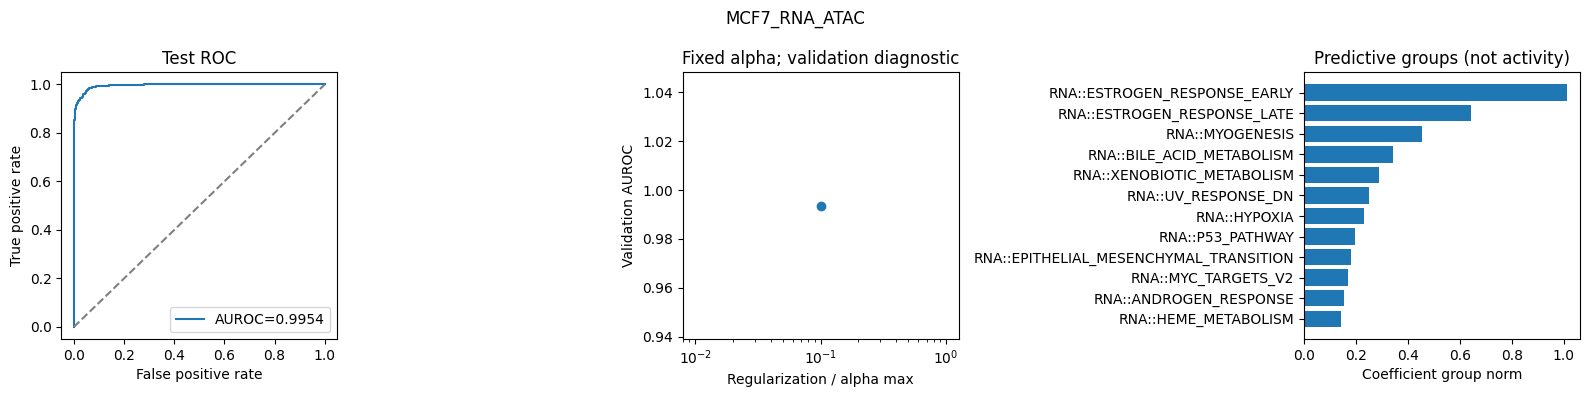

MCF7_RNA_ATAC: finished in 00:01:00. Integrated models completed: 1/2.


,cell_line,model,modality,selected_alpha_ratio,selected_groups,training_AUROC,validation_AUROC,seconds,n_cells,AUROC,average_precision,accuracy,balanced_accuracy,F1_E2,TN,FP,FN,TP,fit_seconds,solver_outer_iterations
0,MCF7,scMKL_style,RNA_ATAC,0.1,27,0.997027,0.993593,57.248631,1204,0.995366,0.996281,0.959302,0.959025,0.962738,522,24,25,633,52.575828,6


In [20]:
display(fit_group_models(MCF7_PATHS,MCF7_TABLES,MANIFESTS["MCF7"],
                         "MCF7",OUTPUT,ARTIFACTS,CONFIG))

## T47D: build biological feature groups and kernels
Completed kernels are reused after checking settings, reference versions and cell splits.
Missing kernels are built by annotating selected peaks and constructing random-feature blocks. It uses no test labels to fit preprocessing or bandwidths.


In [9]:
T47D_PATHS, T47D_TABLES = construct_line(
    BASE,BASELINE,OUTPUT,ARTIFACTS,MANIFESTS["T47D"],"T47D",
    NB08_CONFIG,CONFIG,HALLMARK,REFERENCES,SCAN_CONFIG,cached_run_id=CACHED_KERNEL_RUN_ID)
display(pd.DataFrame([{"modality":m,"kernels":len(t)} for m,t in T47D_TABLES.items()]))

T47D RNA: reusing completed kernels from 20261012T114858_335840Z.
T47D ATAC: reusing completed kernels from 20261012T114858_335840Z.


,modality,kernels
0,RNA,50
1,ATAC,770


## T47D: train one integrated RNA + ATAC model
One fit, fixed alpha ratio 0.1. Validation is diagnostic; test evaluation requires convergence.
The fit checkpoint is saved immediately after the solver returns, before evaluation and plotting.
Completed models/checkpoints are reused when resuming the same new run; a fit interrupted before
the solver returns must restart. No RNA-only or ATAC-only models are trained.


T47D_RNA_ATAC: stage 1/4 — loading saved features for the training cells.
T47D_RNA_ATAC: feature loading took 00:00:02.
T47D_RNA_ATAC: stage 2/4 — fitting one integrated model, alpha ratio 0.1.
[T47D_RNA_ATAC | 00:00:00] Fit started: max 200 outer iterations; up to 50000 inner epochs per subproblem. These are limits, not a completion percentage. ETA unavailable.
[T47D_RNA_ATAC | 00:00:10] #########################
[T47D_RNA_ATAC | 00:00:10] ##### Computing alpha 1/1
[T47D_RNA_ATAC | 00:00:10] #########################
[T47D_RNA_ATAC | 00:00:10] Iter 0: primal 0.4962337017, gap 4.02e-01, 10 groups in subpb (820 left)
[T47D_RNA_ATAC | 00:00:11] Iter 1: primal 0.2271671593, gap 6.60e-02, 16 groups in subpb (820 left)
[T47D_RNA_ATAC | 00:00:11] Iter 2: primal 0.2200320214, gap 1.54e-02, 30 groups in subpb (820 left)
[T47D_RNA_ATAC | 00:00:11] Iter 3: primal 0.2193955034, gap 1.97e-03, 44 groups in subpb (820 left)
[T47D_RNA_ATAC | 00:00:12] Iter 4: primal 0.2193845958, gap 4.22e-04, 44 gro

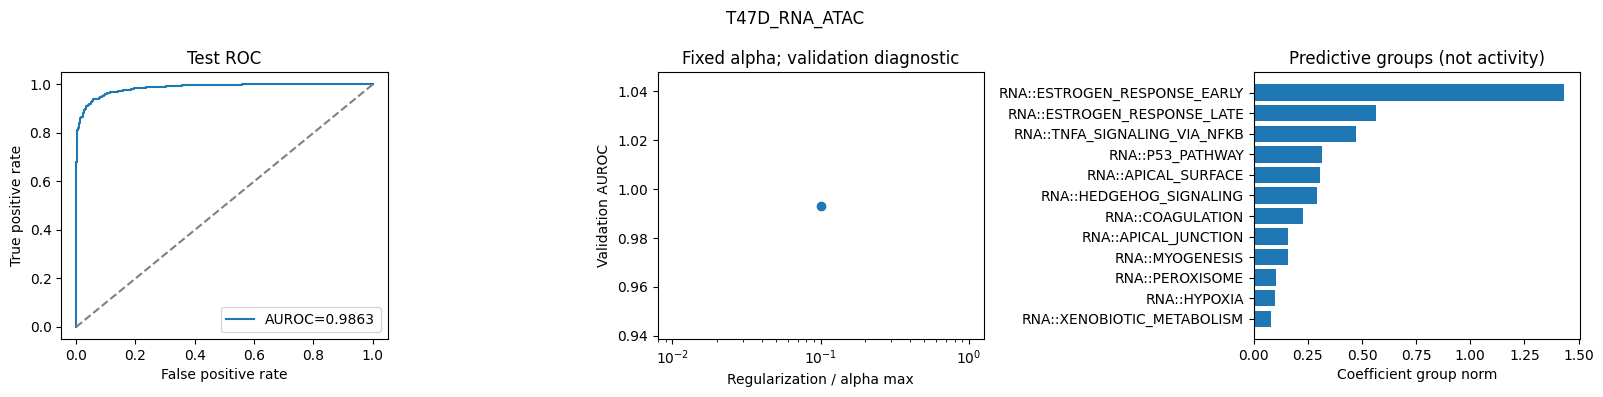

T47D_RNA_ATAC: finished in 00:00:20. Integrated models completed: 2/2.


,cell_line,model,modality,selected_alpha_ratio,selected_groups,training_AUROC,validation_AUROC,seconds,n_cells,AUROC,average_precision,accuracy,balanced_accuracy,F1_E2,TN,FP,FN,TP,fit_seconds,solver_outer_iterations
0,T47D,scMKL_style,RNA_ATAC,0.1,22,0.993743,0.993216,16.533841,1313,0.986276,0.989402,0.938309,0.938839,0.942594,567,33,48,665,12.704726,7


In [10]:
display(fit_group_models(T47D_PATHS,T47D_TABLES,MANIFESTS["T47D"],
                         "T47D",OUTPUT,ARTIFACTS,CONFIG))

## Compare with nb08 and export
The table contains three models per cell line: the two saved nb08 MLP baselines and joint RNA + ATAC. Test IDs/labels must match exactly. Difference tables report joint-model
AUROC/AP minus each reference model; these are descriptive differences, not significance tests.

**Send back the generated results ZIP.** It includes selected regularization, solver status,
group coverage/weights, predictions, plots, input/split checksums and settings.
Large kernel arrays, random maps and coefficient checkpoints remain in data/processed/nb09/RUN_ID/.

A higher integrated score is not guaranteed, especially given nb08's near-ceiling RNA AUROC.
Use the baseline comparison and validation/test gap descriptively; model family and inputs both change.


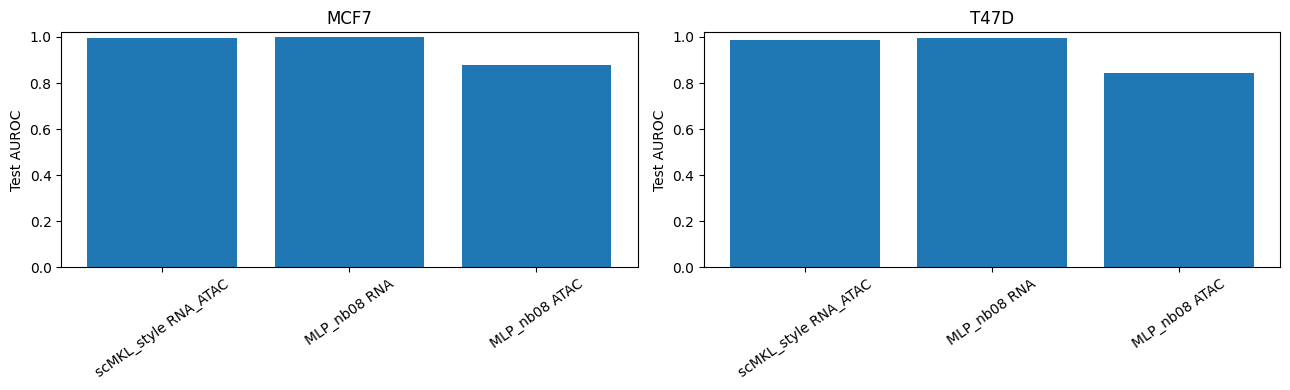

Share: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb09_20261012T114858_335840Z.zip


,cell_line,model,modality,AUROC,average_precision,balanced_accuracy,F1_E2
0,MCF7,scMKL_style,RNA_ATAC,0.995366,0.996281,0.959025,0.962738
1,MCF7,MLP_nb08,RNA,0.998052,0.998500,0.977476,0.978528
2,MCF7,MLP_nb08,ATAC,0.878609,0.894355,0.795865,0.816327
3,T47D,scMKL_style,RNA_ATAC,0.986276,0.989402,0.938839,0.942594
4,T47D,MLP_nb08,RNA,0.996933,0.997737,0.973384,0.976290
5,T47D,MLP_nb08,ATAC,0.843777,0.852236,0.751896,0.793171


Results archive: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb09_20261012T114858_335840Z.zip


In [11]:
comparison, RESULTS_ZIP = export_comparison(BASE,BASELINE,OUTPUT,MANIFESTS,CONFIG)
display(comparison[["cell_line","model","modality","AUROC","average_precision",
                    "balanced_accuracy","F1_E2"]])
print("Results archive:",RESULTS_ZIP)


### Training progress and timing
Training prints stages 1/4 through 4/4: feature loading, solver fitting, evaluation and saving.
A completed-model counter shows 0/2, 1/2 or 2/2 as applicable. Native solver lines are timestamped
with elapsed time and report **outer iteration**, objective and **duality gap** (a convergence measure,
not prediction loss or AUROC). Outer iteration numbers from celer start at zero.

The solver has a limit of 200 outer iterations and 50,000 inner coordinate-descent epochs per
subproblem. These are upper bounds, not a schedule. The installed celer build may not expose
inner epochs; they are recorded only if the solver actually prints them. No artificial epoch count
is invented. A final outer-iteration count is saved when exposed by the estimator.

During fitting, a best-effort elapsed-time message is emitted every 30 seconds. Native work holding
Python's interpreter lock or slow Drive writes can delay updates. **Solver time remaining is unknown**:
iteration duration and convergence vary, so iteration/max-iteration is not a completion percentage.
Motif scanning and kernel construction show count-based progress and a rough remaining-time estimate.

Each model saves solver_progress.jsonl and live_status.json files in the run's results directory;
fit duration and final outer-iteration count are also saved with its checkpoint and metrics.
Logs are observational, not intermediate model checkpoints. A disconnect during a solver call still
requires that fit to restart. This logging update does not alter model settings or fit additional models.

### Optional download
The ZIP is already saved on Drive. Turn on the switch below to download it through Colab.
A changed configuration requires a new run. Kernel arrays and models are not included in the ZIP.
For a disconnect, reopen this notebook, set RESUME_RUN_ID to the NEW integrated run ID and run all.
Keep the old cached-kernel run folder: the new model may reference its saved feature maps.


In [12]:
DOWNLOAD_RESULTS=False
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(RESULTS_ZIP))
